# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |
| Apêndice | A | Painel-resumo do estudo; catálogo de todas as figuras e tabelas (numeradas por parte: Figura II.3, Tabela III.5) e exportação para `fig/`, `tab/` e `tab/ed2_tabelas.xlsx` |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.4);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos; **`CORES_DESFECHO`** usa matizes que não repetem os dos grupos (a camada de visualização completa, com estilo, rótulos e funções de figura e tabela, está na seção 1.2);
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
# Desfechos são outra entidade: nenhuma cor de desfecho repete a cor de um grupo (validação na seção 1.2)
CORES_DESFECHO = {'Homologação': '#CC79A7', 'Mérito': '#4B3F8F', 'Sem mérito': '#B8461B',
                  'Redistribuição': '#7F7F7F', 'Ativo': '#C8C8C8'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    try:
        if valor is None or pd.isna(valor):
            return '–'
    except (TypeError, ValueError):
        pass
    return f'{float(valor):,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Camada de visualização

Todas as figuras e tabelas do notebook passam por uma **camada comum**, definida aqui uma única vez. O objetivo é que qualquer gráfico possa ser lido sem consultar o código: cada figura e cada tabela tem **número** (por parte: Figura II.3, Tabela III.5), **título** que enuncia o achado ou a pergunta, **eixos com unidade**, **n** de cada grupo, a **fonte** e, quando há teste, o **resultado do teste no próprio gráfico** (estatística, valor-p e tamanho de efeito). Tudo é numerado e registrado num catálogo, reproduzido no Apêndice, e exportado: figuras em `fig/<id>.png` (e `.svg`), tabelas em `tab/<id>.csv` (separador `;`, vírgula decimal, UTF-8 com BOM, que o Excel abre corretamente).

| Elemento | Regra adotada |
|---|---|
| Cor | identifica uma **entidade**, e só uma: os três grupos têm as cores fixas de Okabe-Ito; os desfechos usam outros matizes (nenhum repete a cor de um grupo); "ativo/censurado" é cinza claro. Mapas de calor usam uma escala **sequencial** de um só matiz (magnitude, como o V de Cramér) ou **divergente** com dois matizes opostos e meio cinza (sinal, como os resíduos ajustados) |
| Daltonismo | as paletas são verificadas por simulação (Machado, Oliveira e Fernandes, 2009, protanopia e deuteranopia de severidade 1,0) e distância perceptual ΔE no espaço OKLab (×100): alvo ≥ 8 entre cores vizinhas, piso de 15 sem simulação. Além da cor, há sempre um segundo canal: legenda, rótulo direto ou posição |
| Forma | barras **verticais** e *boxplots*; nunca dois eixos verticais com escalas diferentes; nunca histograma em escala logarítmica; Kaplan-Meier sempre como S(t) descendente, com IC e número em risco |
| Rótulos | nomes legíveis (não os nomes das colunas), rótulos longos quebrados em linhas, ordem fixa dos grupos (Controle, Presencial, Remota) e dos desfechos; legenda sempre que há duas ou mais séries, e rótulos diretos seletivos (não um número em cada ponto) |
| Números | padrão brasileiro nos eixos, rótulos e tabelas: vírgula decimal, ponto de milhar, valor-p como "< 0,001" |

As funções disponíveis para as demais partes:

- **`figura(fig, id, titulo, secao=..., fonte=..., nota=...)`**: numera, põe título e fonte, converte os eixos para vírgula decimal, salva PNG e SVG e registra no catálogo;
- **`tabela(df, id, titulo, secao=..., nota=..., formatos=..., destaque=...)`**: exibe a tabela formatada (legenda numerada, pt-BR, valor-p formatado, índice oculto quando não tem significado, linhas significativas destacadas), exporta CSV e registra no catálogo;
- **auxiliares de gráfico**: `barras_verticais`, `barras_agrupadas`, `barras_empilhadas`, `boxplot_grupos`, `plot_km`, `anotar_n`, `anotar_teste`, `texto_teste`, `quebra`, `eixo_pct`, `eixo_meses`, `legenda_abaixo`;
- **rótulos**: `ROTULOS` (variável → rótulo com unidade), `ROTULO_DESFECHO`, `rotulo_grupo(g, com_n=True)` → "Controle (n = 313)".

In [3]:
import textwrap
from matplotlib.offsetbox import AnchoredText
from matplotlib.ticker import ScalarFormatter, FuncFormatter
from IPython.display import HTML

TAB = RAIZ / 'tab'
TAB.mkdir(parents=True, exist_ok=True)
FONTE_PADRAO = ('Fonte: elaboração própria a partir da planilha de controle dos processos do 4º JEC de Natal/RN '
                '(atualização de 07/10/2026).')

# ---------------------------------------------------------------- rótulos legíveis (com unidade)
ROTULOS = {
    'tempo': 'Tempo até a sentença ou a censura (dias)',
    'tempo_sentenca': 'Tempo até a sentença (dias)',
    'tempo_pos': 'Tempo até a sentença ou a censura (dias; zeros = 0,5)',
    'followup': 'Seguimento máximo possível (dias)',
    'dias': 'Dias desde a distribuição',
    'S': 'Proporção ainda sem sentença, S(t)',
    'F': 'Proporção acumulada de sentenças',
    'CIF': 'Incidência acumulada',
    'grupo': 'Grupo (rito sorteado)',
    'tipo_desfecho': 'Tipo de desfecho',
    'mes_distribuicao': 'Mês de distribuição (2026)',
    'dt_distribuicao': 'Data de distribuição (2026)',
    'dt_sentenca': 'Data da sentença (2026)',
    'ordem_chegada': 'Ordem de chegada (1 a 938)',
    'dia_estudo': 'Dia do estudo (desde 01/01/2026)',
    'n': 'Número de processos',
    'pct': 'Processos (%)',
    'acordo': 'Acordo (na AC ou fora dela)',
    'acordo_ac': 'Acordo na audiência de conciliação',
    'acordo_fora': 'Acordo fora da audiência',
    'ac_realizada': 'Audiência de conciliação realizada',
    'tecnica': 'Técnica de conciliação',
    'hibrida': 'Audiência híbrida',
    'origem_externa': 'Processo de outro órgão ou ano anterior',
}
ROTULO_DESFECHO = {'Homologação': 'Homologação de acordo', 'Mérito': 'Sentença de mérito',
                   'Sem mérito': 'Extinção sem mérito', 'Redistribuição': 'Redistribuição (Decisão)',
                   'Ativo': 'Em tramitação (censurado)'}
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#3D3D3D', 'Redistribuição': CORES_DESFECHO['Redistribuição'],
                'Ativo (censurado)': CORES_DESFECHO['Ativo']}
CINZA = '#A6A6A6'                       # séries de contexto (ênfase = 1 cor + cinza)
DESTAQUE = '#D55E00'                    # referência/limiar externo (linha de referência, valor divulgado)
MESES_PT = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']


def rotulo_grupo(g, com_n=False, longo=False, base=None, quebrar=False):
    """'Controle' | 'Controle (n = 313)' | rótulo longo; `base` = DataFrame de onde contar n (padrão: dados)."""
    nome = ROTULO_GRUPO.get(g, str(g)) if longo else str(g)
    if com_n:
        base = base if base is not None else globals().get('dados')
        n = int((base['grupo'] == g).sum()) if base is not None else None
        if n is not None:
            nome = f'{nome}\n(n = {fmt_br(n, 0)})' if quebrar else f'{nome} (n = {fmt_br(n, 0)})'
    return nome


def quebra(texto, largura=16):
    """Quebra rótulos longos em linhas ('Extinção do Feito com Homologação do Acordo' → 3 linhas)."""
    return '\n'.join(textwrap.fill(parte, largura, break_long_words=False) for parte in str(texto).split('\n'))


def fmt_p(p, casas=3):
    """Valor-p em pt-BR: '< 0,001' ou '0,034'; ausente → '–'."""
    try:
        if p is None or pd.isna(p):
            return '–'
    except (TypeError, ValueError):
        return str(p)
    limite = 10 ** -casas
    return f'< {fmt_br(limite, casas)}' if p < limite else fmt_br(p, casas)


def fmt_int(x):
    return fmt_br(x, 0)


# ---------------------------------------------------------------- paletas sequencial e divergente
SEQ = mpl.colors.LinearSegmentedColormap.from_list('ed2_seq', ['#F4F6F8', '#A9B8C6', '#5B7389', '#2B3A4A'])
DIV = mpl.colors.LinearSegmentedColormap.from_list('ed2_div', ['#2166AC', '#92C5DE', '#F2F2F2', '#F4A582', '#B2182B'])
for _mapa in (SEQ, DIV):
    _mapa.set_bad('#FFFFFF')

# ---------------------------------------------------------------- estilo matplotlib
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 8, 'axes.labelsize': 10, 'axes.labelcolor': TINTA,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.fontsize': 9, 'legend.title_fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8c8c8c', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'axes.formatter.limits': (-5, 6), 'axes.formatter.use_mathtext': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
    'boxplot.medianprops.color': TINTA, 'image.cmap': 'ed2_seq' if 'ed2_seq' in mpl.colormaps else 'viridis',
})
if 'ed2_seq' not in mpl.colormaps:
    mpl.colormaps.register(SEQ); mpl.colormaps.register(DIV)
plt.rcParams['image.cmap'] = 'ed2_seq'
sns.set_palette(list(CORES_GRUPO.values()))


class FormatadorBR(ScalarFormatter):
    """Rótulos de eixo com vírgula decimal e ponto de milhar (0,25 · 1.200)."""
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        try:
            v = float(s.replace('−', '-'))
        except ValueError:
            return s.replace('.', ',')
        if abs(v) >= 1000 and float(v).is_integer():
            return fmt_br(v, 0).replace('-', '−')
        return s.replace('.', ',')


def aplicar_br(fig):
    """Troca o formatador padrão de todos os eixos numéricos da figura pelo formatador pt-BR."""
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is ScalarFormatter:
                eixo.set_major_formatter(FormatadorBR())


def eixo_pct(ax, eixo='y', casas=0, escala=100):
    """Eixo em percentual pt-BR. `escala=100` quando os dados estão em proporção (0–1)."""
    f = FuncFormatter(lambda v, _: fmt_br(v * escala, casas) + '%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)


def eixo_meses(ax, eixo='x', formato='mes'):
    """Eixo de datas com meses em português ('jan', 'fev', …) ou dia/mês ('15/03')."""
    alvo = ax.xaxis if eixo == 'x' else ax.yaxis
    if formato == 'mes':
        alvo.set_major_locator(mpl.dates.MonthLocator())
        alvo.set_major_formatter(FuncFormatter(lambda v, _: MESES_PT[mpl.dates.num2date(v).month - 1]))
    else:
        alvo.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))


def legenda_abaixo(ax, ncol=3, dy=-0.16, **kw):
    """Legenda centralizada abaixo do eixo (não disputa espaço com os dados)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, dy), ncol=ncol, **kw)


# ---------------------------------------------------------------- catálogo, figuras e tabelas
CATALOGO = {}          # (tipo, id) -> registro
TABELAS_EXPORT = {}    # id -> DataFrame exportado (para a pasta de trabalho do Apêndice)
_CONTADOR = {}
PARTE_ATUAL = 'I'
_ROMANO = {1: 'I', 2: 'II', 3: 'III', 4: 'IV', 5: 'V', 6: 'VI', 7: 'VII', 8: 'VIII', 99: 'A'}


def _parte_de(secao):
    if secao is None:
        return PARTE_ATUAL
    try:
        return _ROMANO.get(int(str(secao).split('.')[0]), str(secao).split('.')[0])
    except ValueError:
        return str(secao)


def _registra(tipo, id_, titulo, secao, arquivo):
    chave = (tipo, id_)
    parte = _parte_de(secao)
    if chave in CATALOGO:
        numero = CATALOGO[chave]['Número']
    else:
        _CONTADOR[(tipo, parte)] = _CONTADOR.get((tipo, parte), 0) + 1
        numero = f'{parte}.{_CONTADOR[(tipo, parte)]}'
    CATALOGO[chave] = {'Tipo': tipo, 'Número': numero, 'id': id_, 'Título': titulo,
                       'Seção': '' if secao is None else str(secao), 'Arquivo': arquivo}
    return numero


def ref(id_, tipo='Figura'):
    """'Figura II.3' a partir do id (para textos gerados em código)."""
    reg = CATALOGO.get((tipo, id_))
    return f'{tipo} {reg["Número"]}' if reg else f'{tipo} ?'


def _quebrar_largura(texto, largura_pol, tamanho):
    n = max(40, int(largura_pol * 72 / (tamanho * 0.53)))
    return '\n'.join(textwrap.fill(par, n, break_long_words=False) if par else '' for par in str(texto).split('\n'))


def figura(fig, id, titulo, secao=None, fonte=FONTE_PADRAO, nota=None, svg=True, mostrar=True):
    """Numera, titula, põe fonte/nota, aplica pt-BR aos eixos, salva fig/<id>.png (+ .svg) e cataloga.

    O título (`titulo`) deve enunciar o achado ou a pergunta; os títulos dos painéis (ax.set_title)
    dizem o que cada painel mostra. Não use plt.suptitle: esta função é dona do título da figura.
    """
    numero = _registra('Figura', id, titulo, secao, f'fig/{id}.png')
    aplicar_br(fig)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    if fig.get_layout_engine() is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            fig.tight_layout()
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    W, H = fig.get_size_inches()
    x0 = caixa.x0 / W
    largura = caixa.width
    fig.text(x0, (caixa.y1 + 0.12) / H, _quebrar_largura(f'Figura {numero} — {titulo}', largura, 12),
             ha='left', va='bottom', fontsize=12, fontweight='bold', color=TINTA)
    rodape = fonte or ''
    if nota:
        rodape = f'{rodape}\nNota: {nota}' if rodape else f'Nota: {nota}'
    if rodape:
        fig.text(x0, (caixa.y0 - 0.10) / H, _quebrar_largura(rodape, largura, 8.5),
                 ha='left', va='top', fontsize=8.5, color=TINTA_2, linespacing=1.35)
    fig.savefig(FIG / f'{id}.png', bbox_inches='tight', pad_inches=0.15)
    if svg:
        fig.savefig(FIG / f'{id}.svg', bbox_inches='tight', pad_inches=0.15)
    if mostrar:
        display(fig)
    plt.close(fig)


def _e_coluna_p(nome):
    s = str(nome[-1] if isinstance(nome, tuple) else nome).strip().lower()
    return (s in {'p', 'valor-p', 'p-valor', 'valor p', 'p holm', 'p bh', 'p_holm'}
            or s.startswith(('p ', 'p(', 'p_', 'p-', 'valor-p', 'valor p')))


def _na(v):
    try:
        return v is None or bool(pd.isna(v))
    except (TypeError, ValueError):
        return False


def _formatador(serie, nome, formato, casas):
    if callable(formato):
        return lambda v: '–' if _na(v) else formato(v)
    if formato == 'p' or (formato is None and _e_coluna_p(nome)):
        return fmt_p
    if formato == 'pct':                      # proporção 0–1 → 12,3%
        return lambda v: '–' if _na(v) else pct_br(v, 1)
    if formato == '%':                        # já em percentual → 12,3%
        return lambda v: '–' if _na(v) else fmt_br(v, 1) + '%'
    if formato == 'int':
        return lambda v: '–' if _na(v) else fmt_br(v, 0)
    if formato == 'texto':
        return lambda v: '–' if _na(v) else str(v)
    if isinstance(formato, int) and not isinstance(formato, bool):
        return lambda v, c=formato: '–' if _na(v) else fmt_br(v, c)
    s = serie.dropna()
    if pd.api.types.is_bool_dtype(serie) or (len(s) and s.map(lambda v: isinstance(v, (bool, np.bool_))).all()):
        return lambda v: '–' if _na(v) else ('Sim' if bool(v) else 'Não')
    if pd.api.types.is_datetime64_any_dtype(serie):
        return lambda v: '–' if _na(v) else pd.Timestamp(v).strftime('%d/%m/%Y')
    if pd.api.types.is_numeric_dtype(serie):
        valores = pd.to_numeric(s, errors='coerce').astype(float)
        valores = valores[np.isfinite(valores)]
        if '%' in str(nome):
            return lambda v: '–' if _na(v) else fmt_br(v, 1)
        if len(valores) and np.allclose(valores, np.round(valores)):
            return lambda v: '–' if _na(v) else fmt_br(v, 0)
        return lambda v, c=casas: '–' if _na(v) else fmt_br(v, c)

    def _obj(v):
        if _na(v):
            return '–'
        if isinstance(v, (bool, np.bool_)):
            return 'Sim' if v else 'Não'
        if isinstance(v, (float, np.floating)):
            return fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, casas)
        if isinstance(v, (int, np.integer)):
            return fmt_br(v, 0)
        if isinstance(v, pd.Timestamp):
            return v.strftime('%d/%m/%Y')
        return str(v)
    return _obj


def _limpa_dtypes(df):
    """Nullable (Int64, Float64, boolean, string) → tipos simples, para formatação e exportação sem ruído."""
    saida = df.copy()
    for c in saida.columns:
        dt = saida[c].dtype
        if isinstance(dt, pd.CategoricalDtype):
            saida[c] = saida[c].astype(object)
        elif str(dt) in ('Int64', 'Int32', 'Float64', 'Float32', 'UInt8', 'Int8', 'Int16'):
            saida[c] = saida[c].astype('float64')
        elif str(dt) == 'boolean':
            saida[c] = saida[c].astype(object).where(saida[c].notna(), None)
        elif str(dt) in ('string', 'str'):
            saida[c] = saida[c].astype(object)
    return saida


def tabela(df, id, titulo, secao=None, nota=None, fonte=FONTE_PADRAO, formatos=None, destaque=None,
           casas=2, indice=None, alfa=0.05, gradiente=None, exportar=True, mostrar=True):
    """Exibe `df` como tabela numerada (Tabela II.4 — título), em pt-BR, exporta tab/<id>.csv e cataloga.

    formatos: {coluna: casas (int) | 'p' | 'pct' (proporção→%) | '%' (já em %) | 'int' | 'texto' | função}.
              Sem formato, colunas cujo nome começa com 'p' + separador ('p', 'p Holm', 'p (exato)') viram
              valor-p; inteiros ficam sem casas; demais números com `casas`.
    destaque: nome de uma coluna de valores-p (linhas com p < alfa em destaque), máscara booleana
              ou função df -> máscara.
    indice:   None = oculta se for um RangeIndex sem significado; True/False força.
    gradiente: {'mapa': SEQ | DIV, 'colunas': [...], 'vmin': .., 'vmax': ..} para mapas de calor em tabela.
    """
    if isinstance(df, pd.Series):
        df = df.to_frame()
    bruto = df.copy()
    numero = _registra('Tabela', id, titulo, secao, f'tab/{id}.csv')
    if indice is None:
        indice = not (isinstance(bruto.index, pd.RangeIndex) and bruto.index.name is None)
    if indice and not isinstance(bruto.index, pd.MultiIndex) and not isinstance(bruto.columns, pd.MultiIndex):
        # índice simples com significado vira a 1ª coluna (sem a linha extra do nome do índice)
        nome_ind = bruto.index.name if bruto.index.name is not None else ''
        bruto = bruto.reset_index(names=[nome_ind] if nome_ind not in bruto.columns else ['_' + str(nome_ind)])
        indice = False
    limpo = _limpa_dtypes(bruto)
    if isinstance(limpo.index, pd.CategoricalIndex):
        limpo.index = limpo.index.astype(object)
    formatos = formatos or {}
    fmt = {c: _formatador(limpo[c], c, formatos.get(c), casas) for c in limpo.columns}
    sty = limpo.style.format(fmt, na_rep='–', escape='html')
    sty = sty.format_index(lambda v: '–' if _na(v) else (fmt_br(v, 0) if isinstance(v, (int, np.integer)) and abs(v) >= 1000
                                                          else (pd.Timestamp(v).strftime('%d/%m/%Y') if isinstance(v, pd.Timestamp)
                                                                else str(v))), escape='html')
    sty = sty.set_caption(f'Tabela {numero} — {titulo}')
    sty = sty.set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; '
                                         'color: #1a1a1a; padding: 4px 0 6px 0;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #f3f3f3; color: #1a1a1a; '
                                    'padding: 4px 8px; border-bottom: 1px solid #bbb;'},
        {'selector': 'th.row_heading', 'props': 'text-align: left; background-color: #fafafa;'},
        {'selector': 'td', 'props': 'text-align: right; padding: 3px 8px; font-variant-numeric: tabular-nums;'},
        {'selector': '', 'props': 'border-collapse: collapse; margin-bottom: 2px;'},
    ])
    texto = [c for c in limpo.columns if limpo[c].dtype == object
             and not limpo[c].dropna().map(lambda v: isinstance(v, (int, float, np.number, bool, np.bool_))).all()]
    if texto:
        sty = sty.set_properties(subset=texto, **{'text-align': 'left'})
    if gradiente:
        sty = sty.background_gradient(cmap=gradiente.get('mapa', SEQ), subset=gradiente.get('colunas'),
                                      vmin=gradiente.get('vmin'), vmax=gradiente.get('vmax'), axis=None)
    if destaque is not None:
        if isinstance(destaque, str):
            mascara = pd.to_numeric(bruto[destaque], errors='coerce').lt(alfa).to_numpy()
        elif callable(destaque):
            mascara = np.asarray(destaque(bruto), dtype=bool)
        else:
            mascara = np.asarray(destaque, dtype=bool)
        css = 'background-color: #EAF0F6; font-weight: 600;'
        sty = sty.apply(lambda d: pd.DataFrame(np.where(np.broadcast_to(mascara[:, None], d.shape), css, ''), index=d.index, columns=d.columns),
                        axis=None)
    if not indice:
        sty = sty.hide(axis='index')
    if mostrar:
        display(sty)
        rodape = []
        if nota:
            rodape.append(f'Nota: {nota}')
        if fonte:
            rodape.append(fonte)
        if rodape:
            display(HTML('<div style="font-size: 0.85em; color: #555; margin: 2px 0 14px 0; max-width: 60em;">'
                         + '<br>'.join(rodape) + '</div>'))
    if exportar:
        exp = limpo.copy()
        if isinstance(exp.columns, pd.MultiIndex):
            exp.columns = [' | '.join(str(x) for x in c if str(x) != '') for c in exp.columns]
        if indice:
            exp = exp.reset_index()
        exp.columns = [str(c) for c in exp.columns]
        exp.to_csv(TAB / f'{id}.csv', sep=';', decimal=',', encoding='utf-8-sig', index=False)
        TABELAS_EXPORT[id] = exp


# ---------------------------------------------------------------- auxiliares de gráfico
def anotar_n(ax, posicoes, ns, onde='topo', tamanho=8.5):
    """Escreve 'n = …' sobre cada posição do eixo x (topo ou base da área do gráfico)."""
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    y, va = (0.985, 'top') if onde == 'topo' else (0.015, 'bottom')
    for x, n in zip(posicoes, ns):
        ax.text(x, y, f'n = {fmt_br(n, 0)}', transform=trans, ha='center', va=va, fontsize=tamanho, color=TINTA_2)


def texto_teste(teste, estatistica=None, p=None, efeito=None, extra=None):
    """Monta o texto padrão do resultado: 'Kruskal-Wallis\\nH = 3,21; p = 0,201\\nε² = 0,002 [0,000; 0,010]'."""
    linhas = [teste]
    meio = []
    if estatistica:
        meio.append(estatistica)
    if p is not None:
        meio.append(f'p {"< 0,001" if p < 0.001 else "= " + fmt_p(p)}')
    if meio:
        linhas.append('; '.join(meio))
    if efeito:
        linhas.append(efeito)
    if extra:
        linhas.append(extra)
    return '\n'.join(linhas)


def anotar_teste(ax, texto, loc='upper right', tamanho=8.5):
    """Caixa com o resultado do teste dentro do gráfico (estatística, p, efeito)."""
    caixa = AnchoredText(texto, loc=loc, prop=dict(size=tamanho, color=TINTA), frameon=True, pad=0.4, borderpad=0.6)
    caixa.patch.set_boxstyle('round,pad=0.3,rounding_size=0.2')
    caixa.patch.set_facecolor((1, 1, 1, 0.92))
    caixa.patch.set_edgecolor('#bdbdbd')
    caixa.patch.set_linewidth(0.8)
    ax.add_artist(caixa)
    return caixa


def _cor_texto(cor):
    r, g, b = mpl.colors.to_rgb(cor)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else TINTA


def barras_verticais(ax, categorias, valores, cores=None, rotular=True, fmt=None, erro=None, largura=0.6,
                     quebrar=14, ylabel=None, xlabel=None, ns=None, ymax=None):
    """Barras verticais com rótulo do valor no topo (rotular=True | 'max' | False) e IC opcional (erro=(lo, hi))."""
    categorias = list(categorias)
    valores = np.asarray(valores, dtype=float)
    x = np.arange(len(categorias))
    if cores is None:
        cores = [CORES_GRUPO.get(c, CORES_GRUPO['Controle']) if c in CORES_GRUPO else '#5B7389' for c in categorias]
    elif isinstance(cores, dict):
        cores = [cores.get(c, CINZA) for c in categorias]
    elif isinstance(cores, str):
        cores = [cores] * len(categorias)
    barras = ax.bar(x, valores, width=largura, color=cores, edgecolor='white', linewidth=1)
    topo = valores.copy()
    if erro is not None:
        lo, hi = (np.asarray(e, dtype=float) for e in erro)
        ax.errorbar(x, valores, yerr=[valores - lo, hi - valores], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
        topo = np.maximum(topo, hi)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    if rotular:
        alvo = range(len(x)) if rotular is True else [int(np.nanargmax(valores))]
        for i in alvo:
            ax.annotate(fmt(valores[i]), (x[i], topo[i]), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, color=TINTA)
    rot = [quebra(c, quebrar) for c in categorias]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, ymax if ymax is not None else np.nanmax(topo) * 1.15 if np.nanmax(topo) > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return barras


def barras_agrupadas(ax, tab, cores=None, rotular=False, fmt=None, largura_total=0.8, quebrar=14,
                     ylabel=None, xlabel=None, legenda=True, erro=None, titulo_legenda=None):
    """Barras verticais agrupadas: linhas de `tab` no eixo x, colunas = séries (cores por série)."""
    cores = cores or CORES_GRUPO
    series = list(tab.columns)
    x = np.arange(len(tab.index))
    w = largura_total / len(series)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    topo_max = 0
    for j, s in enumerate(series):
        v = tab[s].to_numpy(dtype=float)
        pos = x + (j - (len(series) - 1) / 2) * w
        ax.bar(pos, v, width=w, color=cores.get(s, CINZA), label=str(s), edgecolor='white', linewidth=1)
        topo = v
        if erro is not None and s in erro:
            lo, hi = (np.asarray(e, dtype=float) for e in erro[s])
            ax.errorbar(pos, v, yerr=[v - lo, hi - v], fmt='none', ecolor=TINTA, elinewidth=1, capsize=3)
            topo = np.maximum(v, hi)
        topo_max = max(topo_max, np.nanmax(topo))
        if rotular:
            for xi, vi, ti in zip(pos, v, topo):
                ax.annotate(fmt(vi), (xi, ti), xytext=(0, 2), textcoords='offset points', ha='center',
                            va='bottom', fontsize=8, color=TINTA)
    ax.set_xticks(x, [quebra(c, quebrar) for c in tab.index])
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, topo_max * 1.15 if topo_max > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if legenda and len(series) > 1:
        ax.legend(title=titulo_legenda)


def barras_empilhadas(ax, tab_prop, cores=None, rotulo_min=0.06, fmt=None, largura=0.6, quebrar=14,
                      ylabel='Processos (%)', ns=None, legenda=True, rotulos_serie=None, ncol_legenda=None):
    """Barras verticais 100% empilhadas (linhas = barras; colunas = partes, em proporção 0–1).

    Rótulo dentro do segmento só quando cabe (≥ rotulo_min); separação por um fio branco (sem contorno).
    """
    cores = cores or CORES_DESFECHO
    fmt = fmt or (lambda v: pct_br(v, 0))
    x = np.arange(len(tab_prop.index))
    base = np.zeros(len(x))
    for parte in tab_prop.columns:
        v = tab_prop[parte].fillna(0).to_numpy(dtype=float)
        nome = (rotulos_serie or {}).get(parte, parte)
        ax.bar(x, v, bottom=base, width=largura, color=cores.get(parte, CINZA), label=nome,
               edgecolor='white', linewidth=1.2)
        for xi, b, vi in zip(x, base, v):
            if vi >= rotulo_min:
                ax.text(xi, b + vi / 2, fmt(vi), ha='center', va='center', fontsize=8.5,
                        color=_cor_texto(cores.get(parte, CINZA)))
        base += v
    rot = [quebra(c, quebrar) for c in tab_prop.index]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.set_ylim(0, 1)
    eixo_pct(ax)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legenda:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='center left', bbox_to_anchor=(1.01, 0.5))


def boxplot_grupos(ax, df, valor, grupo='grupo', ordem=None, cores=None, pontos=True, rotulo_mediana=True,
                   ylabel=None, xlabel=None, com_n=True, largura=0.5, quebrar=14, semente=SEMENTE, tam_ponto=6):
    """Boxplot vertical por grupo, com pontos (jitter), mediana rotulada e n no rótulo do eixo."""
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    amostras = [pd.to_numeric(df.loc[df[grupo] == g, valor], errors='coerce').dropna().astype(float).to_numpy()
                for g in ordem]
    bp = ax.boxplot(amostras, positions=np.arange(len(ordem)), widths=largura, patch_artist=True,
                    showfliers=not pontos, medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=TINTA_2, lw=1), capprops=dict(color=TINTA_2, lw=1),
                    boxprops=dict(lw=1.2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
    for caixa, g in zip(bp['boxes'], ordem):
        cor = cores.get(g, CINZA)
        caixa.set_facecolor(mpl.colors.to_rgba(cor, 0.22))
        caixa.set_edgecolor(cor)
    if pontos:
        rng = np.random.default_rng(semente)
        for i, (a, g) in enumerate(zip(amostras, ordem)):
            ax.scatter(i + rng.uniform(-largura * 0.35, largura * 0.35, len(a)), a, s=tam_ponto,
                       color=cores.get(g, CINZA), alpha=0.35, lw=0, zorder=1)
    if rotulo_mediana:
        for i, a in enumerate(amostras):
            if len(a):
                ax.annotate(f'Md = {fmt_br(np.median(a), 0 if np.median(a).is_integer() else 1)}',
                            (i + largura / 2, np.median(a)), xytext=(4, 0), textcoords='offset points',
                            va='center', ha='left', fontsize=8.5, color=TINTA)
    rot = [quebra(str(g), quebrar) for g in ordem]
    if com_n:
        rot = [f'{r}\n(n = {fmt_br(len(a), 0)})' for r, a in zip(rot, amostras)]
    ax.set_xticks(np.arange(len(ordem)), rot)
    ax.set_xlim(-0.6, len(ordem) - 0.4)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return amostras


def plot_km(ax, df, tempo='tempo', evento='evento', grupo='grupo', ordem=None, cores=None, ic=True, censuras=True,
            tabela_risco=True, passo=30, tmax=None, rotulos=None, mediana=True, xlabel=None, ylabel=None,
            legenda=True):
    """Kaplan-Meier S(t) descendente por grupo: IC 95%, marcas de censura, número em risco sob o eixo.

    Os rótulos da legenda trazem n e a mediana (ou '> tmax' quando a curva não cruza 0,5).
    Devolve {grupo: KaplanMeierFitter}.
    """
    if grupo is None:
        df = df.assign(_todos='Todos')
        grupo, ordem, cores = '_todos', ['Todos'], {'Todos': TINTA}
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    T_all = df[tempo].astype(float)
    tmax = tmax or float(T_all.max())
    kms = {}
    for g in ordem:
        sub = df[df[grupo] == g]
        T, E = sub[tempo].astype(float), sub[evento].astype(float)
        km = KaplanMeierFitter(label=str(g)).fit(T, E)
        kms[g] = km
        sf = km.survival_function_.iloc[:, 0]
        nome = (rotulos or {}).get(g, str(g))
        nome = f'{nome} (n = {fmt_br(len(sub), 0)}'
        if mediana:
            md_ = km.median_survival_time_
            nome += f'; mediana = {fmt_br(md_, 0)} dias)' if np.isfinite(md_) else f'; mediana > {fmt_br(tmax, 0)} dias)'
        else:
            nome += ')'
        cor = cores.get(g, CINZA)
        ax.step(sf.index, sf.values, where='post', color=cor, lw=2, label=nome)
        if ic:
            ci = km.confidence_interval_survival_function_
            ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=cor, alpha=0.13, lw=0)
        if censuras:
            tc = np.unique(T[E == 0])
            if len(tc):
                ax.plot(tc, km.survival_function_at_times(tc).to_numpy(), ls='', marker='|', ms=6, mew=1, color=cor)
    ax.set_xlim(0, tmax * 1.01)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(0, tmax + 1, passo))
    ax.grid(axis='both', visible=True)
    ax.set_xlabel(xlabel or ROTULOS['dias'])
    ax.set_ylabel(ylabel or ROTULOS['S'])
    if legenda:
        ax.legend(loc='upper right')
    if tabela_risco:
        tempos = np.arange(0, tmax + 1, passo)
        ax.annotate('Número em risco', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46),
                    textcoords='offset points', ha='left', va='top', fontsize=8.5, fontweight='bold', color=TINTA)
        for i, g in enumerate(ordem):
            sub = df[df[grupo] == g]
            T = sub[tempo].astype(float).to_numpy()
            dy = -60 - 12 * i
            ax.annotate('■', xy=(0, 0), xycoords='axes fraction', xytext=(-6, dy), textcoords='offset points',
                        ha='right', va='top', fontsize=8.5, color=cores.get(g, CINZA))
            ax.annotate(str((rotulos or {}).get(g, g)), xy=(0, 0), xycoords='axes fraction', xytext=(-18, dy),
                        textcoords='offset points', ha='right', va='top', fontsize=8.5, color=TINTA)
            for t in tempos:
                ax.annotate(fmt_br(int((T >= t).sum()), 0), xy=(t, 0), xycoords=('data', 'axes fraction'),
                            xytext=(0, dy), textcoords='offset points', ha='center', va='top', fontsize=8.5,
                            color=TINTA_2, annotation_clip=False)
    return kms


print('Camada de visualização carregada: figuras em', FIG.name + '/', '| tabelas em', TAB.name + '/')

Camada de visualização carregada: figuras em fig/ | tabelas em tab/


### 1.2.1 Verificação das paletas para daltonismo

As cores não são escolhidas "a olho". A célula simula como cada par de cores é visto por pessoas com protanopia e deuteranopia (as formas mais comuns de daltonismo, cerca de 8% dos homens) pelo modelo de Machado, Oliveira e Fernandes (2009, severidade 1,0) e mede a distância perceptual ΔE no espaço OKLab (×100). Os limiares seguem o método adotado: **ΔE ≥ 8** sob simulação para cores vizinhas (6 a 8 só com rótulo direto ou legenda) e **ΔE ≥ 15** sem simulação. Para o mapa divergente, verifica-se que a luminosidade cresce de cada polo até o meio cinza (os dois braços são simétricos e ordenados).

A paleta dos grupos é a de Okabe e Ito (2008), validada na literatura; a dos desfechos foi trocada em relação à versão anterior do notebook, que usava o verde da Remota para a homologação e o azul do Controle para o mérito (a mesma cor significava duas coisas diferentes).

Paleta,Pares,Menor ΔE normal,Menor ΔE simulado
Grupos (todos os pares),3,"18,7","11,4"
Desfechos (vizinhos),4,"16,6","11,6"
Grupo × desfecho (mesmo gráfico),9,"14,3","7,6"


Pares abaixo do alvo (exigem segundo canal):
  grupo Controle × desfecho Mérito: ΔE normal 14,3; pior simulado 10,8 → passa com rótulo/legenda
  grupo Remota × desfecho Homologação: ΔE normal 25,4; pior simulado 7,6 → passa com rótulo/legenda
Sequencial: luminosidade decrescente (claro → escuro): True
Divergente: luminosidade cresce até o meio e decresce depois: True


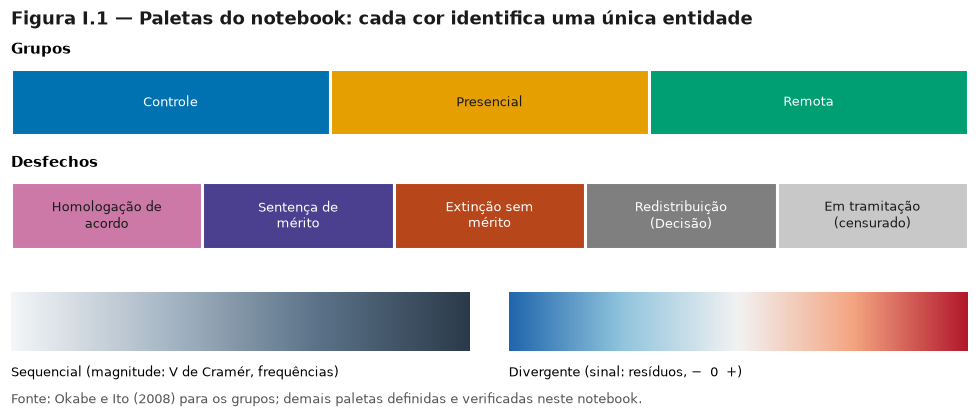

In [4]:
_MACHADO = {
    'protanopia': np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    'deuteranopia': np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
}


def _linear(cor):
    c = np.array(mpl.colors.to_rgb(cor))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _oklab(rgb_linear):
    rgb_linear = np.clip(rgb_linear, 0, 1)
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ rgb_linear
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)


def delta_e(a, b, simulacao=None):
    """ΔE OKLab (×100) entre duas cores, opcionalmente sob simulação de daltonismo (Machado et al., 2009)."""
    A, B = _linear(a), _linear(b)
    if simulacao:
        A, B = _MACHADO[simulacao] @ A, _MACHADO[simulacao] @ B
    return 100 * float(np.linalg.norm(_oklab(A) - _oklab(B)))


def relatorio_cvd(nome, cores, pares):
    linhas = []
    for a, b in pares:
        d = {'Paleta': nome, 'Par': f'{a} × {b}', 'ΔE normal': delta_e(cores[a], cores[b])}
        for s in _MACHADO:
            d[f'ΔE {s}'] = delta_e(cores[a], cores[b], s)
        linhas.append(d)
    return linhas


_pares_grupo = [(a, b) for i, a in enumerate(ORDEM_GRUPO) for b in ORDEM_GRUPO[i + 1:]]
_pares_desf = list(zip(ORDEM_DESFECHO[:-1], ORDEM_DESFECHO[1:]))           # vizinhos nas barras empilhadas
_cromaticos = ['Homologação', 'Mérito', 'Sem mérito']
_cruzadas = {**{f'grupo {g}': CORES_GRUPO[g] for g in ORDEM_GRUPO}, **{f'desfecho {k}': CORES_DESFECHO[k] for k in _cromaticos}}
_pares_cruz = [(f'grupo {g}', f'desfecho {k}') for g in ORDEM_GRUPO for k in _cromaticos]
cvd = pd.DataFrame(relatorio_cvd('Grupos (todos os pares)', CORES_GRUPO, _pares_grupo)
                   + relatorio_cvd('Desfechos (vizinhos)', CORES_DESFECHO, _pares_desf)
                   + relatorio_cvd('Grupo × desfecho (mesmo gráfico)', _cruzadas, _pares_cruz))
cvd['Pior simulado'] = cvd[['ΔE protanopia', 'ΔE deuteranopia']].min(axis=1)
cvd['Situação'] = np.select([(cvd['Pior simulado'] >= 8) & (cvd['ΔE normal'] >= 15), cvd['Pior simulado'] >= 6],
                            ['passa', 'passa com rótulo/legenda'], 'exige 2º canal (forma, posição)')
resumo_cvd = cvd.groupby('Paleta', sort=False).agg(**{'Pares': ('Par', 'size'), 'Menor ΔE normal': ('ΔE normal', 'min'),
                                                      'Menor ΔE simulado': ('Pior simulado', 'min')})
tabela(resumo_cvd, 'cur_cvd_resumo', 'Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100)',
       secao='1.2.1', casas=1,
       nota='simulação de Machado, Oliveira e Fernandes (2009), severidade 1,0; alvo ≥ 8 sob simulação e ≥ 15 sem simulação. '
            'A linha "grupo × desfecho" é informativa: grupos e desfechos só dividem o mesmo gráfico quando a forma '
            '(linha × marcador) também os distingue.')
_fracos = cvd[cvd['Situação'] != 'passa']
if len(_fracos):
    print('Pares abaixo do alvo (exigem segundo canal):')
    for _, r in _fracos.iterrows():
        print(f"  {r['Par']}: ΔE normal {fmt_br(r['ΔE normal'])}; pior simulado {fmt_br(r['Pior simulado'])} → {r['Situação']}")

# Mapas sequencial e divergente: luminosidade OKLab monotônica
_L = lambda mapa, xs: [_oklab(_linear(mapa(x)))[0] for x in xs]
_seq_L = _L(SEQ, np.linspace(0, 1, 11))
_div_L = _L(DIV, np.linspace(0, 1, 11))
print('Sequencial: luminosidade decrescente (claro → escuro):', all(np.diff(_seq_L) < 0))
print('Divergente: luminosidade cresce até o meio e decresce depois:',
      all(np.diff(_div_L[:6]) > 0) and all(np.diff(_div_L[5:]) < 0))

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={'height_ratios': [1, 1, 0.8]})
for a, (nome, cores_) in zip(ax[:2], [('Grupos', {g: CORES_GRUPO[g] for g in ORDEM_GRUPO}),
                                       ('Desfechos', {ROTULO_DESFECHO[k]: CORES_DESFECHO[k] for k in ORDEM_DESFECHO})]):
    for i, (rot, cor) in enumerate(cores_.items()):
        a.barh(0, 1, left=i, color=cor, edgecolor='white', linewidth=2)
        a.text(i + 0.5, 0, quebra(rot, 14), ha='center', va='center', fontsize=8.5, color=_cor_texto(cor))
    a.set_xlim(0, len(cores_)); a.set_axis_off(); a.set_title(nome, loc='left', fontsize=10)
gradiente = np.linspace(0, 1, 256)[None, :]
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=SEQ, extent=(0, 0.48, 0, 1))
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=DIV, extent=(0.52, 1, 0, 1))
ax[2].set_xlim(0, 1); ax[2].set_axis_off()
ax[2].text(0, -0.25, 'Sequencial (magnitude: V de Cramér, frequências)', fontsize=8.5, va='top', transform=ax[2].transAxes)
ax[2].text(0.52, -0.25, 'Divergente (sinal: resíduos, −  0  +)', fontsize=8.5, va='top', transform=ax[2].transAxes)
figura(fig, 'cur_paletas', 'Paletas do notebook: cada cor identifica uma única entidade', secao='1.2.1',
       fonte='Fonte: Okabe e Ito (2008) para os grupos; demais paletas definidas e verificadas neste notebook.')

---

## 1.3 Formação do dataset bruto

### 1.3.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.14).

In [5]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
tabela(abas, 'cur_abas', 'Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo', secao='1.3.1')

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
Processos,visível,A2:O946,13.317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.3.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [6]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
tabela(dados_brutos.head(5), 'cur_bruto_amostra', 'As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)',
       secao='1.3.2', indice=True, exportar=False, nota='a primeira coluna (linha_excel) é o número da linha no Excel.')

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


linha_excel,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
3,0800001-35.2026.8.20.5004,01/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,07/01/2026,6,–,6,6,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,–,–,–,274,–,274,274,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,09/01/2026,3,–,3,3,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,07/01/2026,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,22/02/2026,46,46,46,46,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,07/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,27/02/2026,51,–,51,51,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.10). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.4).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.4 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [7]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
tabela(pd.DataFrame(formulas), 'cur_formulas', 'Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY()',
       secao='1.4')

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
J,DURAÇÃO-SENT2,943,Sim,Sim,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
K,DURAÇÃO-TECN,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
L,DURAÇÃO-SORT,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
M,DURAÇÃO-PROC,943,Sim,Sim,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
N,DURAÇÃO DO PROCESSO,943,Não,Não,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
O,STATUS,943,Não,Não,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [8]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
tabela(data_referencia.dt.strftime('%d/%m/%Y').value_counts().rename_axis('Data implícita de TODAY()').rename('Processos ativos').to_frame(),
       'cur_data_today', 'Data em que TODAY() foi avaliado, reconstituída dos valores em cache', secao='1.4')
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
tabela(iguais, 'cur_duracoes_iguais', 'As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)', secao='1.4')
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

Data implícita de TODAY(),Processos ativos
07/10/2026,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


Coluna,Não nulas,Iguais a DURAÇÃO-PROC
DURAÇÃO-SENT2,943,943
DURAÇÃO-TECN,428,428
DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.14) mostra que não há nenhum caso.

---

## 1.5 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [9]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
tabela(perfil_bruto.rename_axis('Coluna bruta'), 'cur_perfil_bruto', 'Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências',
       secao='1.5', formatos={'dtype lido': 'texto'})

Coluna bruta,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.6 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [10]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
tabela(TIPOLOGIA_BRUTA, 'cur_tipologia', 'Tipologia estatística das colunas da planilha e decisão de tratamento', secao='1.6')

Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.7 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [11]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


tabela(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS), 'cur_ausencias', 'Três formas de ausência por coluna digitada (linhas da planilha)',
       secao='1.7', nota='NaN = não informado; "**" = não se aplica (zero estrutural).')

Coluna,NaN,"""**""",Vazio/espaços,Válidos
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.7.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [12]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
tabela(tabela_padrao.sort_values('Total', ascending=False).rename_axis('Padrão (1 = NaN)'), 'cur_padroes_ausencia',
       'Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo',
       secao='1.7.1', formatos={'Padrão (1 = NaN)': 'texto'},
       nota='ordem das posições no padrão: ' + ', '.join(COLUNAS_PADRAO) + '.')
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

Padrão (1 = NaN),(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; azul-acinzentado claro = `**` (não se aplica); ardósia escura = `NaN` (não informado).

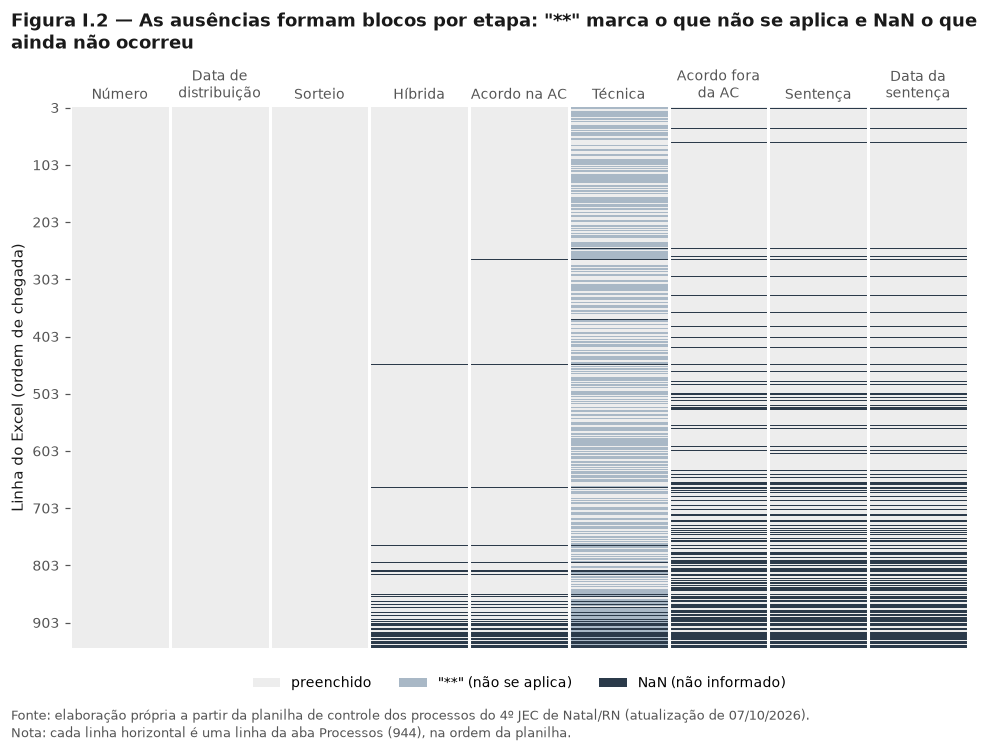

In [13]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
CORES_AUSENCIA = ['#EDEDED', '#A9B8C6', '#2B3A4A']   # preenchido, "**", NaN (sem matizes de grupo/desfecho)
fig, ax = plt.subplots(figsize=(9, 6))
mapa = mpl.colors.ListedColormap(CORES_AUSENCIA)
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Data de distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Data da sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), [quebra(r, 12) for r in ROTULOS_CURTOS])
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLUNAS_DIGITADAS)), minor=True)
ax.grid(which='minor', axis='x', color='white', lw=2)
ax.tick_params(which='minor', length=0)
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(CORES_AUSENCIA, ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
legenda_abaixo(ax, handles=legenda, ncol=3, dy=-0.03)
figura(fig, 'cur_mapa_ausencias',
       'As ausências formam blocos por etapa: "**" marca o que não se aplica e NaN o que ainda não ocorreu',
       secao='1.7.1', nota='cada linha horizontal é uma linha da aba Processos (944), na ordem da planilha.')

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.11 e 1.12. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.8 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [14]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


tabela(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}),
       'cur_renomear', 'Nomes das colunas na cópia de trabalho (o repr mostra espaços extras do original)', secao='1.8')

Coluna original,Nome na cópia de trabalho
'NÚMERO DO PROCESSO',numero_bruto
'DT. DISTRIBUIÇÃO',dt_distribuicao
'SORTEIO',sorteio
'HÍBRIDA',hibrida_bruto
'TEVE ACORDO NA AC?',acordo_ac_bruto
'TÉCNICA',tecnica_bruto
'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
'SENTENÇA',sentenca_bruto
'DT. SENTENÇA',dt_sentenca
'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.9 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [15]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
tabela(numero[fora].map(repr).rename('Valor bruto (repr)').to_frame().rename_axis('Linha do Excel'), 'cur_cnj_fora',
       'Números de processo fora do padrão CNJ antes da limpeza', secao='1.9', formatos={'Linha do Excel': 'texto'})

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
tabela(pd.DataFrame({'Número truncado': passo2[truncado],
                     'Órgãos 5000–5399 com DV válido': pd.Series(candidatos).map(lambda l: ', '.join(map(str, l)))}
                    ).rename_axis('Linha do Excel'),
       'cur_cnj_truncado', 'Números com órgão truncado: órgãos candidatos que fecham o dígito verificador', secao='1.9',
       formatos={'Linha do Excel': 'texto'})
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


Linha do Excel,Valor bruto (repr)
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


Linha do Excel,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"
453,0806739-39.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.9.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [16]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
tabela(pd.crosstab([trab['cnj_ano'].astype(str).rename('Ano (CNJ)'), trab['cnj_orgao'].rename('Órgão (CNJ)')],
                   trab['sorteio'], margins=True, margins_name='Total'),
       'cur_cnj_orgao_ano', 'Ano e órgão de origem do número CNJ por grupo sorteado (linhas da planilha)', secao='1.9.1', indice=True)
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

origem_externa: 12 linhas


---

## 1.10 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [17]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
tabela(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca', 'xl_status']]
       .rename_axis('Linha do Excel').rename(columns={'processo': 'Processo', 'dt_distribuicao': 'Distribuição', 'sorteio': 'Sorteio',
                                                       'tecnica_bruto': 'Técnica', 'sentenca_bruto': 'Sentença',
                                                       'dt_sentenca': 'Data da sentença', 'xl_status': 'STATUS'}),
       'cur_duplicados', 'Números de processo repetidos: reentradas após redistribuição, às vezes sorteadas para outro grupo',
       secao='1.10', formatos={'Linha do Excel': 'texto', 'Processo': 'texto'})
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

Linha do Excel,Processo,Distribuição,Sorteio,Técnica,Sentença,Data da sentença,STATUS
162,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,**,Decisão,18/02/2026,Encerrado
164,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,–,–,–,Ativo
290,0804436-52.2026.8.20.5004,18/03/2026,Ac Obrigatória Presencial,**,Decisão,18/03/2026,Encerrado
322,0804436-52.2026.8.20.5004,24/03/2026,Ac Obrigatória Presencial,**,Decisão,09/04/2026,Encerrado
475,0804436-52.2026.8.20.5004,27/04/2026,Rito Atual Ac Opcional,**,Decisão,27/04/2026,Encerrado
591,0808905-44.2026.8.20.5004,20/05/2026,Ac Remota,**,Decisão,21/05/2026,Encerrado
607,0808905-44.2026.8.20.5004,22/05/2026,Ac Remota,**,–,–,Ativo
819,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,–,–,–,Ativo
822,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,**,Extinção do Feito com Homologação do Acordo,16/09/2026,Encerrado
851,0812839-10.2026.8.20.5004,15/07/2026,Ac Remota,Padrões Objetivos,–,–,Ativo


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [18]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio'), trab['base_primaria'].map({True: 'Mantidas', False: 'Excluídas'}),
                   margins=True, margins_name='Total'),
       'cur_base_primaria', 'Linhas mantidas na base primária e excluídas (duplicata/reentrada), por grupo sorteado', secao='1.10')

Base primária: 938 processos


Sorteio,Excluídas,Mantidas,Total
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.11 Categorias: grafia, partições e recodificações

### 1.11.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [19]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
tabela(pd.DataFrame(diagnostico), 'cur_grafias', 'Grafias distintas e chaves normalizadas por coluna categórica', secao='1.11.1')

Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
sorteio,0,3,3
hibrida_bruto,0,2,2
acordo_ac_bruto,0,2,2
tecnica_bruto,0,7,7
acordo_fora_bruto,0,3,3
sentenca_bruto,0,5,4


### 1.11.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [20]:
tabela(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
       .assign(Chave=lambda t: t.index.map(normalizar_chave)),
       'cur_sentenca_grafias', 'Grafias do tipo de sentença na planilha e chave normalizada', secao='1.11.2')

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
tabela(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)').rename('Sentença (planilha)'), trab['tipo_desfecho']),
       'cur_recod_desfecho', 'Recodificação da sentença da planilha no tipo de desfecho', secao='1.11.2')

Grafia,Linhas,Chave
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
–,210,–
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


Sentença (planilha),Homologação,Mérito,Sem mérito,Redistribuição,Ativo
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.11.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [21]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio (planilha)'), trab['grupo']), 'cur_recod_grupo',
       'Recodificação do grupo sorteado', secao='1.11.3')

Sorteio (planilha),Controle,Presencial,Remota
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.11.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [22]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

_sn = lambda s: s.map({True: 'Sim', False: 'Não'}).astype(object).fillna('<NA>')
tabela(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)').rename('Técnica (planilha)'),
                   _sn(trab['ac_realizada']).rename('AC realizada'), margins=True, margins_name='Total'),
       'cur_tecnica_ac', 'Técnica registrada × AC realizada: "**" indica que a audiência não ocorreu', secao='1.11.4')
tabela(pd.crosstab([_sn(trab['acordo_ac']).rename('Acordo na AC'), _sn(trab['acordo_fora']).rename('Acordo fora da AC')],
                   trab['tipo_desfecho']),
       'cur_acordos_desfecho', 'Acordo na AC e fora dela × tipo de desfecho', secao='1.11.4', indice=True)

Técnica (planilha),,Não,Sim,Total
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.12 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [23]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
tabela(coerencia_grupo, 'cur_coerencia', 'Coerência entre o grupo sorteado e o que ocorreu: o Controle não tem AC (zeros estruturais)',
       secao='1.12')
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
tabela(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                           'hibrida_remota', 'hibrida_sem_ac']].rename_axis('Linha do Excel'),
       'cur_desvios', 'Processos com desvio de protocolo (marcados para análise de sensibilidade)', secao='1.12',
       formatos={'Linha do Excel': 'texto', 'processo': 'texto'})

grupo,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


Linha do Excel,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
318,0804822-82.2026.8.20.5004,Remota,Sim,Separação de Pessoas e Problemas,Mérito,Sim,Não
433,0806545-39.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
455,0806829-47.2026.8.20.5004,Presencial,Sim,**,Homologação,Não,Sim
456,0806797-42.2026.8.20.5004,Remota,Sim,Teoria do Afago ou do Reforço Positivo,Ativo,Sim,Não
712,0810564-88.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
832,0812493-59.2026.8.20.5004,Remota,Sim,–,Ativo,Sim,Não


### 1.12.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [24]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
tabela(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']]
       .rename(columns={'count': 'n', 'min': 'Mínimo (dias)', '50%': 'Mediana (dias)', 'mean': 'Média (dias)', 'max': 'Máximo (dias)'})
       .rename_axis('Grupo'),
       'cur_redistribuicoes', 'Dias da distribuição até a Decisão de redistribuição, por grupo (todas as linhas)',
       secao='1.12.1', casas=1)
tabela(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tecnica': 'Técnica', 'dias': 'Dias até a Decisão'}),
       'cur_redist_com_ac', 'Redistribuições ocorridas depois de uma AC realizada', secao='1.12.1',
       indice=False, formatos={'Processo': 'texto'})

26 redistribuições (todas as linhas); na base primária: 24


Grupo,n,Mínimo (dias),Mediana (dias),Média (dias),Máximo (dias)
Controle,6,0,1,"4,2",20
Presencial,11,0,1,"3,0",16
Remota,9,1,8,"25,4",84


Processo,Grupo,Técnica,Dias até a Decisão
0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.13 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.13.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [25]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.13.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [26]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
tabela(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
       .size().reindex(DIAS).rename('Sentenças').to_frame().T, 'cur_sentenca_dia_semana',
       'Sentenças por dia da semana da data registrada', secao='1.13.2', indice=False)

Sentenças em fim de semana: 135 de 734


seg,ter,qua,qui,sex,sáb,dom
91,186,149,85,88,70,65


### 1.13.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [27]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
tabela(dados.dtypes.astype(str).rename('dtype').rename_axis('Variável').to_frame(), 'cur_dtypes_tidy',
       'Tipos finais das variáveis do dataset tidy', secao='1.13.3', formatos={'dtype': 'texto'})
tabela(dados.head(5), 'cur_tidy_amostra', 'As cinco primeiras linhas do dataset tidy (base primária)', secao='1.13.3',
       exportar=False, indice=False)

dados_todas: (944, 40) | dados (base primária): (938, 37)


Variável,dtype
processo,string
linha_excel,Int64
ordem_chegada,Int64
dt_distribuicao,datetime64[ns]
dia_estudo,Int64
mes_distribuicao,category
ciclo,category
dia_semana_distribuicao,category
grupo,category
grupo_rotulo,category


processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0800001-35.2026.8.20.5004,3,1,01/01/2026,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,07/01/2026,Sim,6,6,1,1,3,279,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não
0800024-78.2026.8.20.5004,4,2,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,–,–,Ativo,–,Não,274,274,0,0,0,274,2.026,5004,Não,Não,Não,Não,–,Não,Não,Não,Não
0808292-43.2025.8.20.5300,5,3,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,09/01/2026,Sim,3,3,1,1,3,274,2.025,5300,Não,Sim,Não,Não,Não,Não,Não,Não,Não
0800038-62.2026.8.20.5004,6,4,07/01/2026,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,Sim,Desconstrução da Verdade,Desconstrução,Não,Sim,Não,Sim,Homologação,22/02/2026,Sim,46,46,1,1,1,273,2.026,5004,Não,Não,Não,Não,Sim,Não,Não,Não,Não
0800035-10.2026.8.20.5004,7,5,07/01/2026,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Mérito,27/02/2026,Sim,51,51,1,1,2,273,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não


---

## 1.14 Verificações

### 1.14.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [28]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
tabela(pd.DataFrame(resumo_particoes), 'cur_particoes', 'Verificação das partições: cada variável categórica cobre todos os processos',
       secao='1.14.1')
print('Todas as verificações passaram.')

Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
grupo,3,0,0,0,Sim,Sim
grupo_rotulo,3,0,0,0,Sim,Sim
tipo_desfecho,5,0,0,0,Sim,Sim
mes_distribuicao,8,0,0,0,Sim,Sim
ciclo,2,0,0,0,Sim,Sim
dia_semana_distribuicao,7,0,0,0,Sim,Sim
tecnica,6,0,586,0,Sim,Sim
tecnica_curta,6,0,586,0,Sim,Sim


Todas as verificações passaram.


### 1.14.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [29]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
tabela(fluxo.rename_axis('Etapa'), 'cur_fluxo', 'Fluxo dos processos, da planilha à situação em 07/10/2026, por grupo',
       secao='1.14.2', formatos={c: 'texto' for c in fluxo.columns})
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

Etapa,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.14.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [30]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
tabela(conf.astype(str), 'cur_conferencia', 'Conferência com os números divulgados pela pesquisadora', secao='1.14.3')

Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
Processos (linhas com STATUS),943 (Tab_D),943,938
Encerrados (STATUS),734 (Tab_D),734,732
Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
Acordos (homologações),81 (Tabelas),81,81
Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.15 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [31]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
tabela(resumo_log, 'cur_log_resumo', 'Resumo do log de tratamentos por anomalia e ação', secao='1.15')
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

codigo,problema,tratamento,linhas,exemplos
A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.16 Dicionário de variáveis e exportação

### 1.16.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [32]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
tabela(dicionario, 'cur_dicionario', 'Dicionário de variáveis do dataset tidy', secao='1.16.1')

variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.16.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.15) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.16.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [33]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB
ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE V — ANÁLISE MULTIVARIADA E MODELAGEM

A Parte IV estimou os efeitos dos grupos sobre o **tempo** com modelos que respeitam a censura (Kaplan-Meier, Cox, AFT e riscos competitivos). Esta parte pergunta o que a **modelagem multivariada** acrescenta: (i) por que a regressão linear sobre o tempo, usada no notebook do professor, não serve (E26); (ii) o que modelos de **classificação** (regressão logística, logit multinomial e árvores de decisão; ARTES; BARROSO, 2023, cap. 10 e 11) dizem sobre o **acordo** e o **tipo de desfecho**; (iii) que estrutura a **análise de correspondência** revela na tabela grupo × desfecho; e (iv) qual modelo de tempo, entre os que tratam a censura, **descreve e prevê** melhor.

### Limitação que condiciona toda a Parte V: quase não há covariáveis

O projeto de pesquisa previa como variáveis de controle o **tipo de ação, o valor da causa e o número de partes** (ver `docs/r1_documentos.md`), e a literatura de duração processual acrescentaria o **advogado constituído** (ou *jus postulandi*), a **pessoa jurídica no polo passivo** e o **litigante habitual**. **Nenhuma dessas variáveis foi coletada.** A planilha só registra o que o próprio experimento produziu:

| Variável disponível | Natureza | Pode entrar como preditora? |
|---|---|---|
| `grupo` (sorteado) | basal, aleatorizada | sim: é o fator de interesse |
| mês de distribuição / ordem de chegada | basal (calendário) | sim; mas determina o seguimento (`followup`), com o qual é quase colinear |
| `origem_externa` (12 processos) | basal | sim, mas rara |
| `ac_realizada`, `hibrida`, técnica | **pós-sorteio** (ocorrem durante o processo; zero estrutural no Controle) | só no subconjunto com audiência, e como mediadores exploratórios |
| `acordo_ac`, `acordo_fora`, `acordo` | **desfechos** intermediários | só como resposta, nunca como preditora do tempo (viés de tempo imortal) |
| `tipo_desfecho` | desfecho | só como resposta |

Consequência: os modelos desta parte têm, no máximo, **três ou quatro preditores**, e todos de baixa variabilidade entre processos. Isso não é defeito do desenho: o sorteio foi feito para uma **comparação causal entre grupos** (que dispensa covariáveis para ser não enviesada), e não para **prever** a duração de um processo individual. Esperam-se, portanto, poder explicativo e preditivo baixos, e a parte é honesta quanto a isso. A seção 5.6 lista as variáveis que permitiriam uma modelagem multivariada de verdade (questão 2.9).

**Codificação comum.** O mês entra como escore ordinal (`mes_num`: jan = 1, …, ago = 8), uma tendência linear de calendário com um único parâmetro; agosto tem só 6 processos, o que desaconselha um parâmetro por mês. Grupo: Controle como referência.

In [34]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from lifelines import WeibullAFTFitter, LogNormalAFTFitter, NelsonAalenFitter
from lifelines.utils import k_fold_cross_validation, concordance_index

RNG_MUL = np.random.default_rng(SEMENTE)
mul_res = {}          # resultados guardados para a síntese (5.6)

mul = dados.copy()
mul['grupo'] = pd.Categorical(mul['grupo'].astype(str), categories=ORDEM_GRUPO)
mul['mes_num'] = mul['mes_distribuicao'].cat.codes.astype(int) + 1
mul['presencial'] = (mul['grupo'] == 'Presencial').astype(int)
mul['remota'] = (mul['grupo'] == 'Remota').astype(int)
mul['T'] = mul['tempo'].astype(float)
mul['E'] = mul['evento'].astype(int)
mul['T_pos'] = mul['tempo_pos'].astype(float)
mul['log_T'] = np.log(mul['T_pos'])
mul['followup_f'] = mul['followup'].astype(float)
mul['log_followup'] = np.log(mul['followup_f'])
mul['dia_estudo_f'] = mul['dia_estudo'].astype(float)
mul['encerrado_b'] = mul['encerrado'].astype(bool)
mul['desfecho'] = mul['tipo_desfecho'].astype(str)
mul['homolog'] = (mul['desfecho'] == 'Homologação').astype(int)
mul['hibrida_b'] = mul['hibrida'].fillna(False).astype(bool).astype(int)
mul['origem_ext'] = mul['origem_externa'].astype(bool).astype(int)

NOMES_COEF = {'Intercept': 'Intercepto', 'C(grupo)[T.Presencial]': 'Presencial vs Controle',
              'C(grupo)[T.Remota]': 'Remota vs Controle', 'mes_num': 'Mês de distribuição (+1 mês)',
              'log_followup': 'log(seguimento)', 'hibrida_b': 'Híbrida (sim)', 'remota': 'Remota vs Presencial',
              'presencial': 'Presencial vs Controle', 'origem_ext': 'Origem externa',
              'dia_estudo_f': 'Dia de distribuição'}

def mul_ic_wilson(x, n):
    li, ls = proportion_confint(x, n, method='wilson')
    return li, ls

resumo = pd.DataFrame({
    'Subconjunto': ['Todos', 'Encerrados (sentença ou redistribuição)', 'Sentenciados (evento = 1)',
                    'Com audiência realizada'],
    'n': [len(mul), int(mul['encerrado_b'].sum()), int(mul['E'].sum()),
          int(mul['ac_realizada'].fillna(False).astype(bool).sum())]})
print(f"Correlação entre mês de distribuição e log(seguimento): r = {fmt_br(np.corrcoef(mul['mes_num'], mul['log_followup'])[0, 1], 3)}")
tabela(resumo.rename(columns={'n': 'Processos (n)'}), 'mul_subconjuntos', 'Subconjuntos analíticos usados na Parte V',
       secao='5', nota='encerrados = com sentença ou redistribuição até 07/10/2026; audiência realizada só existe nos grupos '
                       'Presencial e Remota (zero estrutural no Controle).')

# ---------------------------------------------------------------- auxiliares gráficos da Parte V
# Cores de "estimadores/modelos" (entidade própria): nenhuma repete a cor de um grupo.
COR_MODELO = '#2B3A4A'          # modelo de referência / série única
COR_VIES = DESTAQUE             # estimador enviesado ou alternativa em contraste
NOMES_VAR = {'presencial': 'Presencial (1 = sim)', 'remota': 'Remota (1 = sim)', 'dia_estudo': 'Dia de distribuição',
             'origem_ext': 'Origem externa (1 = sim)', 'ac_realizada': 'AC realizada (1 = sim)',
             'hibrida': 'AC híbrida (1 = sim)'}


def mul_peq(p):
    """'< 0,001' ou '= 0,034' (para escrever 'p < 0,001' / 'p = 0,034')."""
    return '< 0,001' if p < 0.001 else '= ' + fmt_p(p)


def mul_ic(v, lo, hi, casas=3):
    return f'{fmt_br(v, casas)} [{fmt_br(lo, casas)}; {fmt_br(hi, casas)}]'


def mul_fmt_razao(v):
    """Rótulo de eixo para razões (escala log): 0,25 · 0,5 · 1 · 1,5 · 2."""
    s = fmt_br(v, 2)
    return s.rstrip('0').rstrip(',') if ',' in s else s


def mul_eixo_razao(ax, valores, eixo='y'):
    """Escala log para razões (RC, RRR, razão de tempos) com marcas legíveis em pt-BR e linha de nulidade em 1."""
    v = np.asarray([x for x in valores if np.isfinite(x) and x > 0], float)
    lo, hi = min(v.min(), 1) / 1.25, max(v.max(), 1) * 1.25
    cand = np.array([0.05, 0.1, 0.2, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 10, 20, 50, 100])
    marcas = cand[(cand >= lo) & (cand <= hi)]
    alvo = ax.yaxis if eixo == 'y' else ax.xaxis
    (ax.set_yscale if eixo == 'y' else ax.set_xscale)('log')
    alvo.set_major_locator(mpl.ticker.FixedLocator(marcas))
    alvo.set_major_formatter(FuncFormatter(lambda x, _: mul_fmt_razao(x)))
    alvo.set_minor_locator(mpl.ticker.NullLocator())
    (ax.set_ylim if eixo == 'y' else ax.set_xlim)(lo, hi)
    (ax.axhline if eixo == 'y' else ax.axvline)(1, color=TINTA_2, lw=1, zorder=1)


def mul_forest(ax, est, li, ls, x=None, cor=COR_MODELO, textos=None, label=None, marker='o'):
    """Pontos com IC 95% (vertical), um por posição x; `textos` = rótulos seletivos ao lado do ponto."""
    est, li, ls = (np.asarray(a, float) for a in (est, li, ls))
    x = np.arange(len(est)) if x is None else np.asarray(x, float)
    cores = cor if isinstance(cor, (list, tuple)) else [cor] * len(est)
    for i in range(len(est)):
        ax.errorbar(x[i], est[i], yerr=[[est[i] - li[i]], [ls[i] - est[i]]], fmt=marker, ms=7, color=cores[i],
                    ecolor=cores[i], elinewidth=1.6, capsize=4, label=label if i == 0 else None, zorder=3)
        if textos is not None and textos[i]:
            ax.annotate(textos[i], (x[i], est[i]), xytext=(9, 0), textcoords='offset points', va='center',
                        ha='left', fontsize=8.5, color=TINTA)
    ax.grid(axis='x', visible=False)


def mul_rotular_pontos(ax, xs, ys, textos, tamanho=9, negrito=None):
    """Rótulos de pontos sem colisão: testa 8 posições ao redor de cada ponto e fica com a primeira livre."""
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    ocupado = []
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    for (px, py) in pts:
        ocupado.append(mpl.transforms.Bbox.from_extents(px - 6, py - 6, px + 6, py + 6))
    offs = [(8, 6, 'left', 'bottom'), (8, -6, 'left', 'top'), (-8, 6, 'right', 'bottom'), (-8, -6, 'right', 'top'),
            (0, 10, 'center', 'bottom'), (0, -10, 'center', 'top'), (14, 0, 'left', 'center'), (-14, 0, 'right', 'center')]
    for k, (x, y, t) in enumerate(zip(xs, ys, textos)):
        escolhido = None
        for dx, dy, ha, va in offs:
            a = ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=tamanho,
                            color=TINTA, fontweight='bold' if negrito and negrito[k] else 'normal')
            bb = a.get_window_extent(rend).expanded(1.05, 1.1)
            if not any(bb.overlaps(o) for o in ocupado):
                escolhido = a
                break
            a.remove()
        if escolhido is None:   # nenhuma posição livre: usa a primeira
            dx, dy, ha, va = offs[0]
            escolhido = ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va,
                                    fontsize=tamanho, color=TINTA)
        ocupado.append(escolhido.get_window_extent(rend))


def mul_arvore(ax, modelo, colunas, classes=None, cores_classe=None, fontsize=9, precisao=2):
    """plot_tree legível: nomes de variáveis em português, vírgula decimal, nós coloridos pela entidade.

    Classificação: cor da classe majoritária (intensidade = pureza). Regressão: escala divergente DIV pelo valor do nó.
    """
    anns = plot_tree(modelo, feature_names=[NOMES_VAR.get(c, c) for c in colunas], class_names=classes,
                     filled=False, rounded=True, impurity=False, proportion=True, fontsize=fontsize, ax=ax,
                     precision=precisao)
    valores = modelo.tree_.value[:, 0, :]
    if classes is None:
        lim = np.abs(valores[:, 0]).max() or 1
    for i, a in enumerate(anns):
        txt = a.get_text()
        txt = re.sub(r'(\d)\.(\d)', r'\1,\2', txt)
        txt = (txt.replace('samples', 'processos').replace('value', 'proporções' if classes is not None else 'resíduo médio')
                  .replace('class', 'classe').replace('<=', '≤').replace('True', 'sim').replace('False', 'não'))
        a.set_text(txt)
        caixa = a.get_bbox_patch()
        if caixa is None or i >= len(valores):
            continue
        if classes is not None:
            v = valores[i] / valores[i].sum()
            k = int(np.argmax(v))
            pureza = (v[k] - 1 / len(v)) / (1 - 1 / len(v))
            caixa.set_facecolor(mpl.colors.to_rgba(cores_classe[classes[k]], 0.12 + 0.43 * pureza))
        else:
            caixa.set_facecolor(DIV(0.5 + 0.5 * valores[i, 0] / lim))
        caixa.set_edgecolor('#8c8c8c')
    return anns

Correlação entre mês de distribuição e log(seguimento): r = -0,969


Subconjunto,Processos (n)
Todos,938
Encerrados (sentença ou redistribuição),732
Sentenciados (evento = 1),708
Com audiência realizada,352


## 5.1 Regressão linear (OLS) sobre o tempo: por que não serve

O notebook do professor ajustou `duracao_proc ~ grupo` por mínimos quadrados sobre todos os processos, inclusive os ativos (E14, E26). Há duas versões "corrigidas" que alguém poderia tentar, e ambas falham por razões diferentes:

1. **OLS só com os sentenciados** (n = 708), tirando os censurados. Responde a uma pergunta condicional ("entre os que já tiveram sentença, quanto demoraram?") e é **enviesada para tempos curtos**: um processo distribuído em julho só entra na amostra se for julgado em menos de ~90 dias.
2. **OLS sobre log(tempo)**, que aproxima a regressão de um modelo log-normal (AFT) e tenta corrigir a assimetria; o problema da censura continua.

Ajustam-se as duas versões com `grupo + mês`, examinam-se R² e resíduos e, por fim, comparam-se os coeficientes com os de um **modelo log-normal AFT com censura** (a mesma escala, log T; COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122), que usa todos os 938 processos. A diferença entre eles é o **viés de selecionar só os encerrados**.

### 5.1.1 Ajuste e R²

H0 (teste F global): todos os coeficientes, exceto o intercepto, são nulos. H1: ao menos um não é. Os coeficientes do modelo linear estão em dias; os do modelo em log, exponenciados, são **razões de médias geométricas** (exp(β) = 0,90 significa tempo típico 10% menor).

In [35]:
sent = mul[mul['E'] == 1].copy()
ols_lin = smf.ols('T ~ C(grupo) + mes_num', data=sent).fit()
ols_log = smf.ols('log_T ~ C(grupo) + mes_num', data=sent).fit()
ols_log_todos = smf.ols('log_T ~ C(grupo) + mes_num', data=mul).fit()   # versão do professor (censurados como completos)

def mul_tab_ols(res, exp=False):
    ic = res.conf_int()
    tab = pd.DataFrame({'coef': res.params, 'li': ic[0], 'ls': ic[1], 'p': res.pvalues})
    if exp:
        tab[['coef', 'li', 'ls']] = np.exp(tab[['coef', 'li', 'ls']])
    rot = 'exp(β) (razão de médias geométricas)' if exp else 'β (dias)'
    return pd.DataFrame({'Termo': [NOMES_COEF.get(i, i) for i in tab.index], rot: tab['coef'].to_numpy(),
                         'IC 95% inf.': tab['li'].to_numpy(), 'IC 95% sup.': tab['ls'].to_numpy(),
                         'p': tab['p'].to_numpy()}), rot

for id_, nome, res, ex in [('mul_ols_lin', 'OLS do tempo (dias) ~ grupo + mês, só sentenciados: o mês tem efeito negativo', ols_lin, False),
                           ('mul_ols_log', 'OLS de log(tempo) ~ grupo + mês, só sentenciados: razões de médias geométricas', ols_log, True)]:
    t_ols, col = mul_tab_ols(res, ex)
    c = 3 if ex else 1
    tabela(t_ols, id_, nome, secao='5.1.1', formatos={col: c, 'IC 95% inf.': c, 'IC 95% sup.': c}, destaque='p',
           nota=f'n = {int(res.nobs)}; R² = {fmt_br(res.rsquared, 3)}; R² ajustado = {fmt_br(res.rsquared_adj, 3)}; '
                f'teste F global = {fmt_br(res.fvalue, 2)} (p {mul_peq(res.f_pvalue)}). '
                'Linhas em destaque: p < 0,05. Referência do grupo: Controle.')
mul_res['ols_r2'] = ols_lin.rsquared
mul_res['olslog_r2'] = ols_log.rsquared

Termo,β (dias),IC 95% inf.,IC 95% sup.,p
Intercepto,"86,8","77,3","96,3","< 0,001"
Presencial vs Controle,"-1,7","-10,3","6,8","0,692"
Remota vs Controle,"0,8","-7,9","9,5","0,850"
Mês de distribuição (+1 mês),"-4,2","-6,1","-2,2","< 0,001"


Termo,exp(β) (razão de médias geométricas),IC 95% inf.,IC 95% sup.,p
Intercepto,"57,124","41,223","79,159","< 0,001"
Presencial vs Controle,"0,774","0,577","1,039","0,088"
Remota vs Controle,"0,888","0,659","1,197","0,435"
Mês de distribuição (+1 mês),"0,917","0,857","0,981","0,012"


**Interpretação.** Os dois modelos lineares explicam quase nada: **R² = 0,024** para o tempo em dias e **R² = 0,013** para log(tempo). O teste F é "significativo" (p < 0,001 e p = 0,029) **só por causa do mês**, e o sinal do mês é o que denuncia o problema: entre os sentenciados, cada mês a mais de distribuição "reduz" o tempo em 4,2 dias (IC 95% −6,1 a −2,2), ou 8,3% na escala log (exp(β) = 0,917). Isso não quer dizer que os processos de julho são julgados mais depressa; quer dizer que, dos processos de julho, **só os rápidos já aparecem** como sentenciados. Os efeitos de grupo não se distinguem de zero (Presencial −1,7 dia, p = 0,692; Remota +0,8 dia, p = 0,850). O R² baixo, por si só, não seria defeito, porque a pergunta é causal e o sorteio dispensa explicar a variância individual; o defeito é que a amostra condicionada ao encerramento produz coeficientes enviesados (5.1.3).

### 5.1.2 Diagnóstico dos resíduos

Os pressupostos do OLS para a inferência são resíduos com **variância constante** e, para amostras pequenas, aproximadamente **normais**. Três gráficos por modelo:

- **resíduos × valores ajustados**: deve ser uma nuvem sem forma. Como só há 3 grupos × 8 meses, os ajustados formam poucas colunas verticais (pontos com leve deslocamento horizontal para visualização);
- **QQ normal** dos resíduos: pontos sobre a reta indicam normalidade;
- **teste de Breusch-Pagan** (H0: variância dos resíduos constante, homocedasticidade; H1: variância depende dos preditores), com o gráfico dos resíduos ao quadrado contra os ajustados, que é exatamente o que o teste regride.

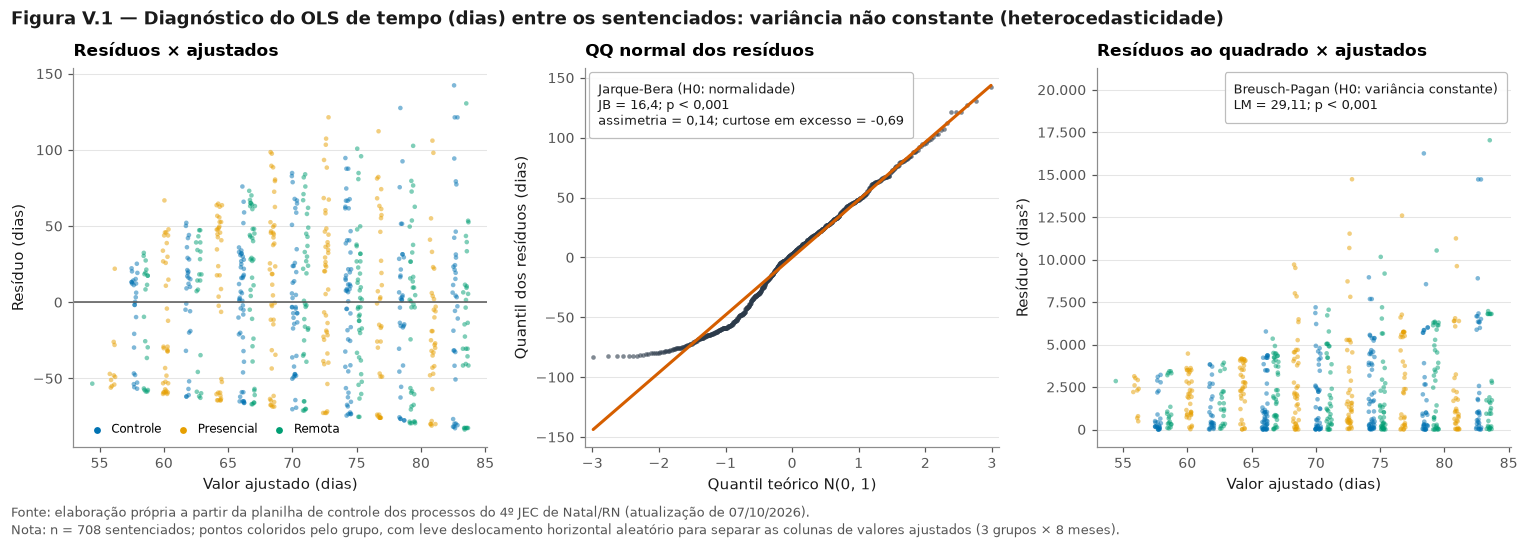

tempo (dias): Breusch-Pagan LM = 29,11 (p < 0,001); Jarque-Bera = 16,4 (p < 0,001); assimetria = 0,14; curtose excesso = -0,69


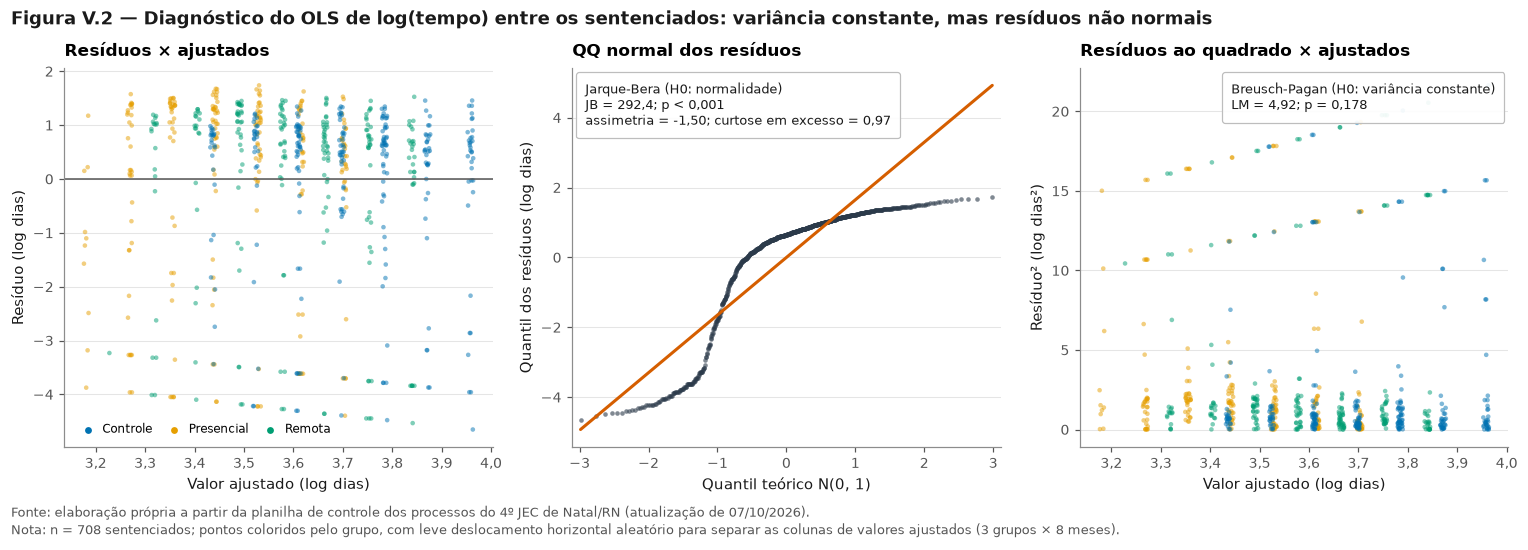

log(tempo): Breusch-Pagan LM = 4,92 (p 0,178); Jarque-Bera = 292,4 (p < 0,001); assimetria = -1,50; curtose excesso = 0,97


In [36]:
for linha, (nome, res, unid, id_) in enumerate([('tempo (dias)', ols_lin, 'dias', 'mul_ols_diag_lin'),
                                                ('log(tempo)', ols_log, 'log dias', 'mul_ols_diag_log')]):
    resid, ajust = res.resid, res.fittedvalues
    cor = sent['grupo'].map(CORES_GRUPO)
    jit = ajust + RNG_MUL.uniform(-0.3, 0.3, len(ajust)) * (ajust.std() / 10)   # mesma sequência aleatória de antes
    bp_lm, bp_p, _, _ = het_breuschpagan(resid, res.model.exog)
    jb = stats.jarque_bera(resid)
    fig, eixos = plt.subplots(1, 3, figsize=(14, 4.4))
    ax = eixos[0]
    ax.scatter(jit, resid, s=9, alpha=0.5, c=cor, lw=0)
    ax.axhline(0, color=TINTA_2, lw=1)
    ax.set(title='Resíduos × ajustados', xlabel=f'Valor ajustado ({unid})', ylabel=f'Resíduo ({unid})')
    for g in ORDEM_GRUPO:
        ax.scatter([], [], color=CORES_GRUPO[g], label=g, s=20)
    ax.legend(loc='lower left', ncol=3, fontsize=8, handletextpad=0.2, columnspacing=0.8)
    ax = eixos[1]
    sm.qqplot(resid, line='s', ax=ax, markersize=3, alpha=0.6, markerfacecolor=COR_MODELO, markeredgecolor='none')
    ax.get_lines()[1].set_color(DESTAQUE)
    ax.set(title='QQ normal dos resíduos', xlabel='Quantil teórico N(0, 1)', ylabel=f'Quantil dos resíduos ({unid})')
    anotar_teste(ax, texto_teste('Jarque-Bera (H0: normalidade)', f'JB = {fmt_br(jb.statistic, 1)}', jb.pvalue,
                                 f'assimetria = {fmt_br(stats.skew(resid), 2)}; curtose em excesso = {fmt_br(stats.kurtosis(resid), 2)}'),
                 loc='upper left')
    ax = eixos[2]
    ax.scatter(jit, resid ** 2, s=9, alpha=0.5, c=cor, lw=0)
    ax.set(title='Resíduos ao quadrado × ajustados', xlabel=f'Valor ajustado ({unid})', ylabel=f'Resíduo² ({unid}²)')
    anotar_teste(ax, texto_teste('Breusch-Pagan (H0: variância constante)', f'LM = {fmt_br(bp_lm, 2)}', bp_p),
                 loc='upper right')
    figura(fig, id_, f'Diagnóstico do OLS de {nome} entre os sentenciados: '
           + ('variância não constante (heterocedasticidade)' if bp_p < 0.05 else 'variância constante, mas resíduos não normais'),
           secao='5.1.2', nota=f'n = {int(res.nobs)} sentenciados; pontos coloridos pelo grupo, com leve deslocamento horizontal '
                               'aleatório para separar as colunas de valores ajustados (3 grupos × 8 meses).')
    print(f'{nome}: Breusch-Pagan LM = {fmt_br(bp_lm, 2)} (p {p_br(bp_p)}); '
          f'Jarque-Bera = {fmt_br(jb.statistic, 1)} (p {p_br(jb.pvalue)}); '
          f'assimetria = {fmt_br(stats.skew(resid), 2)}; curtose excesso = {fmt_br(stats.kurtosis(resid), 2)}')
    mul_res[f'bp_{linha}'] = bp_p

**Interpretação.** Os pressupostos do OLS falham, cada versão de um jeito:

- **tempo em dias**: Breusch-Pagan LM = 29,11 (p < 0,001), ou seja, a variância dos resíduos muda com o valor ajustado (heterocedasticidade). Jarque-Bera também rejeita a normalidade (p < 0,001), com curtose negativa (−0,69): a distribuição é "achatada" porque os tempos dos sentenciados estão **truncados** pelo seguimento disponível;
- **log(tempo)**: a transformação estabiliza a variância (Breusch-Pagan p = 0,178), mas cria uma cauda esquerda pesada (assimetria −1,50; Jarque-Bera = 292,4, p < 0,001), produzida pelos 39 desfechos no dia zero (0,5 dia) e pelas sentenças da primeira semana. O QQ-plot mostra essa curvatura na ponta inferior.

Com n = 708, a não normalidade pouco afeta os intervalos dos coeficientes, mas a heterocedasticidade do modelo em dias invalida os erros-padrão usuais. Nenhum desses consertos, porém (erros robustos, transformação), resolve o problema principal, que é a seleção dos encerrados.

### 5.1.3 O viés de descartar os censurados

A comparação decisiva coloca lado a lado, na mesma escala (razão de tempos, exp(β) sobre log T), três estimativas dos efeitos de grupo e de mês:

- **OLS log, todos** (como o professor, censurados tratados como tempos completos: subestima os tempos dos ativos);
- **OLS log, sentenciados** (descarta os censurados: seleciona os rápidos);
- **AFT log-normal com censura** (`LogNormalAFTFitter`, todos os 938, redistribuição tratada como censura; o modelo de referência da Parte IV).

O segundo gráfico mostra o mecanismo do viés pelo calendário: a média de log(tempo) dos sentenciados cai artificialmente com o mês de distribuição, porque os meses finais tiveram menos seguimento; a mediana de Kaplan-Meier, que usa os censurados, não tem esse artefato.

Modelo,Termo,Razão de tempos exp(β),IC 95% inf.,IC 95% sup.
"OLS log, todos (censura ignorada)",Presencial vs Controle,"0,843","0,7","1,1"
"OLS log, todos (censura ignorada)",Remota vs Controle,"1,017","0,8","1,3"
"OLS log, todos (censura ignorada)",Mês de distribuição (+1 mês),"1,028","1,0","1,1"
"OLS log, só sentenciados",Presencial vs Controle,"0,774","0,6","1,0"
"OLS log, só sentenciados",Remota vs Controle,"0,888","0,7","1,2"
"OLS log, só sentenciados",Mês de distribuição (+1 mês),"0,917","0,9","1,0"
AFT log-normal com censura (todos),Presencial vs Controle,"1,000","0,7","1,3"
AFT log-normal com censura (todos),Remota vs Controle,"1,230","0,9","1,7"
AFT log-normal com censura (todos),Mês de distribuição (+1 mês),"1,204","1,1","1,3"


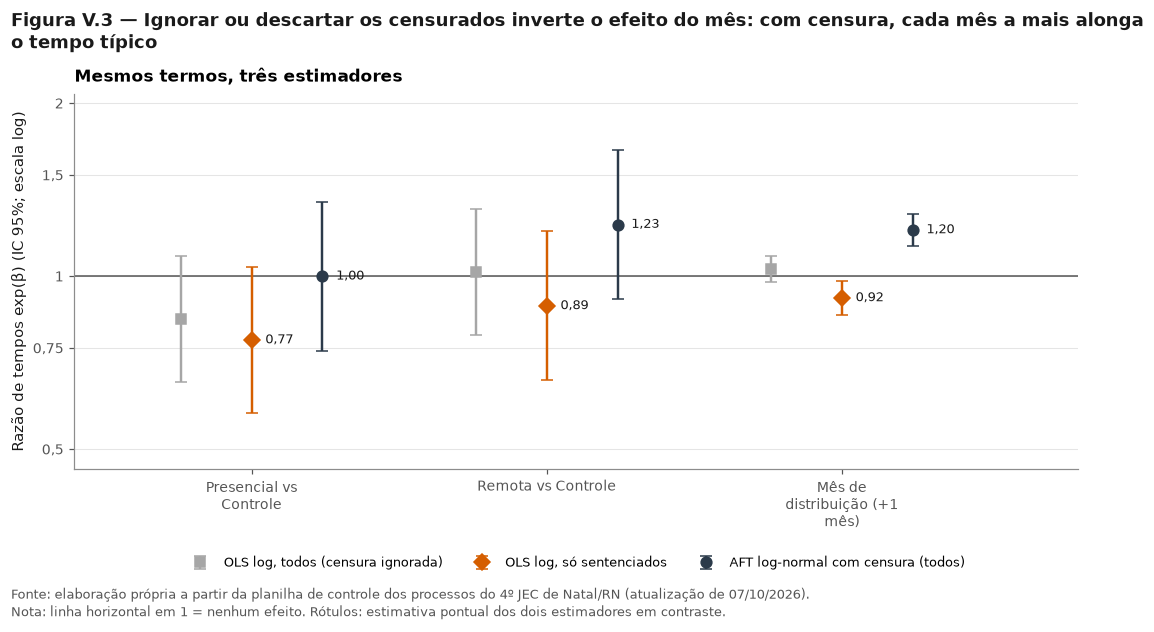

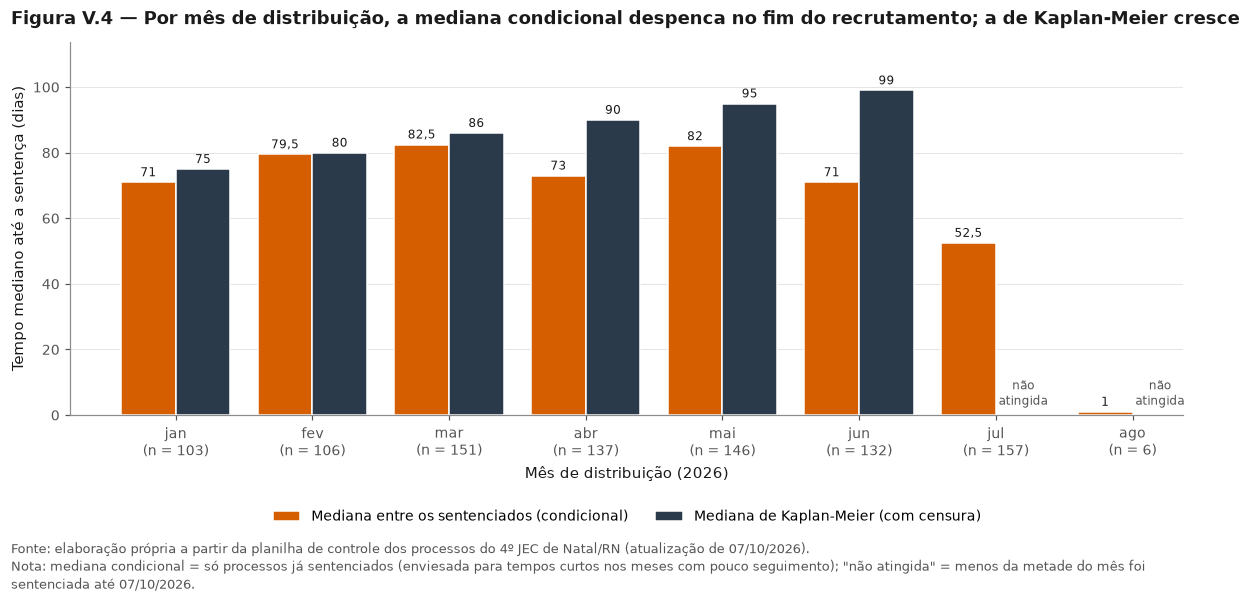

In [37]:
aft_ln = LogNormalAFTFitter().fit(mul[['T_pos', 'E', 'presencial', 'remota', 'mes_num']], 'T_pos', 'E')
termos = [('C(grupo)[T.Presencial]', 'presencial'), ('C(grupo)[T.Remota]', 'remota'), ('mes_num', 'mes_num')]
linhas = []
for rot, res in [('OLS log, todos (censura ignorada)', ols_log_todos), ('OLS log, só sentenciados', ols_log)]:
    ic = res.conf_int()
    for t_ols, t_aft in termos:
        linhas.append({'Modelo': rot, 'Termo': NOMES_COEF[t_ols], 'TR': np.exp(res.params[t_ols]),
                       'li': np.exp(ic.loc[t_ols, 0]), 'ls': np.exp(ic.loc[t_ols, 1])})
s_aft = aft_ln.summary
for t_ols, t_aft in termos:
    lin = s_aft.loc[('mu_', t_aft)]
    linhas.append({'Modelo': 'AFT log-normal com censura (todos)', 'Termo': NOMES_COEF[t_ols],
                   'TR': lin['exp(coef)'], 'li': lin['exp(coef) lower 95%'], 'ls': lin['exp(coef) upper 95%']})
comp_vies = pd.DataFrame(linhas)
tabela(comp_vies.rename(columns={'TR': 'Razão de tempos exp(β)', 'li': 'IC 95% inf.', 'ls': 'IC 95% sup.'}),
       'mul_vies_estimadores', 'Razões de tempos dos mesmos termos por três estimadores: só o AFT com censura usa os ativos',
       secao='5.1.3', casas=3,
       nota='razão de tempos > 1 = tempo típico até a sentença maior. OLS em log(tempo); AFT log-normal ajustado aos 938 processos '
            'com a redistribuição tratada como censura.')
mul_res['vies_mes'] = comp_vies.set_index(['Modelo', 'Termo'])['TR']

fig, ax = plt.subplots(figsize=(10, 5))
cores_mod = {'OLS log, todos (censura ignorada)': CINZA, 'OLS log, só sentenciados': COR_VIES,
             'AFT log-normal com censura (todos)': COR_MODELO}
termos_ord = list(dict.fromkeys(comp_vies['Termo']))
for j, (m, cor_m) in enumerate(cores_mod.items()):
    t = comp_vies[comp_vies['Modelo'] == m].set_index('Termo').reindex(termos_ord)
    mul_forest(ax, t['TR'], t['li'], t['ls'], x=np.arange(3) + (j - 1) * 0.24, cor=cor_m, label=m,
               marker=['s', 'D', 'o'][j],
               textos=[fmt_br(v, 2) for v in t['TR']] if m != 'OLS log, todos (censura ignorada)' else None)
mul_eixo_razao(ax, np.r_[comp_vies['li'], comp_vies['ls']])
ax.set_xticks(range(3), [quebra(t, 18) for t in termos_ord])
ax.set_xlim(-0.6, 2.8)
ax.set(ylabel='Razão de tempos exp(β) (IC 95%; escala log)', title='Mesmos termos, três estimadores')
legenda_abaixo(ax, ncol=3, dy=-0.2, fontsize=8.5)
figura(fig, 'mul_vies_forest', 'Ignorar ou descartar os censurados inverte o efeito do mês: com censura, cada mês a mais '
       'alonga o tempo típico', secao='5.1.3',
       nota='linha horizontal em 1 = nenhum efeito. Rótulos: estimativa pontual dos dois estimadores em contraste.')

meses = list(mul['mes_distribuicao'].cat.categories)
med_sent, med_km, n_mes = [], [], []
for m in meses:
    sub = mul[mul['mes_distribuicao'] == m]
    med_sent.append(sub.loc[sub['E'] == 1, 'T'].median())
    km = KaplanMeierFitter().fit(sub['T'], sub['E'])
    med_km.append(km.median_survival_time_)
    n_mes.append(len(sub))
fig, ax = plt.subplots(figsize=(11, 4.8))
tab_med = pd.DataFrame({'Mediana entre os sentenciados (condicional)': med_sent,
                        'Mediana de Kaplan-Meier (com censura)': [v if np.isfinite(v) else np.nan for v in med_km]},
                       index=[f'{m}\n(n = {n})' for m, n in zip(meses, n_mes)])
barras_agrupadas(ax, tab_med, cores={tab_med.columns[0]: COR_VIES, tab_med.columns[1]: COR_MODELO}, rotular=True,
                 fmt=lambda v: fmt_br(v, 1 if not float(v).is_integer() else 0),
                 ylabel='Tempo mediano até a sentença (dias)', xlabel=ROTULOS['mes_distribuicao'], legenda=False)
for xi, v in enumerate(med_km):
    if not np.isfinite(v):
        ax.annotate('não\natingida', (xi + 0.2, 0), xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, color=TINTA_2)
legenda_abaixo(ax, ncol=2, dy=-0.22)
figura(fig, 'mul_vies_medianas_mes', 'Por mês de distribuição, a mediana condicional despenca no fim do recrutamento; '
       'a de Kaplan-Meier cresce', secao='5.1.3',
       nota='mediana condicional = só processos já sentenciados (enviesada para tempos curtos nos meses com pouco seguimento); '
            '"não atingida" = menos da metade do mês foi sentenciada até 07/10/2026.')

**Interpretação: regressão faz sentido? Depende de qual.** A tabela e o gráfico mostram o viés diretamente:

- **mês de distribuição**: o AFT log-normal com censura estima razão de tempos **1,204 por mês** (IC 95% 1,129 a 1,284): o tempo típico até a sentença **aumenta** cerca de 20% a cada mês de distribuição, o que se confirma nas medianas de Kaplan-Meier (75 dias em janeiro, 80 em fevereiro, 86 em março, 90 em abril, 95 em maio, 99 em junho, e não atingida em julho). O OLS só com sentenciados inverte o sinal (0,917), e o OLS com os censurados como tempos completos (abordagem do professor, E26) apaga o efeito (1,028; IC inclui 1). No gráfico das medianas por mês de distribuição, as medianas condicionais dos sentenciados oscilam em torno de 70-80 dias e despencam em julho (52,5) e agosto (1 dia), enquanto as de Kaplan-Meier crescem de forma regular: há **acúmulo de acervo** ao longo do experimento, um achado que só aparece quando a censura é respeitada;
- **grupos**: o OLS dos sentenciados sugere Presencial 23% mais rápido (0,774; p = 0,088) e Remota 11% mais rápido (0,888); o AFT com censura dá Presencial = Controle (1,000; IC 0,742 a 1,347) e Remota até mais lenta (1,230; IC 0,911 a 1,661), ambos sem significância. **A direção do efeito do rito muda** conforme se trata ou não a censura: quem lesse o OLS concluiria que a audiência obrigatória acelera, e essa conclusão é um artefato.

**Resposta à pergunta "a regressão faz sentido?"**: a regressão linear de mínimos quadrados sobre o tempo **não** faz sentido com 22% de censura e entrada escalonada, com ou sem os censurados (E14, E26). Regressão **com modelo adequado ao desfecho**, sim: para o tempo, modelos de sobrevivência (Cox e AFT, Parte IV, que usam a informação parcial dos ativos); para desfechos binários ou categóricos (acordo, tipo de sentença), regressão logística e multinomial (5.2). O AFT log-normal é, aliás, a "regressão linear de log T" corretamente estimada com censura (COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122).

## 5.2 Regressão logística para o acordo e logit multinomial para o tipo de desfecho

O acordo é um desfecho **binário** e existe nos três grupos (no Controle, só fora de audiência). O modelo logístico é logit π(x) = β₀ + x′β, e exp(βⱼ) é a **razão de chances (RC)** (ARTES; BARROSO, 2023, eq. 10.1-10.3, p. 357-358).

**O problema do seguimento.** A variável `acordo` só está definida para os processos encerrados (nos ativos ainda não se sabe), e entre os encerrados `acordo = 1` coincide exatamente com sentença homologatória. Três definições de resposta, cada uma com sua limitação:

| Definição | Amostra | Limitação |
|---|---|---|
| (A) acordo entre os **encerrados** | 732 | condicional a ter encerrado; mês absorve a diferença de seguimento |
| (B) acordo homologado **até 60 dias** | todos os 938 (seguimento mínimo = 65 dias) | horizonte curto, poucos eventos; sem censura |
| (C) acordo homologado **até 120 dias** | os 688 com seguimento ≥ 120 dias | perde os distribuídos a partir de junho |

O seguimento (`log_followup`) é função determinística da data de distribuição: a correlação com o mês é de cerca de −0,97 (célula inicial). Não é possível pôr os dois no mesmo modelo (ver VIF em 5.2.2); o mês já faz o papel do seguimento. As definições (B) e (C) são as análises sem viés de seguimento, porque todos os incluídos foram observados durante todo o horizonte.

### 5.2.1 Modelo (A): acordo ~ grupo + mês, entre os encerrados

Testes:

- **razão de verossimilhanças (TRV)** do grupo: compara `grupo + mês` com `mês` só. H0: β_Presencial = β_Remota = 0 (os ritos não alteram a chance de acordo, dado o mês); H1: algum é ≠ 0; χ² com 2 g.l.;
- **Wald** de cada contraste (z = β/EP), com correção de Holm para os três pares (Presencial × Controle, Remota × Controle, Remota × Presencial);
- **pseudo-R²** de McFadden (1 − ℓ₁/ℓ₀) e de Nagelkerke (Cox-Snell reescalado para máximo 1).

Termo,RC,IC 95% inf.,IC 95% sup.,z (Wald),p (Wald)
Intercepto,"0,098","0,051","0,188","-6,95","< 0,001"
Presencial vs Controle,"1,354","0,737","2,489","0,98","0,329"
Remota vs Controle,"2,149","1,211","3,813","2,61","0,009"
Mês de distribuição (+1 mês),"0,965","0,849","1,098","-0,54","0,591"


Contraste,RC,IC 95% inf.,IC 95% sup.,p (Wald),p (Holm)
Presencial vs Controle,"1,354","0,737","2,489","0,329","0,329"
Remota vs Controle,"2,149","1,211","3,813","0,009","0,027"
Remota vs Presencial,"1,587","0,916","2,749","0,099","0,198"


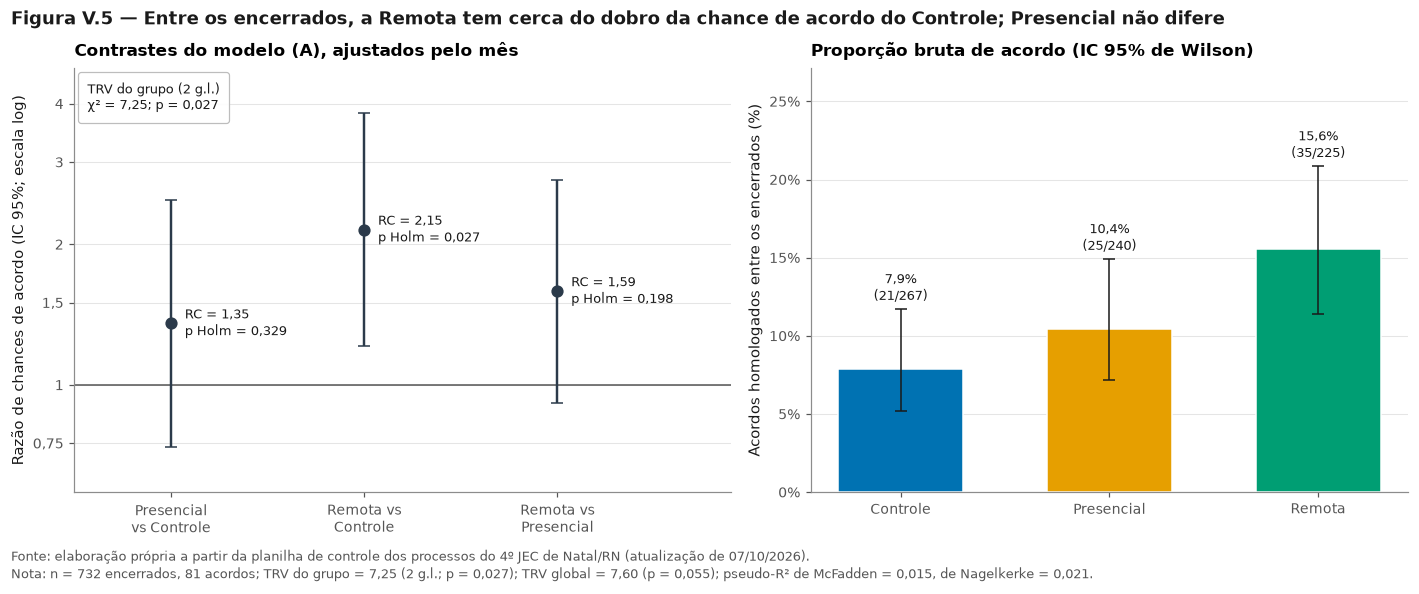

In [38]:
enc = mul[mul['encerrado_b']].copy()

def mul_logit(formula, dados_mod, formula_red=None, nome=''):
    res = smf.logit(formula, data=dados_mod).fit(disp=0)
    n = res.nobs
    cs = 1 - np.exp(2 * (res.llnull - res.llf) / n)
    nag = cs / (1 - np.exp(2 * res.llnull / n))
    saida = {'res': res, 'mcfadden': res.prsquared, 'nagelkerke': nag, 'n': int(n), 'eventos': int(res.model.endog.sum())}
    if formula_red is not None:
        red = smf.logit(formula_red, data=dados_mod).fit(disp=0)
        saida['trv'] = 2 * (res.llf - red.llf)
        saida['trv_gl'] = int(res.df_model - red.df_model)
        saida['trv_p'] = stats.chi2.sf(saida['trv'], saida['trv_gl'])
    return saida

def mul_tab_rc(res):
    ic = np.exp(res.conf_int())
    return pd.DataFrame({'Termo': [NOMES_COEF.get(i, i) for i in res.params.index],
                         'RC': np.exp(res.params).to_numpy(), 'IC 95% inf.': ic[0].to_numpy(),
                         'IC 95% sup.': ic[1].to_numpy(), 'z (Wald)': res.tvalues.to_numpy(),
                         'p (Wald)': res.pvalues.to_numpy()})


FMT_RC = {'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3, 'z (Wald)': 2}

def mul_contrastes_grupo(res):
    # três contrastes de grupo, Wald, com Holm
    b, V = res.params, res.cov_params()
    P, R = 'C(grupo)[T.Presencial]', 'C(grupo)[T.Remota]'
    cont = {'Presencial vs Controle': (b[P], V.loc[P, P]), 'Remota vs Controle': (b[R], V.loc[R, R]),
            'Remota vs Presencial': (b[R] - b[P], V.loc[R, R] + V.loc[P, P] - 2 * V.loc[P, R])}
    lin = []
    for k, (est, var) in cont.items():
        ep = np.sqrt(var)
        lin.append({'Contraste': k, 'RC': np.exp(est), 'li': np.exp(est - 1.96 * ep), 'ls': np.exp(est + 1.96 * ep),
                    'p': 2 * stats.norm.sf(abs(est / ep))})
    t = pd.DataFrame(lin)
    t['p Holm'] = multipletests(t['p'], method='holm')[1]
    return t

def mul_mostra_contrastes(t):
    return pd.DataFrame({'Contraste': t['Contraste'], 'RC': t['RC'], 'IC 95% inf.': t['li'], 'IC 95% sup.': t['ls'],
                         'p (Wald)': t['p'], 'p (Holm)': t['p Holm']})


def mul_barras_prop(ax, tx, ylabel):
    """Proporção por grupo (barras verticais) com IC de Wilson e rótulo 'x,x% (s/n)' acima do IC."""
    p = tx['sum'] / tx['count']
    li, ls = mul_ic_wilson(tx['sum'], tx['count'])
    grupos = [str(g) for g in tx.index]
    barras_verticais(ax, grupos, p, cores=CORES_GRUPO, rotular=False, erro=(li, ls), ylabel=ylabel)
    for i, (s, n, pi, hi) in enumerate(zip(tx['sum'], tx['count'], p, ls)):
        ax.annotate(f'{pct_br(pi)}\n({int(s)}/{int(n)})', (i, hi), xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8.5, color=TINTA)
    ax.set_ylim(0, max(ls) * 1.3)
    eixo_pct(ax)


modA = mul_logit('homolog ~ C(grupo) + mes_num', enc, 'homolog ~ mes_num')
resA = modA['res']
contA = mul_contrastes_grupo(resA)
nota_A = (f"n = {modA['n']} encerrados, {modA['eventos']} acordos; TRV do grupo = {fmt_br(modA['trv'], 2)} "
          f"({modA['trv_gl']} g.l.; p {mul_peq(modA['trv_p'])}); TRV global = {fmt_br(resA.llr, 2)} (p {mul_peq(resA.llr_pvalue)}); "
          f"pseudo-R² de McFadden = {fmt_br(modA['mcfadden'], 3)}, de Nagelkerke = {fmt_br(modA['nagelkerke'], 3)}.")
tabela(mul_tab_rc(resA), 'mul_logit_A', 'Modelo (A): razões de chances de acordo entre os encerrados (logit acordo ~ grupo + mês)',
       secao='5.2.1', formatos=FMT_RC, destaque='p (Wald)', nota=nota_A + ' Referência: Controle. Destaque: p < 0,05.')
tabela(mul_mostra_contrastes(contA), 'mul_logit_A_contrastes',
       'Modelo (A): os três contrastes de grupo (Wald, com correção de Holm)', secao='5.2.1',
       formatos={'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}, destaque='p (Holm)',
       nota='RC = razão de chances de acordo, ajustada pelo mês. Destaque: p de Holm < 0,05.')
mul_res['A'] = modA
mul_res['contA'] = contA

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = eixos[0]
mul_forest(ax, contA['RC'], contA['li'], contA['ls'],
           textos=[f"RC = {fmt_br(r['RC'], 2)}\np Holm {mul_peq(r['p Holm'])}" for _, r in contA.iterrows()])
mul_eixo_razao(ax, np.r_[contA['li'], contA['ls']])
ax.set_xticks(range(3), [quebra(c, 12) for c in contA['Contraste']])
ax.set_xlim(-0.5, 2.9)
ax.set(ylabel='Razão de chances de acordo (IC 95%; escala log)', title='Contrastes do modelo (A), ajustados pelo mês')
anotar_teste(ax, texto_teste('TRV do grupo (2 g.l.)', f"χ² = {fmt_br(modA['trv'], 2)}", modA['trv_p']), loc='upper left')
ax = eixos[1]
tx = enc.groupby('grupo', observed=True)['homolog'].agg(['sum', 'count'])
mul_barras_prop(ax, tx, 'Acordos homologados entre os encerrados (%)')
ax.set_title('Proporção bruta de acordo (IC 95% de Wilson)')
figura(fig, 'mul_logit_A_rc', 'Entre os encerrados, a Remota tem cerca do dobro da chance de acordo do Controle; '
       'Presencial não difere', secao='5.2.1', nota=nota_A)

**Interpretação.** Entre os 732 processos encerrados (81 acordos homologados), a proporção de acordo cresce do Controle (21/267, 7,9%) para a Presencial (25/240, 10,4%) e a Remota (35/225, 15,6%). O **TRV do grupo** rejeita H0 (χ² = 7,25; 2 g.l.; p = 0,027). Nos contrastes com Holm, só **Remota × Controle** é significativo: **RC = 2,15** (IC 95% 1,21 a 3,81; p Holm = 0,027). Presencial × Controle (RC = 1,35; p Holm = 0,329) e Remota × Presencial (RC = 1,59; p Holm = 0,198) não se distinguem. O mês não se associa ao acordo (RC = 0,965 por mês; p = 0,591). O pseudo-R² é muito baixo (McFadden 0,015; Nagelkerke 0,021), como esperado num modelo só com grupo e mês: o rito altera a chance média de acordo, mas explica pouquíssimo de **qual** processo fará acordo.

**Leitura jurídica.** A audiência remota obrigatória associa-se a uma chance de acordo cerca de duas vezes maior que no rito atual. Como 64 dos 81 acordos ocorreram **fora** da audiência, o efeito não é só da sessão em si: a designação da audiência parece estimular a negociação entre as partes. Ressalva: o modelo é condicional a ter encerrado, e a Remota tem mais processos ainda ativos; a sensibilidade em horizontes fixos (5.2.5) trata desse ponto.

### 5.2.2 Multicolinearidade (VIF)

O fator de inflação da variância, VIFⱼ = 1/(1 − R²ⱼ), mede quanto a variância de β̂ⱼ é inflada pela correlação de xⱼ com os demais preditores. Referências usuais: VIF > 5 merece atenção e VIF > 10 indica colinearidade grave. Calcula-se para o modelo (A) e, para mostrar por que o seguimento não entra junto com o mês, para o modelo (A) acrescido de log(seguimento).

Preditor,VIF modelo (A),VIF (A) + log(seguimento)
Mês de distribuição (+1 mês),"1,00","17,40"
Presencial vs Controle,"1,28","1,28"
Remota vs Controle,"1,28","1,28"
log(seguimento),–,"17,42"


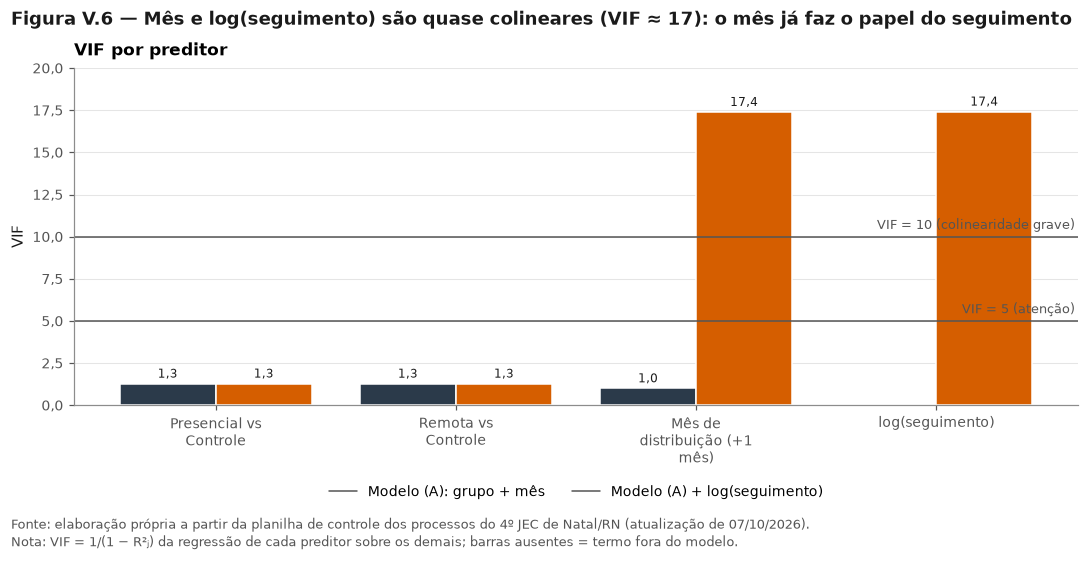

In [39]:
def mul_vif(res):
    X = pd.DataFrame(res.model.exog, columns=res.model.exog_names)
    return pd.Series({NOMES_COEF.get(c, c): variance_inflation_factor(X.values, i)
                      for i, c in enumerate(X.columns) if c != 'Intercept'})

vifA = mul_vif(resA)
resA_fu = smf.logit('homolog ~ C(grupo) + mes_num + log_followup', data=enc).fit(disp=0)
vifA_fu = mul_vif(resA_fu)
tab_vif = pd.DataFrame({'VIF modelo (A)': vifA, 'VIF (A) + log(seguimento)': vifA_fu}).rename_axis('Preditor')
tabela(tab_vif, 'mul_vif', 'Fator de inflação da variância (VIF) dos preditores do modelo (A), sem e com o seguimento',
       secao='5.2.2', casas=2, nota='VIF > 5 merece atenção; VIF > 10 indica colinearidade grave. "–": termo fora do modelo.')
fig, ax = plt.subplots(figsize=(10, 4.6))
nomes = list(vifA_fu.index)
barras_agrupadas(ax, tab_vif.reindex(nomes), cores={'VIF modelo (A)': COR_MODELO, 'VIF (A) + log(seguimento)': COR_VIES},
                 rotular=True, fmt=lambda v: fmt_br(v, 1), quebrar=16, ylabel='VIF', legenda=False)
for lim, txt in [(5, 'VIF = 5 (atenção)'), (10, 'VIF = 10 (colinearidade grave)')]:
    ax.axhline(lim, color=TINTA_2, lw=1, zorder=1)
    ax.annotate(txt, (1, lim), xycoords=('axes fraction', 'data'), xytext=(-2, 3), textcoords='offset points',
                ha='right', va='bottom', fontsize=8.5, color=TINTA_2)
ax.set_title('VIF por preditor')
legenda_abaixo(ax, ncol=2, dy=-0.2, labels=['Modelo (A): grupo + mês', 'Modelo (A) + log(seguimento)'])
figura(fig, 'mul_vif', 'Mês e log(seguimento) são quase colineares (VIF ≈ 17): o mês já faz o papel do seguimento',
       secao='5.2.2', nota='VIF = 1/(1 − R²ⱼ) da regressão de cada preditor sobre os demais; barras ausentes = termo fora do modelo.')

**Interpretação.** No modelo (A) não há colinearidade: VIF = 1,00 para o mês e 1,28 para os indicadores de grupo (a correlação entre os dois indicadores é inerente à codificação de três categorias). Ao acrescentar log(seguimento), o VIF do mês e o do seguimento saltam para **17,4**, bem acima do limite de 10: as duas variáveis carregam a mesma informação (r = −0,97), porque o seguimento é a distância entre a distribuição e a data de corte. Por isso a diferença de seguimento é controlada **pelo mês** no modelo (A) e, de modo mais limpo, pelos horizontes fixos de 5.2.5, e não pela inclusão simultânea das duas variáveis.

### 5.2.3 Calibração: teste de Hosmer-Lemeshow

Ordenam-se os processos pela probabilidade prevista π̂ e formam-se g = 10 grupos; HL = Σ (Oₖ − nₖπ̄ₖ)² / [nₖπ̄ₖ(1 − π̄ₖ)] segue χ² com g − 2 g.l. (ARTES; BARROSO, 2023, eq. 10.4, p. 358-359). H0: o modelo está calibrado (as frequências observadas de acordo coincidem com as previstas em cada grupo); H1: não está. Como só há 24 padrões de covariáveis (3 grupos × 8 meses), muitos processos têm a mesma π̂; os empates são repartidos pela ordem (rank), o que mantém os 10 grupos. O gráfico de calibração (observado × previsto, com IC de Wilson) é o gráfico do teste.

Hosmer-Lemeshow modelo (A): HL = 9,18, 8 g.l., p 0,327


Decil de π̂,Processos (n),Acordos observados (O),π̂ média,Acordos esperados (E = n·π̂)
1,74,8,"0,073","5,4"
2,73,5,"0,077","5,6"
3,73,7,"0,081","5,9"
4,73,2,"0,089","6,5"
5,73,7,"0,100","7,3"
6,73,11,"0,105","7,7"
7,73,7,"0,113","8,3"
8,73,8,"0,146","10,7"
9,73,15,"0,156","11,4"
10,74,11,"0,165","12,2"


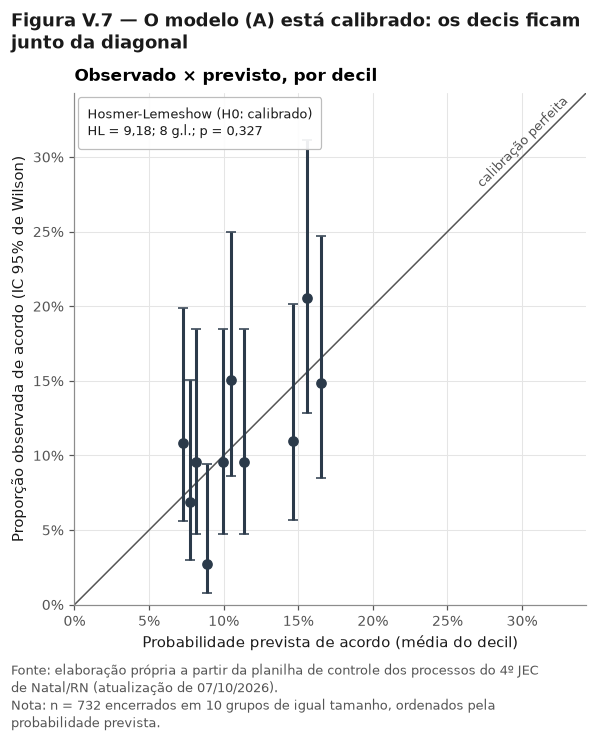

In [40]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({'y': np.asarray(y, float), 'p': np.asarray(p, float)})
    t['grp'] = pd.qcut(t['p'].rank(method='first'), g, labels=False)
    agg = t.groupby('grp').agg(n=('y', 'size'), O=('y', 'sum'), pbar=('p', 'mean'))
    agg['E'] = agg['n'] * agg['pbar']
    hl = (((agg['O'] - agg['E']) ** 2) / (agg['E'] * (1 - agg['pbar']))).sum()
    return hl, g - 2, stats.chi2.sf(hl, g - 2), agg

def grafico_calibracao(ax, agg, titulo):
    li, ls = mul_ic_wilson(agg['O'], agg['n'])
    obs = agg['O'] / agg['n']
    ax.errorbar(agg['pbar'], obs, yerr=[obs - li, ls - obs], fmt='o', ms=6, color=COR_MODELO, capsize=3, zorder=3)
    lim = max(agg['pbar'].max(), ls.max()) * 1.1
    ax.plot([0, lim], [0, lim], color=TINTA_2, lw=1, zorder=1)
    ax.annotate('calibração perfeita', (lim * 0.97, lim * 0.97), ha='right', va='bottom', fontsize=8.5, color=TINTA_2,
                rotation=45, rotation_mode='anchor', xytext=(0, 3), textcoords='offset points')
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel='Probabilidade prevista de acordo (média do decil)',
           ylabel='Proporção observada de acordo (IC 95% de Wilson)', title=titulo)
    ax.set_aspect('equal')
    eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
    ax.grid(axis='both', visible=True)

hlA, glA, pA_hl, aggA = hosmer_lemeshow(resA.model.endog, resA.predict())
mul_res['hlA'] = (hlA, pA_hl)
print(f'Hosmer-Lemeshow modelo (A): HL = {fmt_br(hlA, 2)}, {glA} g.l., p {p_br(pA_hl)}')
tab_hl = pd.DataFrame({'Decil de π̂': np.arange(1, len(aggA) + 1), 'Processos (n)': aggA['n'].to_numpy(),
                       'Acordos observados (O)': aggA['O'].to_numpy(), 'π̂ média': aggA['pbar'].to_numpy(),
                       'Acordos esperados (E = n·π̂)': aggA['E'].to_numpy()})
tabela(tab_hl, 'mul_hl', 'Teste de Hosmer-Lemeshow do modelo (A): acordos observados × esperados por decil de probabilidade',
       secao='5.2.3', formatos={'π̂ média': 3, 'Acordos esperados (E = n·π̂)': 1},
       nota=f'HL = {fmt_br(hlA, 2)}, {glA} g.l., p {mul_peq(pA_hl)} (H0: modelo calibrado).')
fig, ax = plt.subplots(figsize=(6, 5.6))
grafico_calibracao(ax, aggA, 'Observado × previsto, por decil')
anotar_teste(ax, texto_teste('Hosmer-Lemeshow (H0: calibrado)', f'HL = {fmt_br(hlA, 2)}; {glA} g.l.', pA_hl),
             loc='upper left')
figura(fig, 'mul_hl', 'O modelo (A) está calibrado: os decis ficam junto da diagonal', secao='5.2.3',
       nota=f'n = {modA["n"]} encerrados em 10 grupos de igual tamanho, ordenados pela probabilidade prevista.')

**Interpretação.** HL = 9,18 com 8 g.l. (p = 0,327): não se rejeita H0, e o modelo está **calibrado**. As probabilidades previstas vão de 7,3% a 16,5%, e as proporções observadas por decil oscilam em torno da diagonal, dentro dos IC de Wilson. Duas ressalvas: com apenas 81 eventos (5 a 8 por decil), o teste tem pouco poder; e calibração não é discriminação. Um modelo pode acertar as médias por grupo e mês, que é o que este faz, sem separar bem os processos individualmente (5.2.4).

### 5.2.4 Discriminação: ROC, AUC, Gini e KS

Calibração diz se as probabilidades são corretas *em média*; discriminação diz se o modelo **ordena** bem quem faz e quem não faz acordo.

- **AUC** (área sob a curva ROC): probabilidade de um processo com acordo ter π̂ maior que um sem acordo. Referências de Hosmer, Lemeshow e Sturdivant reproduzidas por Artes e Barroso (2023, tab. 10.3, p. 365): 0,5 sem discriminação; 0,5-0,7 pobre; 0,7-0,8 aceitável; 0,8-0,9 excelente; ≥ 0,9 excepcional. IC 95% por *bootstrap* percentil (2.000 reamostras).
- **Gini** = 2·AUC − 1 (p. 364).
- **KS**: distância máxima entre as funções de distribuição dos escores dos dois grupos (eq. 10.5, p. 365-367). O teste KS de duas amostras tem H0: os escores de quem fez e de quem não fez acordo têm a mesma distribuição.
- **Validação**: a AUC na própria amostra é otimista. Artes e Barroso recomendam separar 20-30% para validação (p. 359); aqui usam-se uma partição 70/30 estratificada e a validação cruzada estratificada em 10 partes.

AUC (amostra toda) = 0,591 (IC 95% bootstrap 0,523 a 0,660); Gini = 0,182
AUC validação 70/30 = 0,486; AUC validação cruzada 10 partes = 0,546
KS = 0,161 (p 0,042)


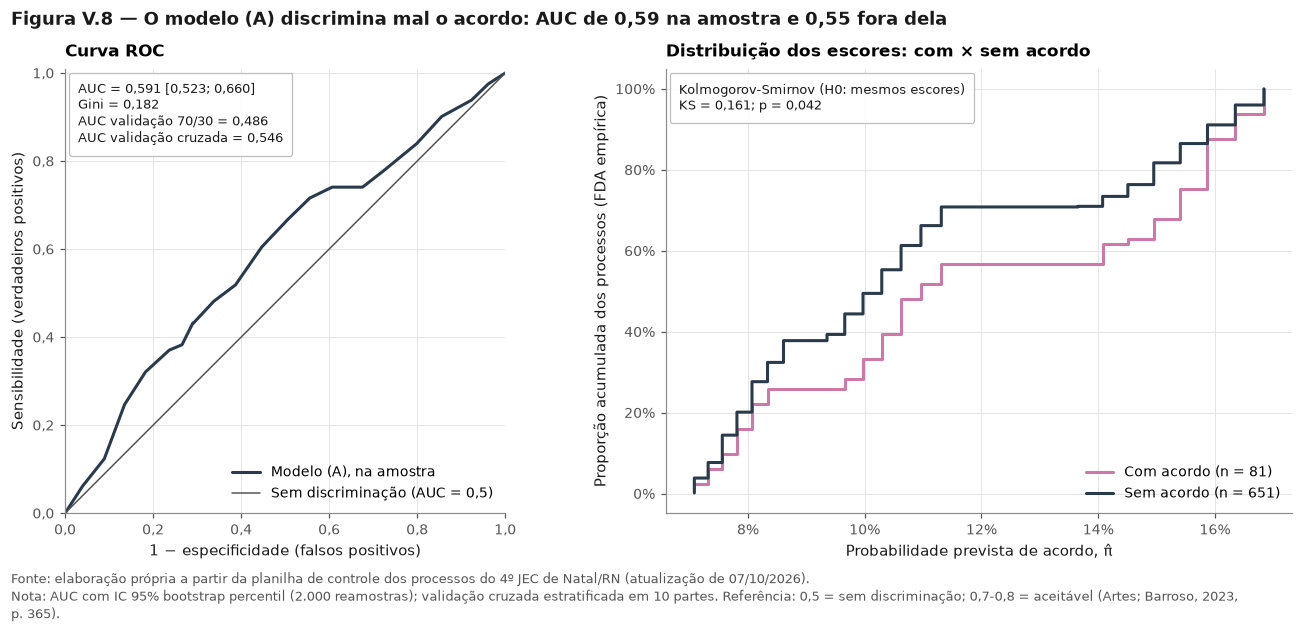

In [41]:
def auc_bootstrap(y, p, B=2000, rng=RNG_MUL):
    y, p = np.asarray(y), np.asarray(p)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

def ks_escores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    r = stats.ks_2samp(p[y == 1], p[y == 0])
    return r.statistic, r.pvalue

def auc_validacao(formula, dados_mod, resposta, k=10, rng_seed=SEMENTE):
    y = dados_mod[resposta].values
    # 70/30 estratificado
    rng = np.random.default_rng(rng_seed)
    idx_val = np.concatenate([rng.choice(np.where(y == c)[0], int(round(0.3 * (y == c).sum())), replace=False) for c in (0, 1)])
    mask = np.zeros(len(y), bool); mask[idx_val] = True
    r = smf.logit(formula, data=dados_mod[~mask]).fit(disp=0)
    auc_7030 = roc_auc_score(y[mask], r.predict(dados_mod[mask]))
    # k-fold estratificado
    prev = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=rng_seed).split(np.zeros(len(y)), y):
        r = smf.logit(formula, data=dados_mod.iloc[tr]).fit(disp=0)
        prev[te] = r.predict(dados_mod.iloc[te])
    return auc_7030, roc_auc_score(y, prev)

yA, pA = resA.model.endog, resA.predict()
aucA = roc_auc_score(yA, pA)
icA = auc_bootstrap(yA, pA)
ksA, ksA_p = ks_escores(yA, pA)
auc7030A, auccvA = auc_validacao('homolog ~ C(grupo) + mes_num', enc, 'homolog')
mul_res['aucA'] = (aucA, icA, auccvA, ksA)
print(f'AUC (amostra toda) = {fmt_br(aucA, 3)} (IC 95% bootstrap {fmt_br(icA[0], 3)} a {fmt_br(icA[1], 3)}); '
      f'Gini = {fmt_br(2 * aucA - 1, 3)}')
print(f'AUC validação 70/30 = {fmt_br(auc7030A, 3)}; AUC validação cruzada 10 partes = {fmt_br(auccvA, 3)}')
print(f'KS = {fmt_br(ksA, 3)} (p {p_br(ksA_p)})')

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 5))
fpr, tpr, _ = roc_curve(yA, pA)
ax = eixos[0]
ax.plot(fpr, tpr, color=COR_MODELO, lw=2, label='Modelo (A), na amostra')
ax.plot([0, 1], [0, 1], color=TINTA_2, lw=1, label='Sem discriminação (AUC = 0,5)')
ax.set(xlabel='1 − especificidade (falsos positivos)', ylabel='Sensibilidade (verdadeiros positivos)',
       title='Curva ROC', xlim=(0, 1), ylim=(0, 1.01))
ax.set_aspect('equal')
ax.grid(axis='both', visible=True)
ax.legend(loc='lower right')
anotar_teste(ax, f'AUC = {mul_ic(aucA, *icA)}\nGini = {fmt_br(2 * aucA - 1, 3)}\n'
                 f'AUC validação 70/30 = {fmt_br(auc7030A, 3)}\nAUC validação cruzada = {fmt_br(auccvA, 3)}',
             loc='upper left')
ax = eixos[1]
for c, cor, rot in [(1, CORES_DESFECHO['Homologação'], 'Com acordo'), (0, COR_MODELO, 'Sem acordo')]:
    v = np.sort(pA[yA == c])
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where='post', color=cor, lw=2,
            label=f'{rot} (n = {fmt_br(len(v), 0)})')
ax.set(xlabel='Probabilidade prevista de acordo, π̂', ylabel='Proporção acumulada dos processos (FDA empírica)',
       title='Distribuição dos escores: com × sem acordo')
eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
ax.grid(axis='both', visible=True)
ax.legend(loc='lower right')
anotar_teste(ax, texto_teste('Kolmogorov-Smirnov (H0: mesmos escores)', f'KS = {fmt_br(ksA, 3)}', ksA_p), loc='upper left')
figura(fig, 'mul_roc_A', f'O modelo (A) discrimina mal o acordo: AUC de {fmt_br(aucA, 2)} na amostra e '
       f'{fmt_br(auccvA, 2)} fora dela',
       secao='5.2.4', nota='AUC com IC 95% bootstrap percentil (2.000 reamostras); validação cruzada estratificada em 10 partes. '
                           'Referência: 0,5 = sem discriminação; 0,7-0,8 = aceitável (Artes; Barroso, 2023, p. 365).')

**Interpretação.** Na própria amostra, AUC = **0,591** (IC 95% *bootstrap* 0,523 a 0,660), Gini = 0,182 e KS = 0,161 (p = 0,042). Pela tabela de referência (ARTES; BARROSO, 2023, tab. 10.3, p. 365), a discriminação é **pobre** (faixa 0,5-0,7). Fora da amostra, ela cai mais: **0,546** em validação cruzada de 10 partes e **0,486** na partição 70/30. A partição única de 30% (cerca de 24 acordos) é muito instável, e a validação cruzada é a estimativa mais confiável. O KS "significativo" diz apenas que as distribuições dos escores diferem (porque a Remota tem mais acordos), não que o modelo classifica bem.

**Conclusão.** O grupo tem um efeito **populacional** detectável sobre a chance de acordo (5.2.1), mas é inútil como **classificador** de processos individuais. Isso é o que se espera de um experimento em que a única variável manipulada é o rito e não há covariáveis do caso.

### 5.2.5 Sensibilidade ao seguimento: horizontes fixos de 60 e 120 dias

Repete-se o modelo com as definições (B) e (C), em que todos os processos incluídos foram observados durante todo o horizonte, de modo que "não acordo até τ" é informação completa (não há censura antes de τ). O que importa é se a RC do grupo muda de direção ou de magnitude em relação ao modelo (A).

Definição,n,Acordos,Contraste,RC,IC 95% inf.,IC 95% sup.,p (Holm),p do TRV do grupo
(A) encerrados,732,81,Presencial vs Controle,"1,354","0,737","2,489","0,329","0,027"
(A) encerrados,732,81,Remota vs Controle,"2,149","1,211","3,813","0,027","0,027"
(A) encerrados,732,81,Remota vs Presencial,"1,587","0,916","2,749","0,198","0,027"
"(B) até 60 dias, todos",938,40,Presencial vs Controle,"1,339","0,577","3,107","0,818","0,318"
"(B) até 60 dias, todos",938,40,Remota vs Controle,"1,830","0,822","4,074","0,416","0,318"
"(B) até 60 dias, todos",938,40,Remota vs Presencial,"1,367","0,651","2,871","0,818","0,318"
"(C) até 120 dias, seguimento ≥ 120",688,61,Presencial vs Controle,"1,980","0,956","4,101","0,132","0,015"
"(C) até 120 dias, seguimento ≥ 120",688,61,Remota vs Controle,"2,703","1,333","5,481","0,018","0,015"
"(C) até 120 dias, seguimento ≥ 120",688,61,Remota vs Presencial,"1,365","0,752","2,479","0,307","0,015"


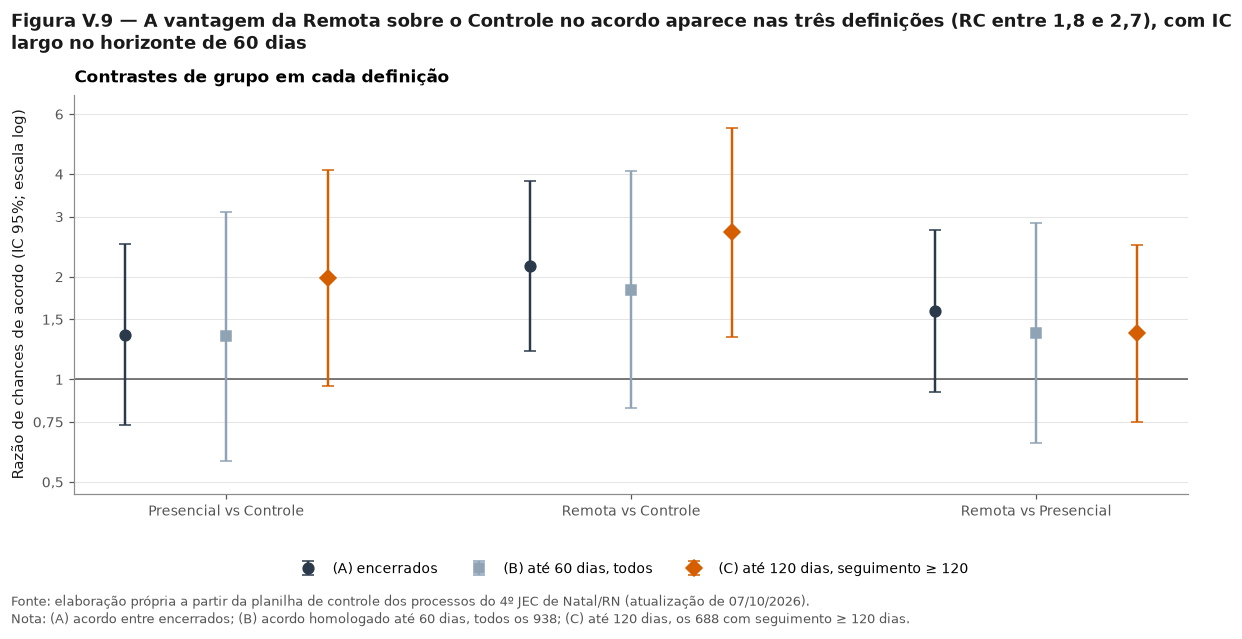

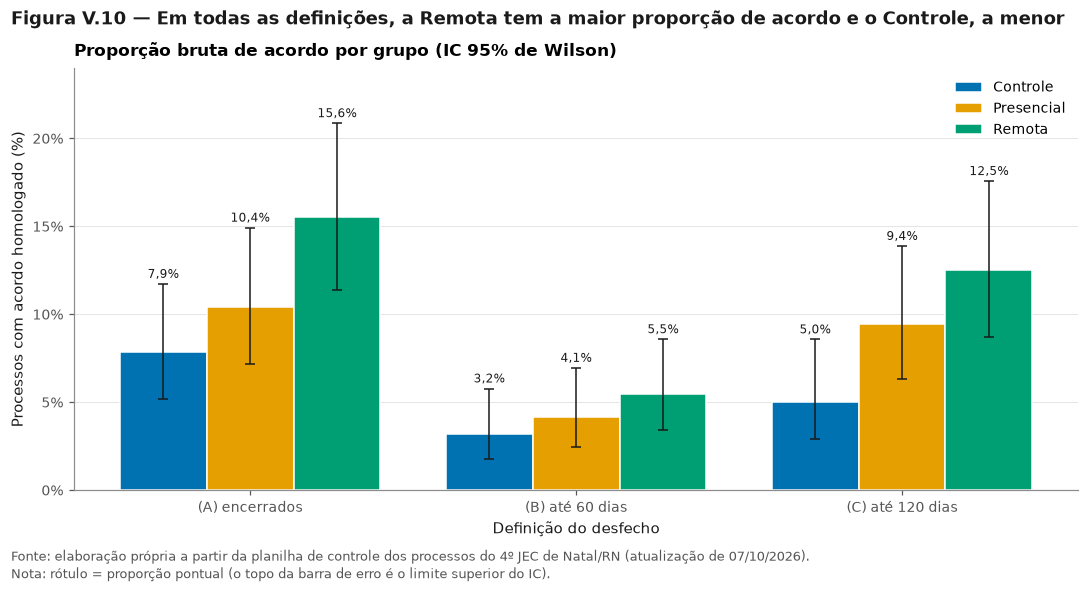

In [42]:
mul['acordo60'] = ((mul['homolog'] == 1) & (mul['T'] <= 60)).astype(int)
mul['acordo120'] = ((mul['homolog'] == 1) & (mul['T'] <= 120)).astype(int)
base120 = mul[mul['followup_f'] >= 120].copy()
modB = mul_logit('acordo60 ~ C(grupo) + mes_num', mul, 'acordo60 ~ mes_num')
modC = mul_logit('acordo120 ~ C(grupo) + mes_num', base120, 'acordo120 ~ mes_num')
mul_res['B'], mul_res['C'] = modB, modC
cont_h = []
for rot, m in [('(A) encerrados', modA), ('(B) até 60 dias, todos', modB), ('(C) até 120 dias, seguimento ≥ 120', modC)]:
    t = mul_contrastes_grupo(m['res'])
    t.insert(0, 'Definição', rot)
    t['n'], t['acordos'], t['TRV p'] = m['n'], m['eventos'], m['trv_p']
    cont_h.append(t)
cont_h = pd.concat(cont_h, ignore_index=True)
mul_res['cont_h'] = cont_h
tabela(pd.DataFrame({'Definição': cont_h['Definição'], 'n': cont_h['n'], 'Acordos': cont_h['acordos'],
                     'Contraste': cont_h['Contraste'], 'RC': cont_h['RC'], 'IC 95% inf.': cont_h['li'],
                     'IC 95% sup.': cont_h['ls'], 'p (Holm)': cont_h['p Holm'], 'p do TRV do grupo': cont_h['TRV p']}),
       'mul_logit_horizontes', 'Razões de chances de acordo por grupo nas três definições do desfecho (A, B, C)',
       secao='5.2.5', formatos={'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}, destaque='p (Holm)',
       nota='modelos logit acordo ~ grupo + mês; contrastes de Wald com Holm dentro de cada definição. Destaque: p de Holm < 0,05.')

defs = list(dict.fromkeys(cont_h['Definição']))
cores_def = dict(zip(defs, [COR_MODELO, '#8FA3B5', COR_VIES]))
fig, ax = plt.subplots(figsize=(11, 5))
for j, d in enumerate(defs):
    t = cont_h[cont_h['Definição'] == d].reset_index(drop=True)
    mul_forest(ax, t['RC'], t['li'], t['ls'], x=np.arange(3) + (j - 1) * 0.25, cor=cores_def[d], label=d,
               marker=['o', 's', 'D'][j])
mul_eixo_razao(ax, np.r_[cont_h['li'], cont_h['ls']])
ax.set_xticks(range(3), list(contA['Contraste']))
ax.set(ylabel='Razão de chances de acordo (IC 95%; escala log)', title='Contrastes de grupo em cada definição')
legenda_abaixo(ax, ncol=3, dy=-0.14)
figura(fig, 'mul_logit_horizontes_rc', 'A vantagem da Remota sobre o Controle no acordo aparece nas três definições '
       '(RC entre 1,8 e 2,7), com IC largo no horizonte de 60 dias', secao='5.2.5',
       nota='(A) acordo entre encerrados; (B) acordo homologado até 60 dias, todos os 938; (C) até 120 dias, os 688 com seguimento ≥ 120 dias.')

tab_def = {}
erros_def = {}
for rot, col, base in [('(A) encerrados', 'homolog', enc), ('(B) até 60 dias', 'acordo60', mul),
                       ('(C) até 120 dias', 'acordo120', base120)]:
    tx = base.groupby('grupo', observed=True)[col].agg(['sum', 'count'])
    tab_def[rot] = tx['sum'] / tx['count']
    erros_def[rot] = mul_ic_wilson(tx['sum'], tx['count'])
tab_def = pd.DataFrame(tab_def).T[ORDEM_GRUPO]
fig, ax = plt.subplots(figsize=(10, 4.8))
barras_agrupadas(ax, tab_def, cores=CORES_GRUPO, rotular=True, fmt=lambda v: pct_br(v, 1), quebrar=18,
                 erro={g: (np.array([erros_def[d][0][g] for d in tab_def.index]),
                           np.array([erros_def[d][1][g] for d in tab_def.index])) for g in ORDEM_GRUPO},
                 ylabel='Processos com acordo homologado (%)', xlabel='Definição do desfecho')
eixo_pct(ax)
ax.set_title('Proporção bruta de acordo por grupo (IC 95% de Wilson)')
figura(fig, 'mul_logit_horizontes_prop', 'Em todas as definições, a Remota tem a maior proporção de acordo e o Controle, a menor',
       secao='5.2.5', nota='rótulo = proporção pontual (o topo da barra de erro é o limite superior do IC).')

**Interpretação.** A direção do efeito é estável nas três definições: a Remota tem sempre a maior chance de acordo e a Presencial fica entre a Remota e o Controle.

- **(B) até 60 dias, todos os 938** (sem viés de seguimento, mas com só 40 acordos): Remota × Controle RC = 1,83 (IC 0,82 a 4,07) e TRV do grupo p = 0,318. O efeito tem a mesma direção, sem poder para ser detectado, porque a maior parte dos acordos é homologada depois de 60 dias.
- **(C) até 120 dias, seguimento ≥ 120** (688 processos, 61 acordos, sem viés de seguimento): **Remota × Controle RC = 2,70** (IC 1,33 a 5,48; p Holm = 0,018), Presencial × Controle RC = 1,98 (IC 0,96 a 4,10; p Holm = 0,132) e TRV do grupo p = 0,015.

A definição (C), que é a mais limpa, **confirma e reforça** o modelo (A). O efeito da Remota sobre o acordo não é artefato da diferença de seguimento. A análise com riscos competitivos (função de incidência acumulada da homologação, Parte IV) é o complemento natural, porque usa todos os processos sem escolher um horizonte.

### 5.2.6 Acordo **na audiência**, no subconjunto com audiência realizada

Aqui a resposta é `acordo_ac` e a amostra são os 352 processos com audiência realizada (só Presencial e Remota: no Controle o acordo em audiência é zero estrutural, E20). Preditores: modalidade (Remota × Presencial), audiência **híbrida** (uma parte remota numa pauta presencial, Res. CNJ 481) e mês. A híbrida é **pós-sorteio**: a RC é associação, não efeito causal.

**Cuidado com poucos eventos.** Há só 17 acordos em audiência. A regra prática de ~10 eventos por parâmetro (EPV) admite no máximo 1 ou 2 preditores; com 3, as estimativas por máxima verossimilhança são instáveis e os IC largos. O resultado é exploratório. TRV do modelo: H0: nenhum preditor associa-se ao acordo em audiência.

Grupo,Audiência,Acordo na AC,Sem acordo na AC,Total,% com acordo
Presencial,híbrida,1,23,24,"4,2"
Presencial,não híbrida,8,146,154,"5,2"
Remota,híbrida,0,2,2,"0,0"
Remota,não híbrida,8,164,172,"4,7"


Termo,RC,IC 95% inf.,IC 95% sup.,z (Wald),p (Wald)
Intercepto,"0,123","0,038","0,403","-3,47","< 0,001"
Remota vs Presencial,"0,841","0,309","2,291","-0,34","0,735"
Híbrida (sim),"0,689","0,084","5,682","-0,35","0,729"
Mês de distribuição (+1 mês),"0,810","0,616","1,063","-1,52","0,129"


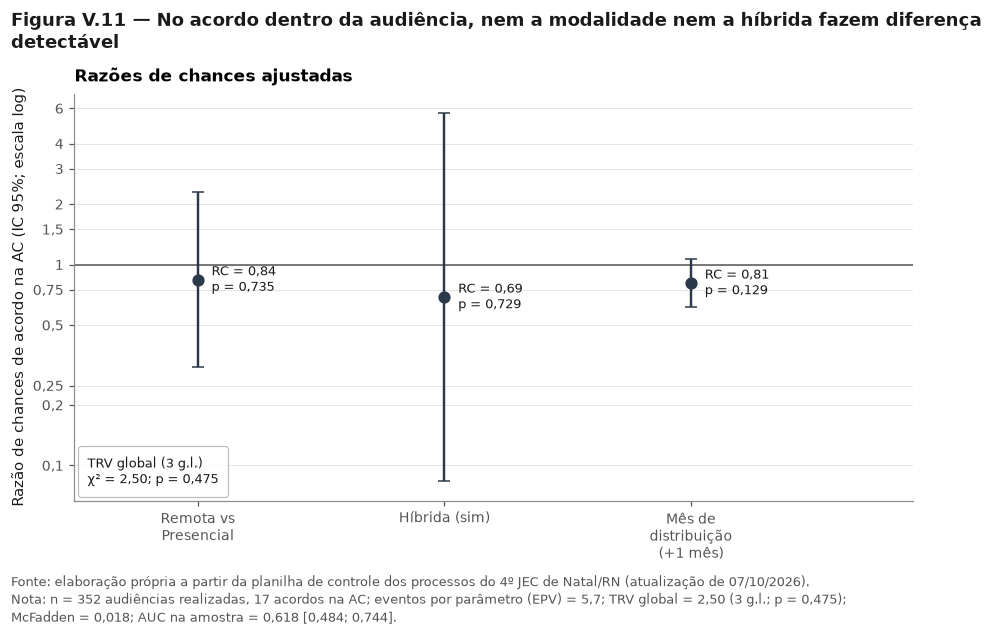

In [43]:
sub_ac = mul[mul['ac_realizada'].fillna(False).astype(bool)].copy()
sub_ac['y_ac'] = sub_ac['acordo_ac'].astype(int)
tab_ac = pd.crosstab([sub_ac['grupo'].astype(str), sub_ac['hibrida_b'].map({0: 'não híbrida', 1: 'híbrida'})],
                     sub_ac['y_ac'].map({0: 'Sem acordo na AC', 1: 'Acordo na AC'}))
tab_ac = tab_ac.rename_axis(columns=None).reset_index().rename(columns={'grupo': 'Grupo', 'hibrida_b': 'Audiência'})
tab_ac['Total'] = tab_ac['Sem acordo na AC'] + tab_ac['Acordo na AC']
tab_ac['% com acordo'] = 100 * tab_ac['Acordo na AC'] / tab_ac['Total']
tabela(tab_ac[['Grupo', 'Audiência', 'Acordo na AC', 'Sem acordo na AC', 'Total', '% com acordo']], 'mul_ac_hibrida',
       'Acordo na audiência por modalidade e audiência híbrida (processos com AC realizada)', secao='5.2.6',
       nota='só Presencial e Remota: no Controle não há audiência obrigatória (zero estrutural).')
modAC = mul_logit('y_ac ~ remota + hibrida_b + mes_num', sub_ac)
resAC = modAC['res']
epv = modAC['eventos'] / resAC.df_model
aucAC = roc_auc_score(resAC.model.endog, resAC.predict())
icAC = auc_bootstrap(resAC.model.endog, resAC.predict())
mul_res['AC'] = (modAC, aucAC, icAC)
nota_AC = (f"n = {modAC['n']} audiências realizadas, {modAC['eventos']} acordos na AC; eventos por parâmetro (EPV) = {fmt_br(epv, 1)}; "
           f"TRV global = {fmt_br(resAC.llr, 2)} ({int(resAC.df_model)} g.l.; p {mul_peq(resAC.llr_pvalue)}); "
           f"McFadden = {fmt_br(modAC['mcfadden'], 3)}; AUC na amostra = {mul_ic(aucAC, *icAC)}.")
tabela(mul_tab_rc(resAC), 'mul_logit_ac', 'Logit do acordo na audiência ~ modalidade + híbrida + mês (exploratório: 17 eventos)',
       secao='5.2.6', formatos=FMT_RC, destaque='p (Wald)', nota=nota_AC + ' Referência da modalidade: Presencial.')
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ic = np.exp(resAC.conf_int()).iloc[1:]
rc = np.exp(resAC.params).iloc[1:]
mul_forest(ax, rc, ic[0], ic[1], textos=[f'RC = {fmt_br(rc[t], 2)}\np {mul_peq(resAC.pvalues[t])}' for t in rc.index])
mul_eixo_razao(ax, np.r_[ic[0], ic[1]])
ax.set_xticks(range(len(rc)), [quebra(NOMES_COEF[t], 14) for t in rc.index])
ax.set_xlim(-0.5, len(rc) - 0.1)
ax.set(ylabel='Razão de chances de acordo na AC (IC 95%; escala log)', title='Razões de chances ajustadas')
anotar_teste(ax, texto_teste(f'TRV global ({int(resAC.df_model)} g.l.)', f'χ² = {fmt_br(resAC.llr, 2)}', resAC.llr_pvalue),
             loc='lower left')
figura(fig, 'mul_logit_ac', 'No acordo dentro da audiência, nem a modalidade nem a híbrida fazem diferença detectável',
       secao='5.2.6', nota=nota_AC)

**Interpretação.** Entre os 352 processos com audiência realizada, só **17 acordos** foram obtidos na própria audiência (4,8%). Nada se associa a eles: o TRV global é 2,50 (3 g.l.; p = 0,475), Remota × Presencial tem RC = 0,84 (IC 0,31 a 2,29), a híbrida tem RC = 0,69 (IC 0,08 a 5,68) e o mês, RC = 0,81 (p = 0,129). Com 5,7 eventos por parâmetro, o modelo está no limite da estimabilidade e os IC são enormes: o resultado é **ausência de evidência**, não evidência de ausência. A AUC de 0,618 (IC 0,484 a 0,744) inclui 0,5.

**Leitura conjunta com 5.2.1.** A modalidade da audiência **não** muda o acordo **na audiência** (Presencial e Remota têm taxas quase iguais, cerca de 5%), mas a Remota tem mais acordos **no total**. A diferença vem, portanto, dos acordos fora da audiência, homologados depois. É uma hipótese a investigar com as datas (audiência, petição de acordo): a audiência remota pode facilitar o contato entre os advogados ou a apresentação de propostas posteriores, ou a pauta da Remota pode ter sido mais demorada, dando mais tempo para negociar. Sobre a audiência híbrida, com 26 casos e 1 acordo, nada se pode concluir.

### 5.2.7 Logit multinomial para o tipo de sentença

Entre os 708 sentenciados, o tipo de sentença tem três categorias: **mérito** (referência), **homologação** e **sem mérito**. O logit multinomial (`statsmodels` `MNLogit`) estima, para cada categoria k ≠ mérito, log[P(k)/P(mérito)] = β₀ₖ + x′βₖ; exp(βₖ) é a **razão de riscos relativos (RRR)**: quanto a chance de "k em vez de mérito" se multiplica. A Parte III mostrou, na tabela, que os tratados têm mais extinções sem mérito; o modelo verifica se isso se mantém controlando o mês.

TRV do grupo (H0: β_grupo = 0 nas duas equações; 4 g.l.). O seguimento continua sendo uma ameaça: tipos de sentença mais rápidos (homologação, sem mérito por ausência) aparecem mais cedo e estão super-representados entre os distribuídos nos últimos meses; o mês ajusta parcialmente isso, e repete-se o modelo só com os processos de **seguimento ≥ 150 dias** (distribuídos até ~10/05), em que quase todos já foram sentenciados. O pressuposto de independência de alternativas irrelevantes (IIA) é plausível: as três categorias são decisões juridicamente distintas.

Equação,Termo,RRR,IC 95% inf.,IC 95% sup.,p
Homologação vs Mérito,Intercepto,"0,124","0,063","0,246","< 0,001"
Homologação vs Mérito,Presencial vs Controle,"2,014","1,069","3,793","0,030"
Homologação vs Mérito,Remota vs Controle,"3,259","1,784","5,954","< 0,001"
Homologação vs Mérito,Mês de distribuição (+1 mês),"1,012","0,883","1,160","0,862"
Sem mérito vs Mérito,Intercepto,"0,338","0,217","0,525","< 0,001"
Sem mérito vs Mérito,Presencial vs Controle,"2,373","1,613","3,491","< 0,001"
Sem mérito vs Mérito,Remota vs Controle,"2,456","1,648","3,661","< 0,001"
Sem mérito vs Mérito,Mês de distribuição (+1 mês),"1,099","1,006","1,202","0,037"


,Equação,Termo,RRR,IC 95% inf.,IC 95% sup.,p
1,Homologação vs Mérito,Presencial vs Controle,"1,933","0,930","4,017","0,077"
2,Homologação vs Mérito,Remota vs Controle,"3,204","1,583","6,485","0,001"
5,Sem mérito vs Mérito,Presencial vs Controle,"1,991","1,232","3,219","0,005"
6,Sem mérito vs Mérito,Remota vs Controle,"2,418","1,476","3,961","< 0,001"


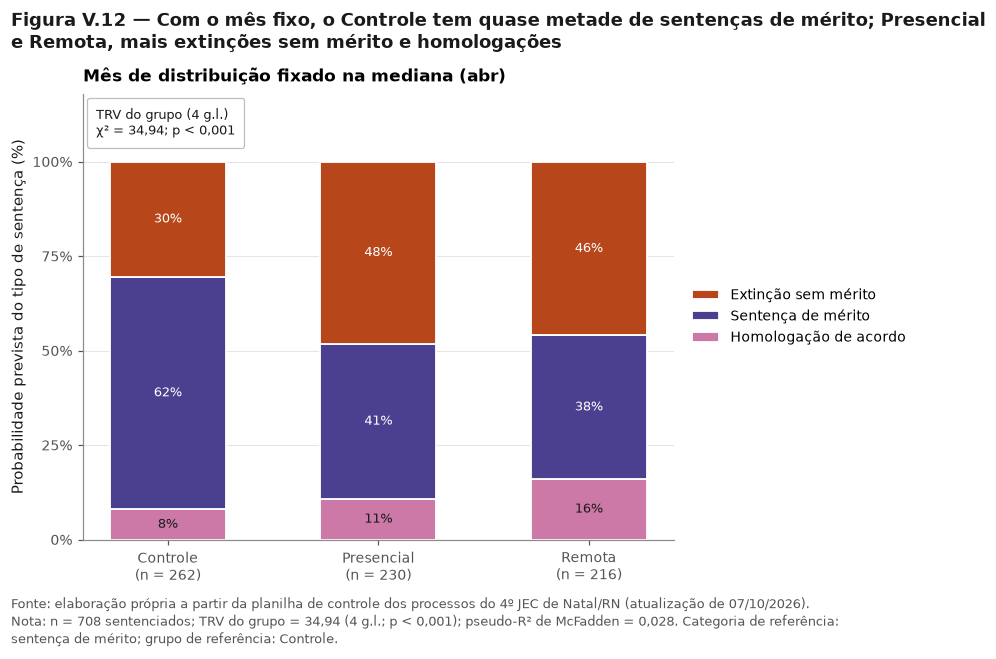

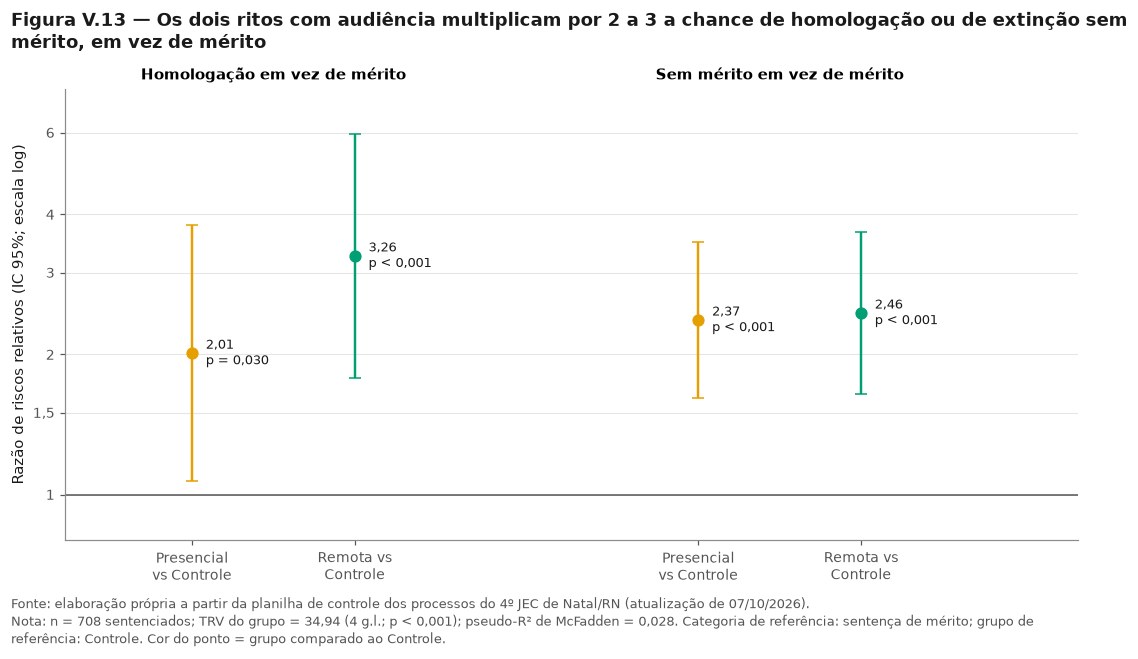

In [44]:
COD_TIPO = {'Mérito': 0, 'Homologação': 1, 'Sem mérito': 2}
ROT_TIPO = {1: 'Homologação vs Mérito', 2: 'Sem mérito vs Mérito'}
sent['y_tipo'] = sent['desfecho'].map(COD_TIPO)

def mul_mnlogit(base):
    r = smf.mnlogit('y_tipo ~ C(grupo) + mes_num', data=base).fit(disp=0, maxiter=200)
    r0 = smf.mnlogit('y_tipo ~ mes_num', data=base).fit(disp=0, maxiter=200)
    trv = 2 * (r.llf - r0.llf)
    return r, trv, stats.chi2.sf(trv, 4)

def mul_tab_rrr(r):
    ic = r.conf_int()
    eqs = list(dict.fromkeys(ic.index.get_level_values(0)))
    lin = []
    for j, col in enumerate(r.params.columns):
        for termo in r.params.index:
            k = j + 1
            lo, hi = ic.loc[(eqs[j], termo)]
            lin.append({'Equação': ROT_TIPO[k], 'Termo': NOMES_COEF.get(termo, termo),
                        'RRR': np.exp(r.params.loc[termo, col]), 'li': np.exp(lo), 'ls': np.exp(hi),
                        'p': r.pvalues.loc[termo, col]})
    return pd.DataFrame(lin)

mnl, trv_mnl, p_mnl = mul_mnlogit(sent)
sent150 = sent[sent['followup_f'] >= 150]
base150 = mul[mul['followup_f'] >= 150]
mnl150, trv150, p150 = mul_mnlogit(sent150)
rrr = mul_tab_rrr(mnl)
rrr150 = mul_tab_rrr(mnl150)
mul_res['mnl'] = (rrr, trv_mnl, p_mnl, mnl.prsquared, rrr150, p150)
nota_mnl = (f'n = {int(mnl.nobs)} sentenciados; TRV do grupo = {fmt_br(trv_mnl, 2)} (4 g.l.; p {mul_peq(p_mnl)}); '
            f'pseudo-R² de McFadden = {fmt_br(mnl.prsquared, 3)}. Categoria de referência: sentença de mérito; grupo de referência: Controle.')
mostra = lambda t: t.rename(columns={'li': 'IC 95% inf.', 'ls': 'IC 95% sup.'})[['Equação', 'Termo', 'RRR', 'IC 95% inf.', 'IC 95% sup.', 'p']]
FMT_RRR = {'RRR': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}
tabela(mostra(rrr), 'mul_mnlogit', 'Logit multinomial do tipo de sentença ~ grupo + mês: razões de riscos relativos (RRR)',
       secao='5.2.7', formatos=FMT_RRR, destaque='p', nota=nota_mnl + ' Destaque: p < 0,05.')
nota_150 = (f'n = {len(sent150)} sentenciados de {len(base150)} distribuídos com seguimento ≥ 150 dias '
            f'({pct_br(len(sent150) / len(base150))} já sentenciados); TRV do grupo = {fmt_br(trv150, 2)} (p {mul_peq(p150)}).')
tabela(mostra(rrr150[rrr150['Termo'].str.contains('vs Controle')]), 'mul_mnlogit_150',
       'Sensibilidade: RRR dos grupos só com processos de seguimento ≥ 150 dias', secao='5.2.7', formatos=FMT_RRR,
       destaque='p', nota=nota_150 + ' Só os termos de grupo; o modelo inclui o mês.')

# (a) probabilidades previstas no mês mediano: barras 100% empilhadas por grupo
grade = pd.DataFrame({'grupo': pd.Categorical(ORDEM_GRUPO, categories=ORDEM_GRUPO), 'mes_num': np.median(sent['mes_num'])})
prev = np.asarray(mnl.predict(grade))
prev_df = pd.DataFrame(prev, index=ORDEM_GRUPO, columns=['Mérito', 'Homologação', 'Sem mérito'])
prev_df = prev_df[[k for k in ORDEM_DESFECHO if k in prev_df.columns]]
fig, ax = plt.subplots(figsize=(8.5, 5))
barras_empilhadas(ax, prev_df, cores=CORES_DESFECHO, fmt=lambda v: pct_br(v, 0), largura=0.55,
                  ylabel='Probabilidade prevista do tipo de sentença (%)', rotulos_serie=ROTULO_DESFECHO,
                  ns=[int((sent['grupo'] == g).sum()) for g in ORDEM_GRUPO])
ax.set_title(f'Mês de distribuição fixado na mediana ({MESES_PT[int(np.median(sent["mes_num"])) - 1]})')
anotar_teste(ax, texto_teste('TRV do grupo (4 g.l.)', f'χ² = {fmt_br(trv_mnl, 2)}', p_mnl), loc='upper left')
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.25))
figura(fig, 'mul_mnlogit_prev', 'Com o mês fixo, o Controle tem quase metade de sentenças de mérito; Presencial e Remota, '
       'mais extinções sem mérito e homologações', secao='5.2.7', nota=nota_mnl)

# (b) RRR dos grupos nas duas equações
t = rrr[rrr['Termo'].str.contains('vs Controle')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5))
cores_t = [CORES_GRUPO['Presencial' if 'Presencial' in r['Termo'] else 'Remota'] for _, r in t.iterrows()]
x_pos = np.array([0, 0.45, 1.4, 1.85])[:len(t)]
mul_forest(ax, t['RRR'], t['li'], t['ls'], x=x_pos, cor=cores_t,
           textos=[f"{fmt_br(r['RRR'], 2)}\np {mul_peq(r['p'])}" for _, r in t.iterrows()])
mul_eixo_razao(ax, np.r_[t['li'], t['ls']])
ax.set_xticks(x_pos, [quebra(r['Termo'], 12) for _, r in t.iterrows()])
for xc, eq in zip([0.225, 1.625], list(dict.fromkeys(t['Equação']))):
    ax.annotate(eq.replace(' vs ', ' em vez de ').lower().capitalize(), (xc, 1), xycoords=('data', 'axes fraction'),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax.set_xlim(-0.35, 2.45)
ax.set(ylabel='Razão de riscos relativos (IC 95%; escala log)')
figura(fig, 'mul_mnlogit_rrr', 'Os dois ritos com audiência multiplicam por 2 a 3 a chance de homologação ou de extinção '
       'sem mérito, em vez de mérito', secao='5.2.7', nota=nota_mnl + ' Cor do ponto = grupo comparado ao Controle.')

**Interpretação.** O tipo de sentença depende fortemente do grupo: TRV = 34,94 (4 g.l.; p < 0,001), controlado o mês. Com mérito como referência:

- **sem mérito vs. mérito**: RRR = **2,37** para a Presencial (IC 1,61 a 3,49) e **2,46** para a Remota (IC 1,65 a 3,66), ambos com p < 0,001. Nos ritos com audiência obrigatória, a chance de o processo terminar sem julgamento de mérito, em vez de com mérito, é cerca de 2,4 vezes a do rito atual;
- **homologação vs. mérito**: RRR = 2,01 para a Presencial (IC 1,07 a 3,79; p = 0,030) e **3,26** para a Remota (IC 1,78 a 5,95; p < 0,001).

Em proporções brutas, o mérito cai de 61,8% dos sentenciados no Controle (162/262) para 41,7% na Presencial (96/230) e 38,4% na Remota (83/216). Essa diferença de cerca de 20 pontos percentuais é absorvida pelas extinções sem mérito (30,2% → 47,4% e 45,4%) e, na Remota, também pelos acordos (8,0% → 16,2%). Na sensibilidade com seguimento ≥ 150 dias (90,1% já sentenciados, logo quase sem viés de seleção), os RRR praticamente não mudam (sem mérito: 1,99 e 2,42; homologação Remota: 3,20) e o TRV continua com p < 0,001. O mês aumenta um pouco a chance de sem mérito (RRR = 1,10 por mês; p = 0,037).

**Leitura jurídica.** É o achado mais robusto desta parte. A audiência obrigatória **muda a natureza da resposta jurisdicional**: menos sentenças de mérito, mais extinções e mais acordos. A hipótese do art. 51, I, da Lei 9.099/1995 (extinção pela ausência do autor à audiência) é compatível com o padrão e é examinada na árvore B (5.3.2). Do ponto de vista de política judiciária, a extinção sem mérito "resolve" o processo na vara, mas não o conflito (o autor pode repropor a ação). Comparar ritos só pelo tempo até a sentença, sem olhar o **tipo** de sentença, esconde esse custo. O pseudo-R² de McFadden (0,028) volta a mostrar que o grupo muda as proporções, mas não prevê o desfecho de um processo individual.

## 5.3 Árvores de decisão

Uma árvore de classificação (CART) particiona os dados, recursivamente, em grupos cada vez mais homogêneos quanto à resposta (ARTES; BARROSO, 2023, cap. 11, p. 377-382). Para variáveis ordinais, como o dia de distribuição, as partições são monotônicas (p. 390). O tamanho da árvore é escolhido por **poda de custo-complexidade**, C_α(A) = erro(A) + α·|folhas| (p. 395-396), com α escolhido por **validação cruzada** (5 partes estratificadas). Com tão poucos preditores, a árvore serve para (i) mostrar se há **interações** que o modelo logístico aditivo não captou e (ii) medir, fora da amostra, o poder preditivo realista. Compara-se sempre com a **regra trivial** (prever a classe mais frequente). Exige-se no mínimo 20 processos por folha, para evitar folhas espúrias.

### 5.3.1 Tipo de sentença com preditores basais

Preditores basais (anteriores ao sorteio ou o próprio sorteio): grupo (dois indicadores), dia de distribuição (0 a 214) e origem externa.

Árvore A: 7 folhas, profundidade 4, α = 0,0039
Acurácia VC = 52,0% (regra trivial "sempre mérito" = 48,2%); acurácia balanceada VC = 38,5% (trivial = 33,3%)


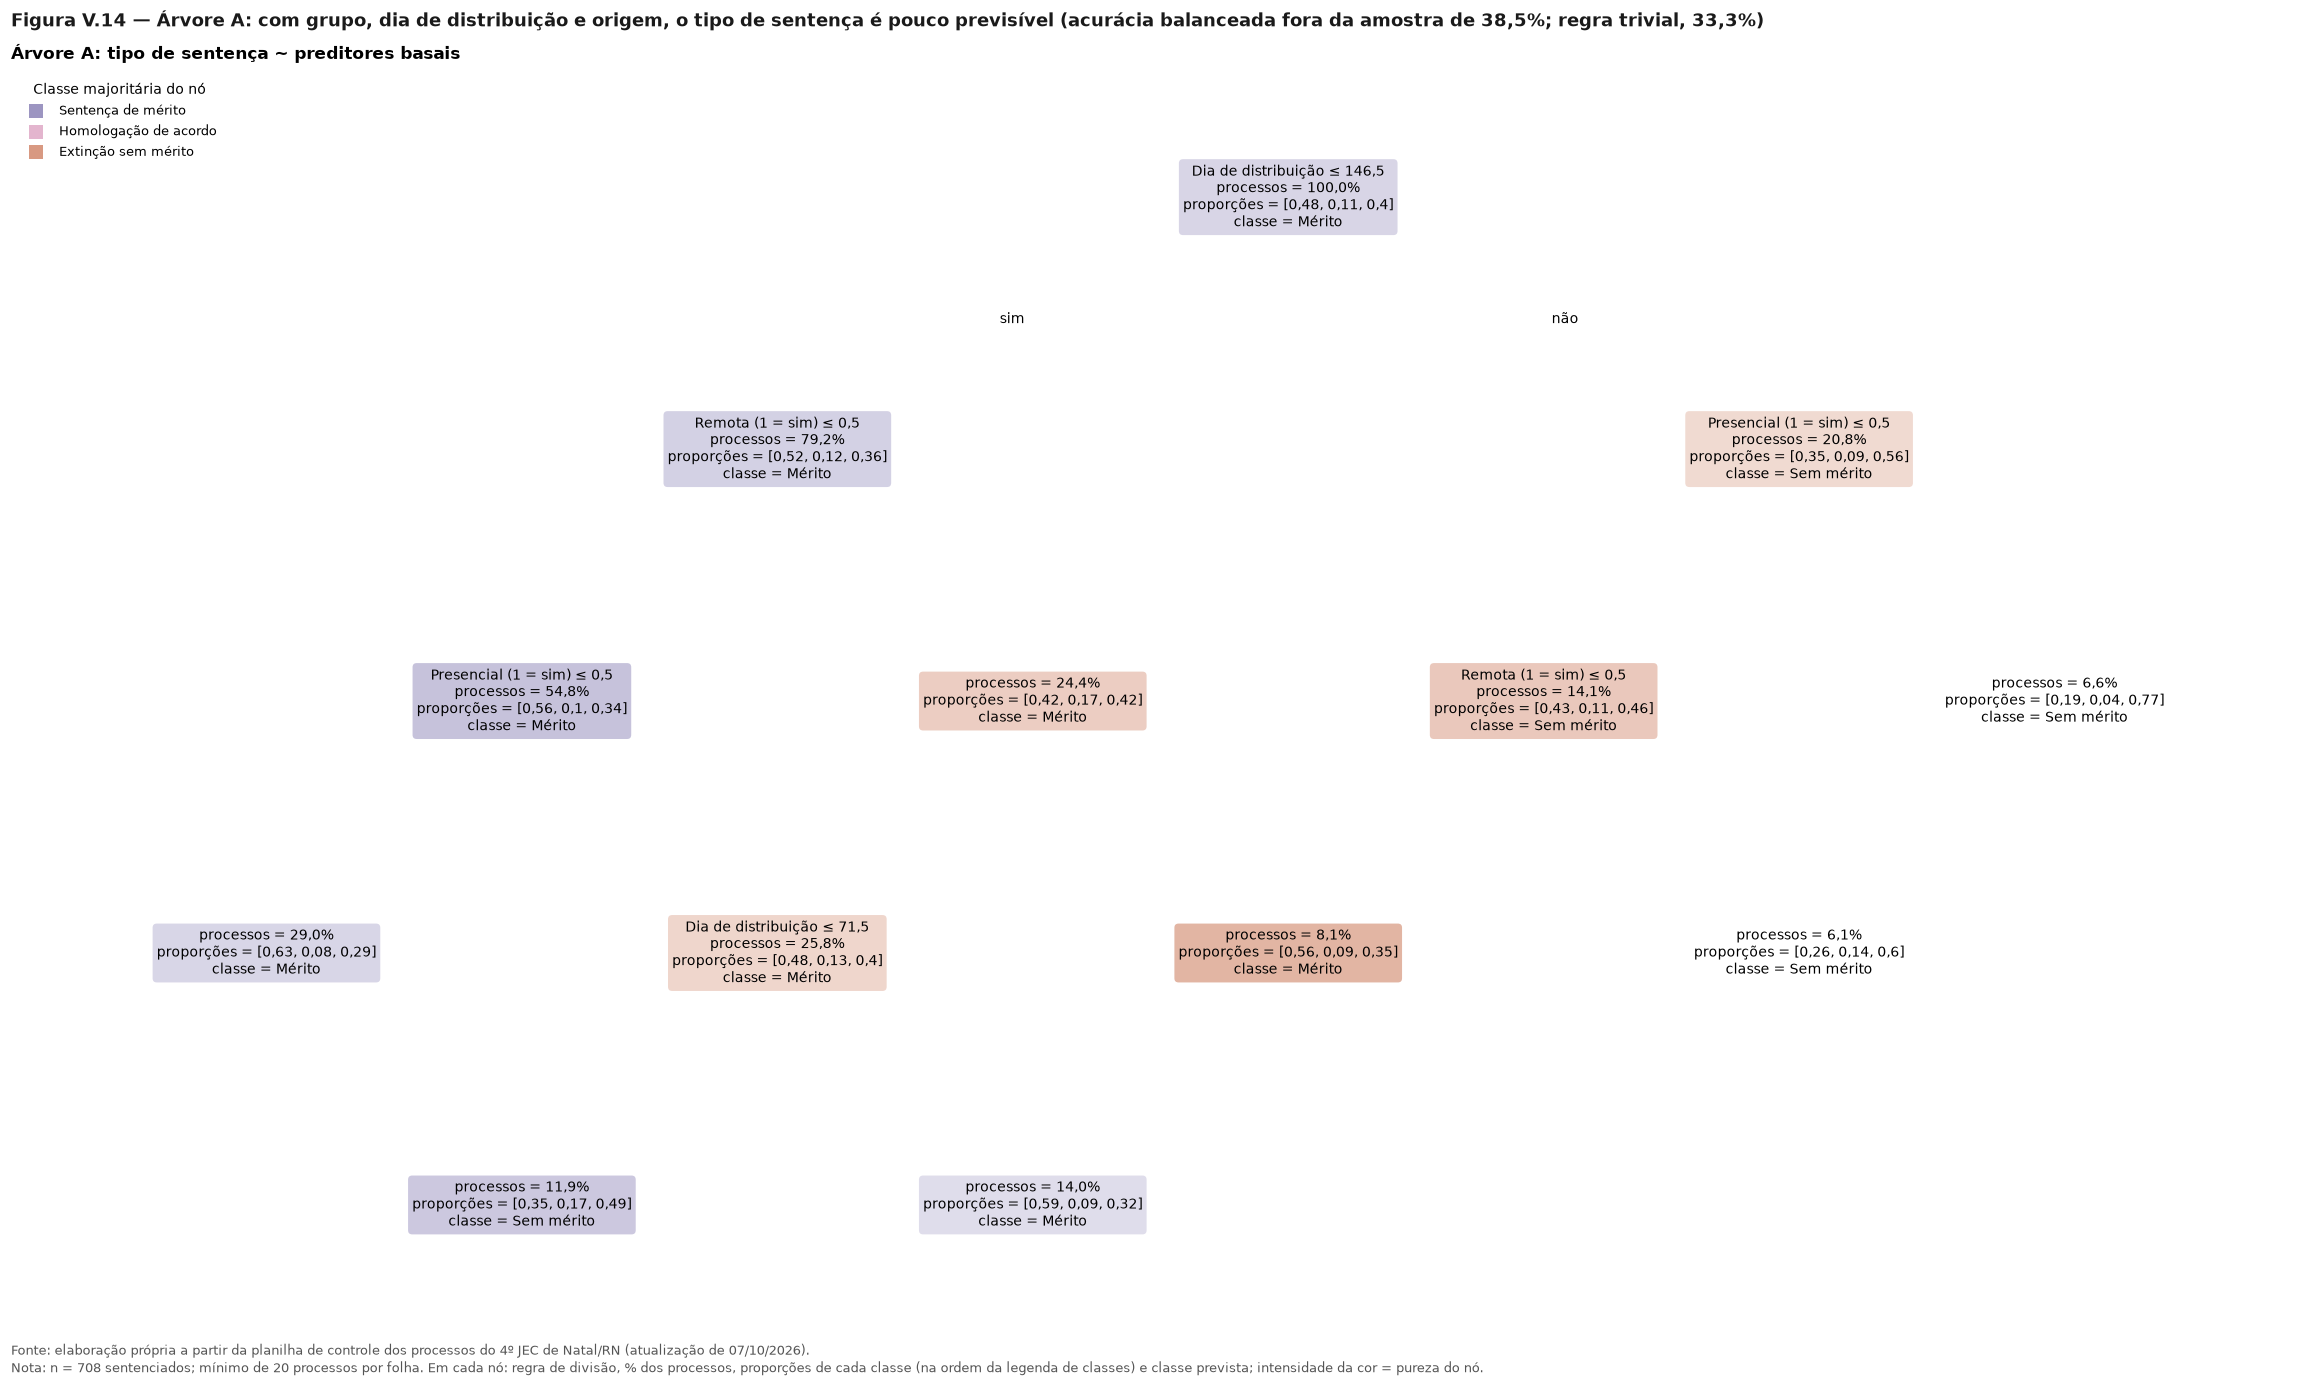

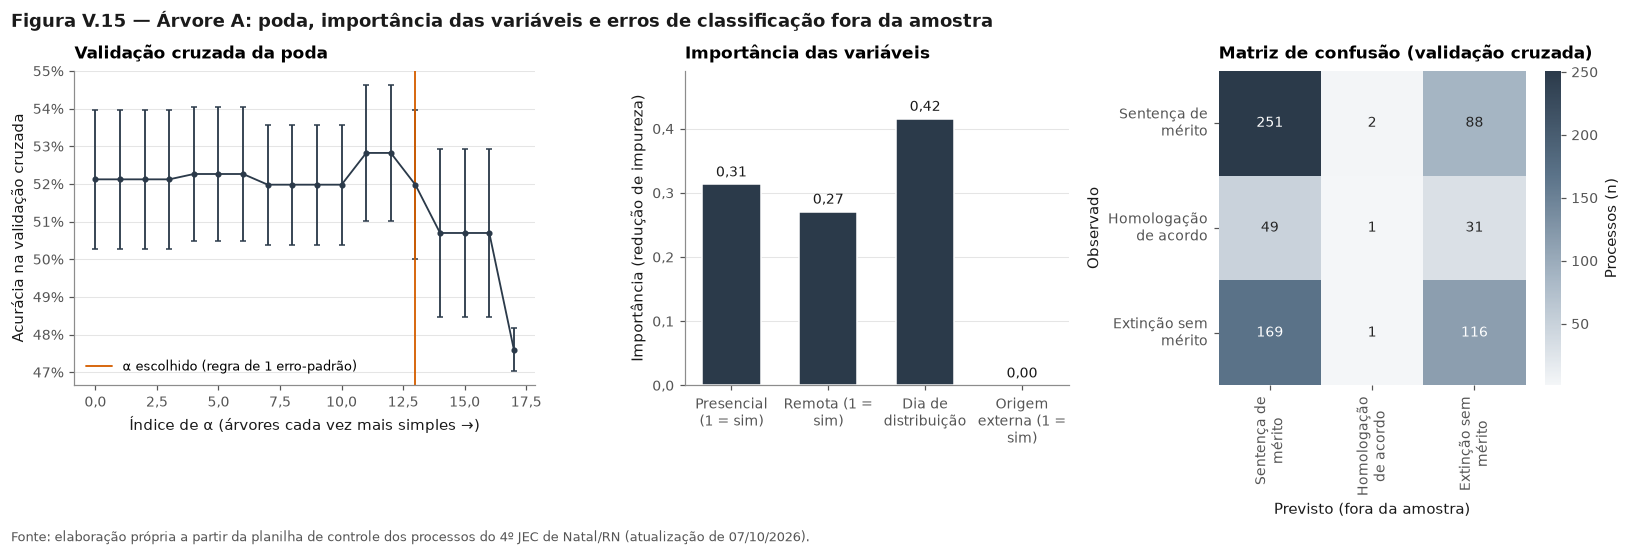

In [45]:
def arvore_cv(X, y, classificacao=True, min_folha=20, k=5, semente=SEMENTE):
    Est = DecisionTreeClassifier if classificacao else DecisionTreeRegressor
    base = Est(min_samples_leaf=min_folha, random_state=semente)
    alphas = base.cost_complexity_pruning_path(X, y).ccp_alphas
    alphas = np.unique(np.clip(alphas, 0, None))
    cv = (StratifiedKFold if classificacao else KFold)(k, shuffle=True, random_state=semente)
    score = 'accuracy' if classificacao else 'neg_mean_squared_error'
    medias, eps = [], []
    for a in alphas:
        s = cross_val_score(Est(min_samples_leaf=min_folha, ccp_alpha=a, random_state=semente), X, y, cv=cv, scoring=score)
        medias.append(s.mean()); eps.append(s.std(ddof=1) / np.sqrt(k))
    medias, eps = np.array(medias), np.array(eps)
    i_best = int(np.argmax(medias))
    # regra de 1 erro-padrão: a árvore mais simples (maior α) dentro de 1 EP da melhor
    i_1se = int(np.max(np.where(medias >= medias[i_best] - eps[i_best])[0]))
    a_sel = alphas[i_1se]
    modelo = Est(min_samples_leaf=min_folha, ccp_alpha=a_sel, random_state=semente).fit(X, y)
    prev_cv = cross_val_predict(Est(min_samples_leaf=min_folha, ccp_alpha=a_sel, random_state=semente), X, y, cv=cv)
    return {'modelo': modelo, 'alphas': alphas, 'medias': medias, 'eps': eps, 'a_sel': a_sel,
            'i_best': i_best, 'i_1se': i_1se, 'prev_cv': prev_cv, 'score': score}

def figura_arvore(r, X, y, nomes_classe, titulo, id_, secao, achado_arvore, achado_diag, metrica='Acurácia na validação cruzada',
                  nota=None):
    # (1) a árvore, sozinha e grande, com nós coloridos pela classe majoritária (cores dos desfechos)
    folhas = r['modelo'].get_n_leaves()
    fig, ax = plt.subplots(figsize=(max(9, 2.6 * folhas + 3), 2.2 * (r['modelo'].get_depth() + 1) + 1))
    if folhas > 1:
        mul_arvore(ax, r['modelo'], list(X.columns), classes=nomes_classe,
                   cores_classe={c: CORES_DESFECHO.get(c, CINZA) for c in nomes_classe}, fontsize=9)
        for c in nomes_classe:
            ax.scatter([], [], marker='s', s=90, color=CORES_DESFECHO.get(c, CINZA), alpha=0.55, label=ROTULO_DESFECHO.get(c, c))
        ax.legend(loc='upper left', title='Classe majoritária do nó', fontsize=8.5, frameon=False)
    else:
        ax.text(0.5, 0.5, 'A poda escolheu a árvore de um só nó\n(nenhuma partição melhora a previsão fora da amostra)',
                ha='center', va='center', fontsize=12); ax.axis('off')
    ax.set_title(titulo)
    figura(fig, id_, achado_arvore, secao=secao,
           nota=(nota + ' ' if nota else '') + 'Em cada nó: regra de divisão, % dos processos, proporções de cada classe '
                '(na ordem da legenda de classes) e classe prevista; intensidade da cor = pureza do nó.')
    # (2) diagnóstico: poda, importância e matriz de confusão
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.2, 1, 1]})
    ax = eixos[0]
    ax.errorbar(range(len(r['alphas'])), r['medias'], yerr=r['eps'], fmt='o-', ms=3, lw=1.2, color=COR_MODELO, capsize=2)
    ax.axvline(r['i_1se'], color=COR_VIES, lw=1.2, label='α escolhido (regra de 1 erro-padrão)')
    ax.set(xlabel='Índice de α (árvores cada vez mais simples →)', ylabel=metrica, title='Validação cruzada da poda')
    if r['score'] == 'accuracy':
        eixo_pct(ax)
    ax.legend(loc='lower left', fontsize=8.5)
    ax = eixos[1]
    imp = pd.Series(r['modelo'].feature_importances_, index=X.columns)
    barras_verticais(ax, [NOMES_VAR.get(c, c) for c in imp.index], imp.values, cores=COR_MODELO, quebrar=12,
                     fmt=lambda v: fmt_br(v, 2), ylabel='Importância (redução de impureza)',
                     ymax=max(imp.max() * 1.18, 0.05))
    ax.set_title('Importância das variáveis')
    ax = eixos[2]
    if nomes_classe is not None:
        cm = confusion_matrix(y, r['prev_cv'], labels=list(range(len(nomes_classe))))
        rot_c = [quebra(ROTULO_DESFECHO.get(c, c), 12) for c in nomes_classe]
        sns.heatmap(cm, annot=True, fmt='d', cmap=SEQ, cbar=True, xticklabels=rot_c, yticklabels=rot_c, ax=ax,
                    cbar_kws={'label': 'Processos (n)'}, annot_kws={'fontsize': 9})
        ax.set(xlabel='Previsto (fora da amostra)', ylabel='Observado', title='Matriz de confusão (validação cruzada)')
        ax.tick_params(axis='y', rotation=0)
    figura(fig, id_ + '_diag', achado_diag, secao=secao)
    return imp

X_base = pd.DataFrame({'presencial': sent['presencial'], 'remota': sent['remota'],
                       'dia_estudo': sent['dia_estudo_f'], 'origem_ext': sent['origem_ext']})
y_tipo = sent['y_tipo'].values
nomes_tipo = ['Mérito', 'Homologação', 'Sem mérito']
arvA = arvore_cv(X_base, y_tipo)
base_trivial = np.bincount(y_tipo).max() / len(y_tipo)
acc = accuracy_score(y_tipo, arvA['prev_cv']); bacc = balanced_accuracy_score(y_tipo, arvA['prev_cv'])
mul_res['arvA'] = (arvA['modelo'].get_n_leaves(), acc, bacc, base_trivial)
print(f"Árvore A: {arvA['modelo'].get_n_leaves()} folhas, profundidade {arvA['modelo'].get_depth()}, α = {fmt_br(arvA['a_sel'], 4)}")
print(f'Acurácia VC = {pct_br(acc)} (regra trivial "sempre mérito" = {pct_br(base_trivial)}); '
      f'acurácia balanceada VC = {pct_br(bacc)} (trivial = 33,3%)')
impA = figura_arvore(arvA, X_base, y_tipo, nomes_tipo, 'Árvore A: tipo de sentença ~ preditores basais', 'mul_arvore_A', '5.3.1',
                     f'Árvore A: com grupo, dia de distribuição e origem, o tipo de sentença é pouco previsível '
                     f'(acurácia balanceada fora da amostra de {pct_br(bacc)}; regra trivial, 33,3%)',
                     'Árvore A: poda, importância das variáveis e erros de classificação fora da amostra',
                     nota=f'n = {len(y_tipo)} sentenciados; mínimo de 20 processos por folha.')

**Interpretação.** A poda pela regra de 1 erro-padrão escolheu uma árvore de 7 folhas e profundidade 4, mas o gráfico da validação cruzada mostra que a acurácia é praticamente **plana** (cerca de 52%) em todas as complexidades. Fora da amostra, a árvore acerta **52,0%**, contra 48,2% da regra trivial "sempre mérito", e a acurácia balanceada é 38,5%, contra 33,3% do acaso. A homologação quase nunca é prevista (1 de 81 acertos), porque não domina nenhuma folha. O ganho preditivo é mínimo.

O que a árvore sugere, como **hipótese exploratória** de interação: a primeira partição é o dia de distribuição (≤ 146,5, isto é, até ~27/05); depois vem o grupo. A folha mais pura é a dos processos **Presencial distribuídos a partir do fim de maio** (6,6% da amostra), com 76,6% de sentenças sem mérito. A folha do Controle distribuído no início (até ~13/03) tem 63,4% de mérito. A importância relativa (dia 0,42; Presencial 0,31; Remota 0,27; origem externa 0) confirma que só grupo e calendário carregam informação. Essa interação grupo × período não foi testada formalmente e pode refletir mudanças na pauta da audiência presencial ao longo do experimento; com 60 processos na folha, convém não lhe dar peso confirmatório.

### 5.3.2 Tipo de sentença nos grupos tratados, com variáveis do processo (exploratória)

Nos grupos Presencial e Remota, acrescentam-se duas variáveis **pós-sorteio**: se a audiência foi realizada e se foi híbrida. A hipótese jurídica da Parte III é que a extinção sem mérito nos tratados decorre da **ausência do autor à audiência obrigatória** (art. 51, I, Lei 9.099/1995). Atenção à causalidade reversa: "audiência não realizada" pode ser causa da extinção (ausência do autor) ou consequência dela (o processo foi extinto, por desistência ou indeferimento, antes da data da audiência). A árvore mostra a **associação**, não separa esses caminhos; para isso seria preciso registrar a data e o motivo da não realização.

Árvore B (tratados, n = 446): 2 folhas; acurácia VC = 73,3% (trivial = 46,4%); acurácia balanceada VC = 57,1%


Audiência de conciliação,Homologação de acordo (%),Sentença de mérito (%),Extinção sem mérito (%)
AC não realizada,"14,8","2,2","83,1"
AC realizada,"12,5","66,5","20,9"


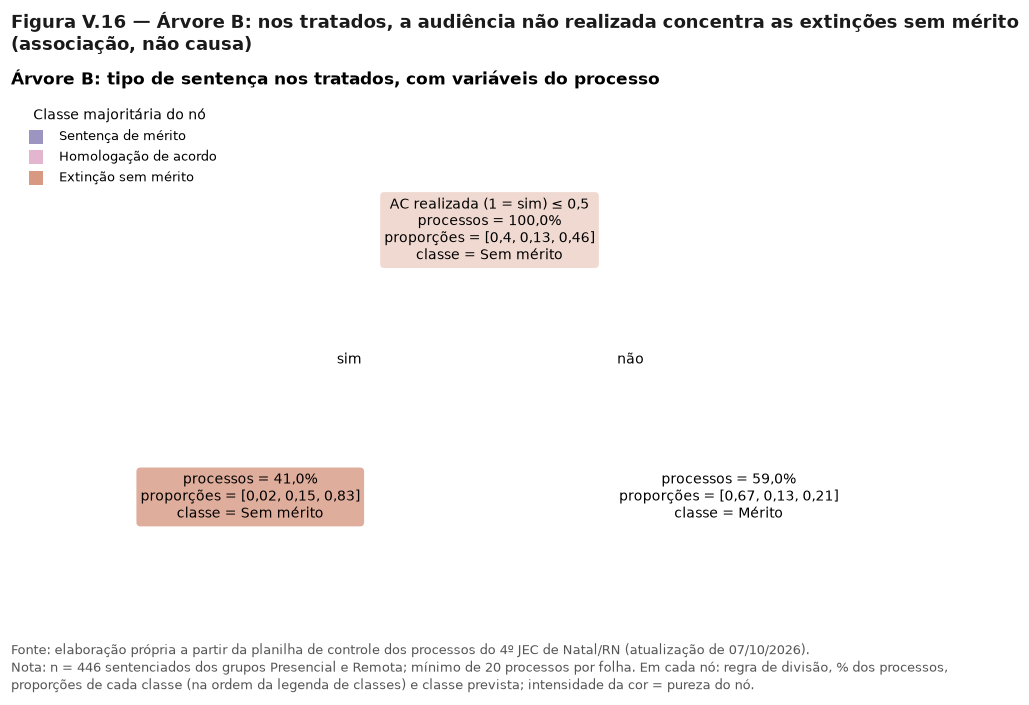

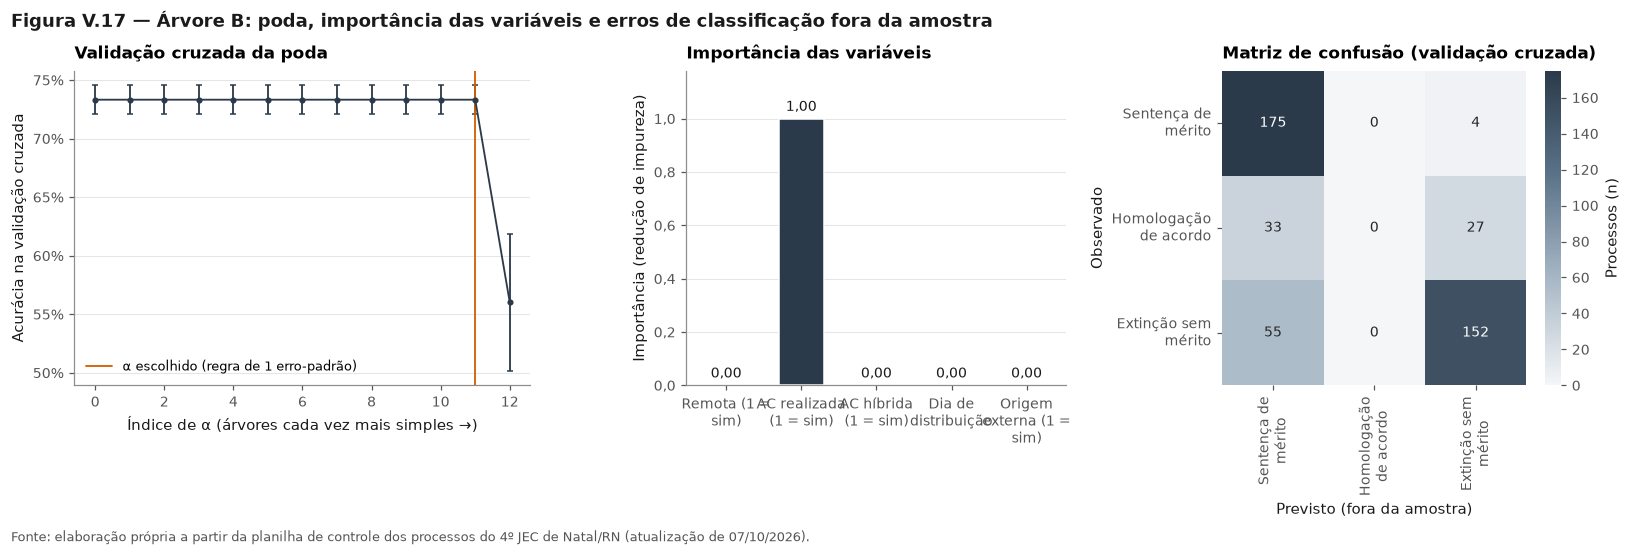

In [46]:
trat = sent[sent['grupo'] != 'Controle'].copy()
X_proc = pd.DataFrame({'remota': trat['remota'], 'ac_realizada': trat['ac_realizada'].astype(bool).astype(int),
                       'hibrida': trat['hibrida_b'], 'dia_estudo': trat['dia_estudo_f'], 'origem_ext': trat['origem_ext']})
y_trat = trat['y_tipo'].values
arvB = arvore_cv(X_proc, y_trat)
accB = accuracy_score(y_trat, arvB['prev_cv']); baccB = balanced_accuracy_score(y_trat, arvB['prev_cv'])
trivB = np.bincount(y_trat).max() / len(y_trat)
mul_res['arvB'] = (arvB['modelo'].get_n_leaves(), accB, baccB, trivB)
print(f"Árvore B (tratados, n = {len(trat)}): {arvB['modelo'].get_n_leaves()} folhas; acurácia VC = {pct_br(accB)} "
      f"(trivial = {pct_br(trivB)}); acurácia balanceada VC = {pct_br(baccB)}")
tab_acr = pd.crosstab(X_proc['ac_realizada'].map({1: 'AC realizada', 0: 'AC não realizada'}), trat['desfecho'],
                      normalize='index').reindex(columns=['Homologação', 'Mérito', 'Sem mérito'])
tab_acr = (100 * tab_acr).rename(columns=lambda c: ROTULO_DESFECHO[c] + ' (%)').rename_axis('Audiência de conciliação')
tabela(tab_acr, 'mul_tratados_acr', 'Tipo de sentença nos tratados conforme a audiência foi ou não realizada (% da linha)',
       secao='5.3.2', casas=1, nota=f'n = {len(trat)} sentenciados dos grupos Presencial e Remota.')
impB = figura_arvore(arvB, X_proc, y_trat, nomes_tipo, 'Árvore B: tipo de sentença nos tratados, com variáveis do processo',
                     'mul_arvore_B', '5.3.2',
                     'Árvore B: nos tratados, a audiência não realizada concentra as extinções sem mérito (associação, não causa)',
                     'Árvore B: poda, importância das variáveis e erros de classificação fora da amostra',
                     nota=f'n = {len(y_trat)} sentenciados dos grupos Presencial e Remota; mínimo de 20 processos por folha.')

**Interpretação.** Nos tratados, a árvore escolhida tem **uma única partição**: a audiência foi ou não realizada. Quando não foi, **83,1%** das sentenças são sem mérito (só 2,2% de mérito); quando foi, 66,5% são de mérito, 20,9% sem mérito e 12,5% homologações. A acurácia fora da amostra sobe para **73,3%** (trivial 46,4%; balanceada 57,1%), muito acima da árvore com preditores basais. Modalidade, híbrida, data e origem não acrescentam nada depois dessa partição.

**Leitura jurídica e cautela causal.** O padrão é o que se espera da extinção por **ausência do autor à audiência** (art. 51, I, Lei 9.099/1995): a audiência obrigatória cria uma oportunidade de extinção que não existe no rito atual, e isso explica boa parte do excesso de sentenças sem mérito nos tratados (5.2.7). Mas "audiência não realizada" é variável **pós-sorteio** e pode ser também **consequência** da extinção (desistência ou indeferimento antes da data marcada). A árvore não distingue os dois caminhos. Para separá-los, a planilha precisaria registrar a data designada da audiência, o motivo da não realização (ausência do autor, do réu, redesignação) e o fundamento legal da sentença sem mérito. Os 14,8% de homologações entre as audiências não realizadas são acordos apresentados por petição antes da sessão.

### 5.3.3 Acordo entre os encerrados (preditores basais)

A mesma árvore, agora para o acordo (definição A). Como os acordos são só 11% dos encerrados, a acurácia é inútil (a regra trivial "nunca há acordo" acerta 89%); a poda é feita pela acurácia, mas o desempenho é medido pela **AUC fora da amostra** das probabilidades das folhas, comparável à do logit (5.2.4).

Árvore C (acordo): poda por acurácia escolheu 1 folha(s); AUC VC de uma árvore de profundidade 3 = 0,535 (logit (A), VC: 0,546)


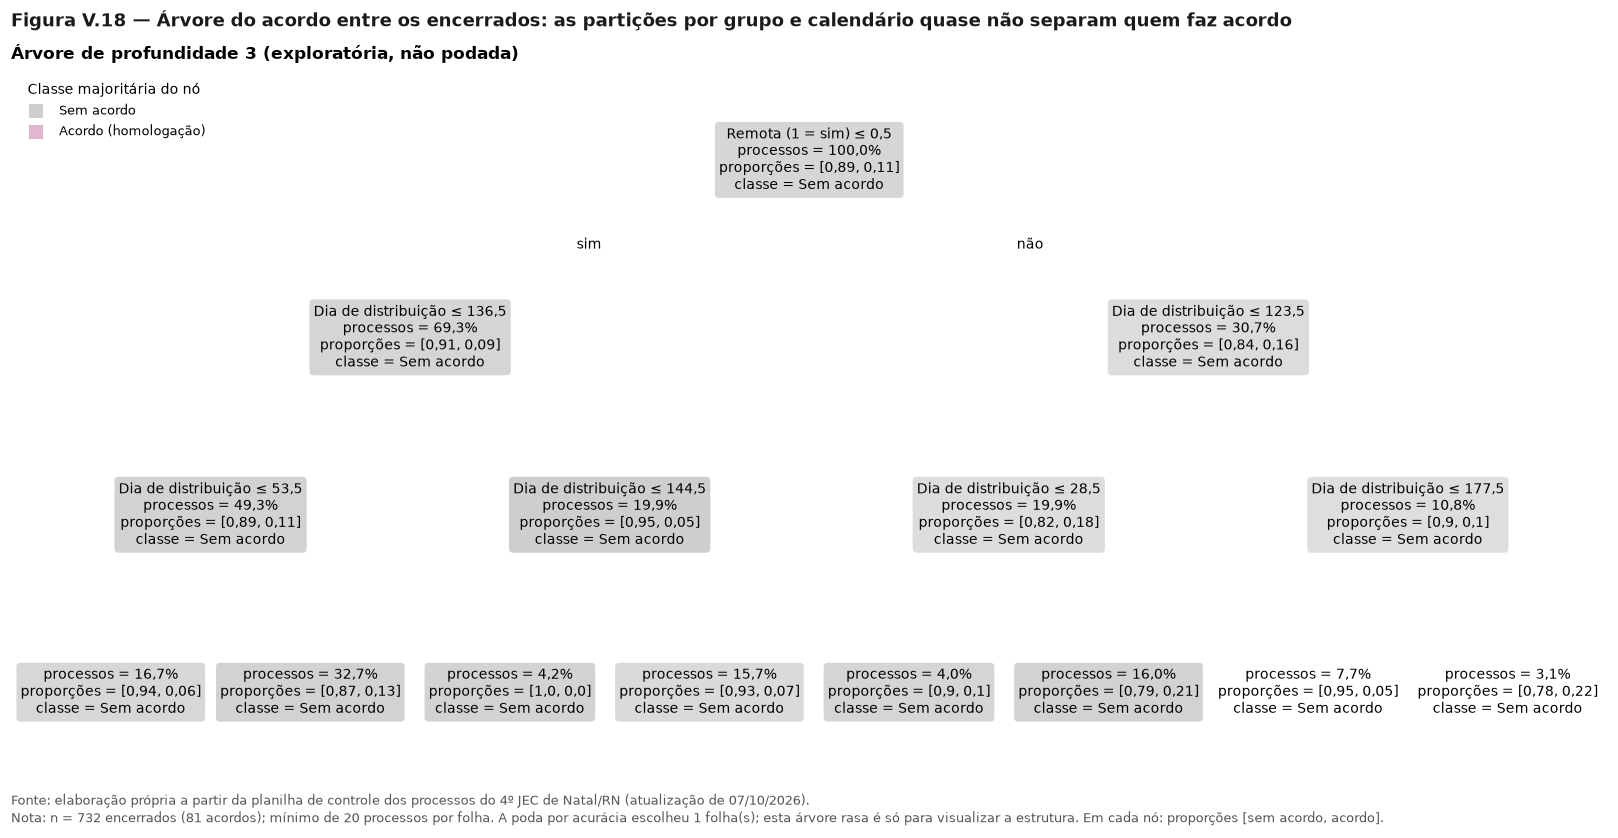

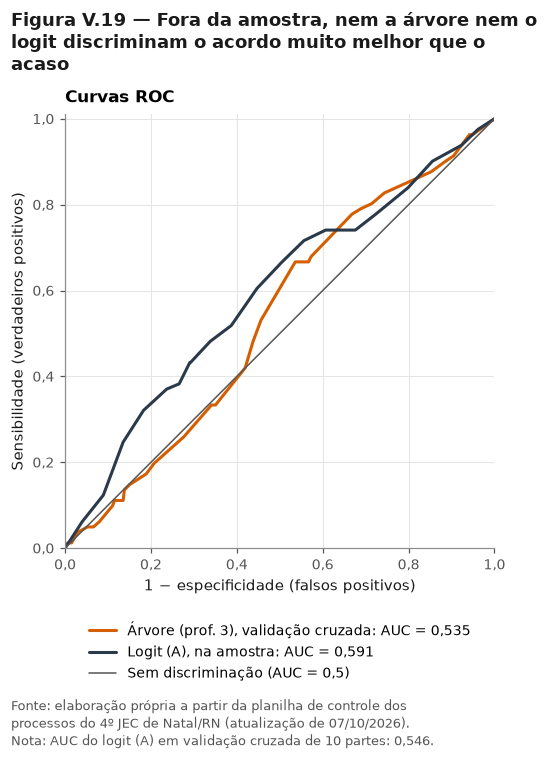

In [47]:
X_enc = pd.DataFrame({'presencial': enc['presencial'], 'remota': enc['remota'],
                      'dia_estudo': enc['dia_estudo_f'], 'origem_ext': enc['origem_ext']})
y_enc = enc['homolog'].values
arvC = arvore_cv(X_enc, y_enc)
# a árvore podada por acurácia tende a um nó; para a AUC usa-se a probabilidade de folhas de uma árvore rasa (profundidade 3)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEMENTE)
prob_cv = cross_val_predict(DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEMENTE),
                            X_enc, y_enc, cv=cv5, method='predict_proba')[:, 1]
auc_arv = roc_auc_score(y_enc, prob_cv)
mul_res['arvC'] = (arvC['modelo'].get_n_leaves(), auc_arv)
print(f"Árvore C (acordo): poda por acurácia escolheu {arvC['modelo'].get_n_leaves()} folha(s); "
      f"AUC VC de uma árvore de profundidade 3 = {fmt_br(auc_arv, 3)} (logit (A), VC: {fmt_br(auccvA, 3)})")
arvC3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEMENTE).fit(X_enc, y_enc)
fig, ax = plt.subplots(figsize=(15, 7))
cls_acordo = ['Sem acordo', 'Acordo']
mul_arvore(ax, arvC3, list(X_enc.columns), classes=cls_acordo,
           cores_classe={'Sem acordo': CINZA, 'Acordo': CORES_DESFECHO['Homologação']}, fontsize=9)
for c, cor in [('Sem acordo', CINZA), ('Acordo (homologação)', CORES_DESFECHO['Homologação'])]:
    ax.scatter([], [], marker='s', s=90, color=cor, alpha=0.55, label=c)
ax.legend(loc='upper left', title='Classe majoritária do nó', fontsize=8.5)
ax.set_title('Árvore de profundidade 3 (exploratória, não podada)')
figura(fig, 'mul_arvore_C', 'Árvore do acordo entre os encerrados: as partições por grupo e calendário quase não separam '
       'quem faz acordo', secao='5.3.3',
       nota=f'n = {len(y_enc)} encerrados ({int(y_enc.sum())} acordos); mínimo de 20 processos por folha. A poda por acurácia '
            f'escolheu {arvC["modelo"].get_n_leaves()} folha(s); esta árvore rasa é só para visualizar a estrutura. '
            'Em cada nó: proporções [sem acordo, acordo].')

fig, ax = plt.subplots(figsize=(6.2, 5.8))
fpr, tpr, _ = roc_curve(y_enc, prob_cv)
ax.plot(fpr, tpr, color=COR_VIES, lw=2, label=f'Árvore (prof. 3), validação cruzada: AUC = {fmt_br(auc_arv, 3)}')
fpr, tpr, _ = roc_curve(yA, pA)
ax.plot(fpr, tpr, color=COR_MODELO, lw=2, label=f'Logit (A), na amostra: AUC = {fmt_br(aucA, 3)}')
ax.plot([0, 1], [0, 1], color=TINTA_2, lw=1, label='Sem discriminação (AUC = 0,5)')
ax.set(xlabel='1 − especificidade (falsos positivos)', ylabel='Sensibilidade (verdadeiros positivos)',
       title='Curvas ROC', xlim=(0, 1), ylim=(0, 1.01))
ax.set_aspect('equal')
ax.grid(axis='both', visible=True)
legenda_abaixo(ax, ncol=1, dy=-0.14)
figura(fig, 'mul_arvore_C_roc', 'Fora da amostra, nem a árvore nem o logit discriminam o acordo muito melhor que o acaso',
       secao='5.3.3', nota=f'AUC do logit (A) em validação cruzada de 10 partes: {fmt_br(auccvA, 3)}.')

**Interpretação.** Para o acordo, a poda por validação cruzada reduz a árvore a **um único nó**: nenhuma partição por grupo, data ou origem melhora a classificação fora da amostra, o que é natural com 11% de acordos (a regra "nunca há acordo" já acerta 89%). Mesmo uma árvore rasa, avaliada pela ordenação das probabilidades, tem AUC fora da amostra de **0,535**, equivalente à do logit (0,546) e igualmente pobre. A árvore exibida, de profundidade 3, é só ilustrativa. A conclusão coincide com 5.2.4: o efeito do grupo sobre o acordo é real na média, mas não serve para prever casos.

### 5.3.4 Árvore de sobrevivência (aproximação pelos resíduos martingal)

Árvores de sobrevivência propriamente ditas (LeBlanc e Crowley, 1993) exigem o pacote `scikit-survival`, que não está instalado no ambiente do projeto. A aproximação clássica de Therneau, Grambsch e Fleming (1990) dispensa o pacote: calcula-se o **resíduo martingal de um modelo de Cox nulo**, Mᵢ = δᵢ − Ĥ₀(tᵢ), em que Ĥ₀ é o risco acumulado de Nelson-Aalen. Mᵢ > 0 indica processo sentenciado "antes do esperado" e Mᵢ < 0, processo que demora mais que o esperado (ou censurado tardio). Uma **árvore de regressão** sobre Mᵢ, com poda por validação cruzada (erro quadrático médio), encontra os subgrupos com tempos mais distintos, e as curvas de Kaplan-Meier das folhas mostram o resultado na escala natural. Os 938 processos entram (os censurados contribuem com δ = 0). O log-rank entre folhas é apresentado só como descrição: as partições foram escolhidas para maximizar a diferença, de modo que o valor-p é otimista.

Árvore podada (regra 1 EP): 1 folha(s); R² VC dos resíduos martingal ≈ -0,010
Melhor α sem a regra 1 EP: R² VC ≈ -0,010
Exibição: árvore exploratória de profundidade 2 (não sobrevive à validação cruzada).


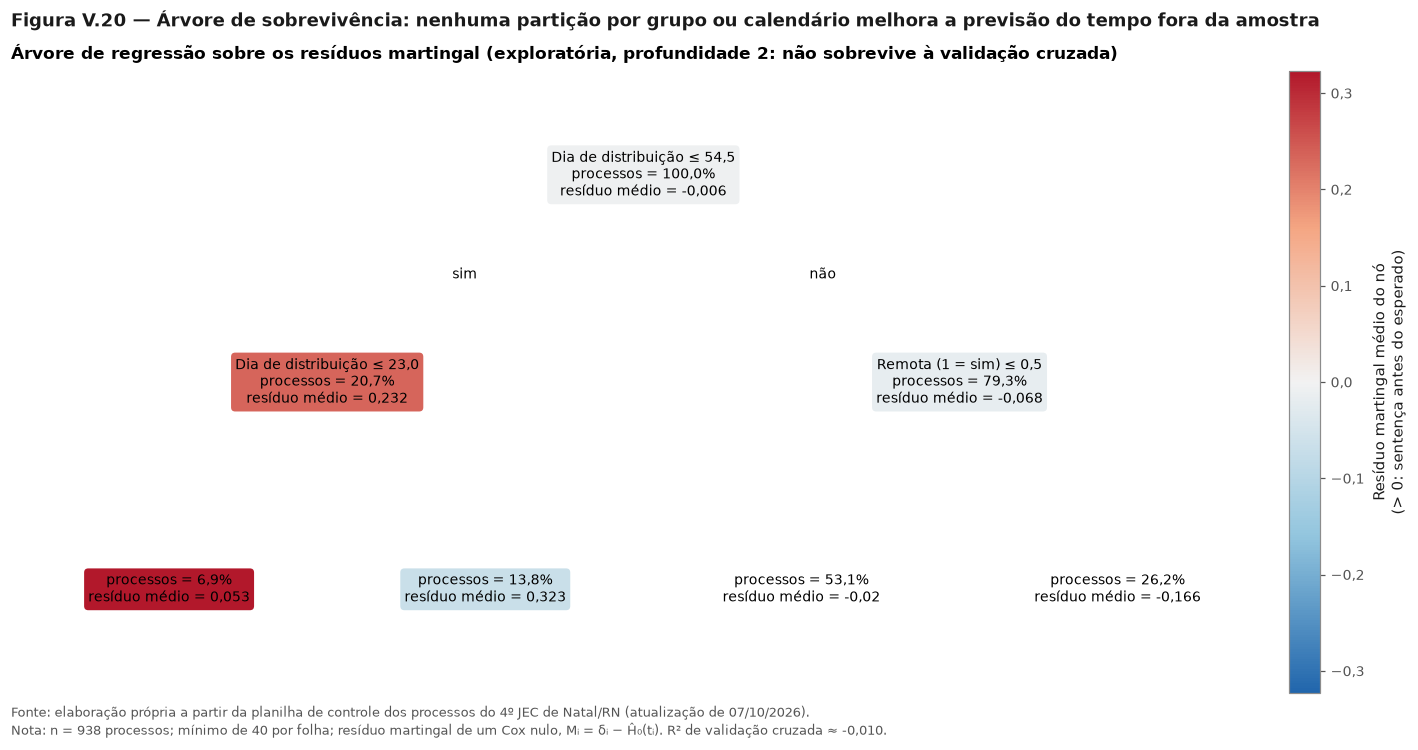

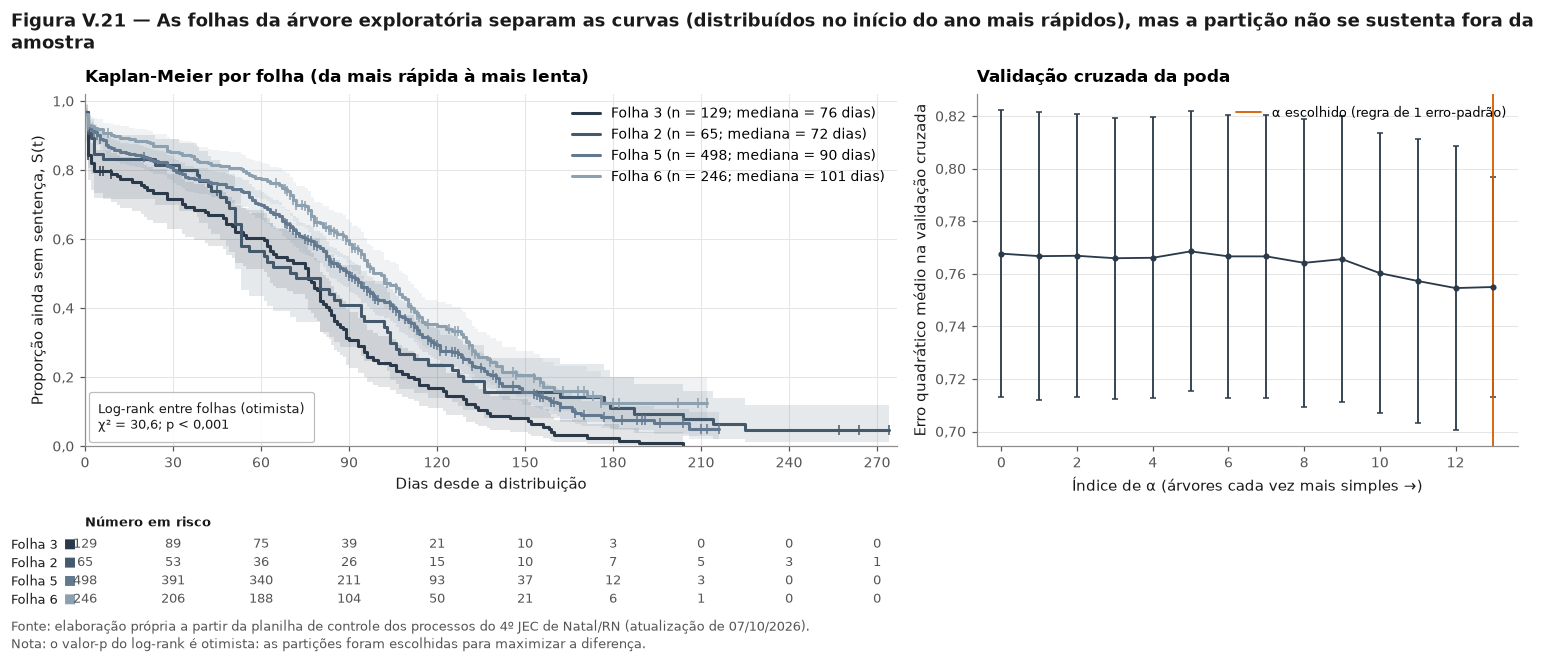

In [48]:
naf = NelsonAalenFitter().fit(mul['T'], mul['E'])
H0 = naf.cumulative_hazard_at_times(mul['T']).values
mul['martingal'] = mul['E'] - H0
X_sob = pd.DataFrame({'presencial': mul['presencial'], 'remota': mul['remota'],
                      'dia_estudo': mul['dia_estudo_f'], 'origem_ext': mul['origem_ext']})
arvS = arvore_cv(X_sob, mul['martingal'].values, classificacao=False, min_folha=40)
mS = arvS['modelo']
r2_cv = 1 - (-arvS['medias'][arvS['i_1se']]) / mul['martingal'].var(ddof=0)
r2_best = 1 - (-arvS['medias'][arvS['i_best']]) / mul['martingal'].var(ddof=0)
print(f"Árvore podada (regra 1 EP): {mS.get_n_leaves()} folha(s); R² VC dos resíduos martingal ≈ {fmt_br(r2_cv, 3)}")
print(f"Melhor α sem a regra 1 EP: R² VC ≈ {fmt_br(r2_best, 3)}")
mS_podada_folhas = mS.get_n_leaves()
if mS.get_n_leaves() == 1:
    # a poda eliminou todas as partições; para visualizar a estrutura, exibe-se uma árvore rasa NÃO validada
    mS = DecisionTreeRegressor(max_depth=2, min_samples_leaf=40, random_state=SEMENTE).fit(X_sob, mul['martingal'])
    print('Exibição: árvore exploratória de profundidade 2 (não sobrevive à validação cruzada).')
mul['folha'] = mS.apply(X_sob)
folhas = sorted(mul['folha'].unique(), key=lambda f: -mul.loc[mul['folha'] == f, 'martingal'].mean())
mul_res['arvS'] = (mS_podada_folhas, r2_cv)
rot_exploratoria = ' (exploratória, profundidade 2: não sobrevive à validação cruzada)' if mS_podada_folhas == 1 else ''
fig, ax = plt.subplots(figsize=(13, 6.2))
if mS.get_n_leaves() > 1:
    mul_arvore(ax, mS, list(X_sob.columns), classes=None, fontsize=9, precisao=3)
    sm_ = mpl.cm.ScalarMappable(cmap=DIV, norm=mpl.colors.Normalize(-np.abs(mS.tree_.value[:, 0, 0]).max(),
                                                                     np.abs(mS.tree_.value[:, 0, 0]).max()))
    cb = fig.colorbar(sm_, ax=ax, fraction=0.025, pad=0.01)
    cb.set_label('Resíduo martingal médio do nó\n(> 0: sentença antes do esperado)')
ax.set_title('Árvore de regressão sobre os resíduos martingal' + rot_exploratoria)
figura(fig, 'mul_arvore_sobrev', 'Árvore de sobrevivência: nenhuma partição por grupo ou calendário melhora a previsão '
       'do tempo fora da amostra', secao='5.3.4',
       nota=f'n = {len(mul)} processos; mínimo de 40 por folha; resíduo martingal de um Cox nulo, Mᵢ = δᵢ − Ĥ₀(tᵢ). '
            f'R² de validação cruzada ≈ {fmt_br(r2_cv, 3)}.')

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = eixos[0]
if len(folhas) > 1:
    cores_folha = {f'Folha {f}': SEQ(v) for f, v in zip(folhas, np.linspace(1.0, 0.45, len(folhas)))}
    mul_km = mul.assign(folha_rot=mul['folha'].map(lambda f: f'Folha {f}'))
    plot_km(ax, mul_km, tempo='T', evento='E', grupo='folha_rot', ordem=list(cores_folha), cores=cores_folha, passo=30,
            tmax=float(mul['T'].max()))
    lr = multivariate_logrank_test(mul['T'], mul['folha'], mul['E'])
    anotar_teste(ax, texto_teste('Log-rank entre folhas (otimista)', f'χ² = {fmt_br(lr.test_statistic, 1)}', lr.p_value),
                 loc='lower left')
    ax.set_title('Kaplan-Meier por folha (da mais rápida à mais lenta)')
    mul_res['arvS_lr'] = lr.p_value
ax = eixos[1]
ax.errorbar(range(len(arvS['alphas'])), -arvS['medias'], yerr=arvS['eps'], fmt='o-', ms=3, lw=1.2, color=COR_MODELO, capsize=2)
ax.axvline(arvS['i_1se'], color=COR_VIES, lw=1.2, label='α escolhido (regra de 1 erro-padrão)')
ax.set(xlabel='Índice de α (árvores cada vez mais simples →)', ylabel='Erro quadrático médio na validação cruzada',
       title='Validação cruzada da poda')
ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'mul_arvore_sobrev_km', 'As folhas da árvore exploratória separam as curvas (distribuídos no início do ano mais rápidos), '
       'mas a partição não se sustenta fora da amostra',
       secao='5.3.4', nota='o valor-p do log-rank é otimista: as partições foram escolhidas para maximizar a diferença.')

**Interpretação.** A árvore de regressão sobre os resíduos martingal **não sobrevive à validação cruzada**. O erro quadrático médio fora da amostra é praticamente o mesmo em todas as complexidades, a regra de 1 EP escolhe a raiz (sem partição) e, mesmo no melhor α, o R² fora da amostra é ≈ −0,010. Grupo, data de distribuição e origem não definem subgrupos com tempos de tramitação previsivelmente diferentes.

A árvore de profundidade 2 do gráfico é **exploratória** (não validada). A primeira partição é a data (até ~24/02: resíduo médio +0,23, ou seja, sentenças mais rápidas que o esperado, o que é coerente com o acúmulo de acervo visto em 5.1.3). Entre os distribuídos depois, separa a Remota (n = 246; resíduo −0,17, mais lenta) dos demais (n = 498; −0,02), na mesma direção da razão de tempos do AFT (1,23, não significativa). O log-rank entre folhas (30,6; p < 0,001) é otimista, porque as partições foram escolhidas para maximizar a separação, e não deve ser lido como teste. A abordagem dos resíduos martingal (Therneau, Grambsch e Fleming, 1990) substitui razoavelmente uma árvore de sobrevivência (`scikit-survival`, não instalado). O resultado negativo é informativo: não há heterogeneidade de tempo explorável com as variáveis disponíveis.

## 5.4 Análise de correspondência

A análise de correspondência (AC) decompõe a estatística χ² de uma tabela de contingência em dimensões ortogonais e representa linhas e colunas num mesmo plano: categorias próximas têm perfis parecidos, e uma categoria de linha próxima de uma de coluna indica associação positiva. A **inércia total** é χ²/n; cada dimensão explica uma fração dela. Implementação direta por decomposição em valores singulares (SVD) da matriz de resíduos padronizados S = D_r^(−1/2)(P − rcᵀ)D_c^(−1/2), sem bibliotecas externas: coordenadas principais das linhas F = D_r^(−1/2)UΣ e das colunas G = D_c^(−1/2)VΣ (mapa simétrico).

### 5.4.1 AC simples: grupo × tipo de desfecho

A tabela inclui os cinco desfechos (inclusive ativos e redistribuídos), porque a composição dos ativos também difere entre grupos. Com 3 linhas, há no máximo 2 dimensões, e o plano explica 100% da inércia. O teste χ² de independência (H0: o perfil de desfechos é o mesmo nos três grupos) é o teste associado; o mapa é o seu gráfico.

Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Em tramitação (censurado)
Controle,21,162,79,5,46
Presencial,25,96,109,10,74
Remota,35,83,98,9,86


Inércia total = 0,0579 = χ²/n = 54,28/938; χ² (8 g.l.) p < 0,001
  dimensão 1: inércia 0,0548 (94,7%)
  dimensão 2: inércia 0,0031 (5,3%)


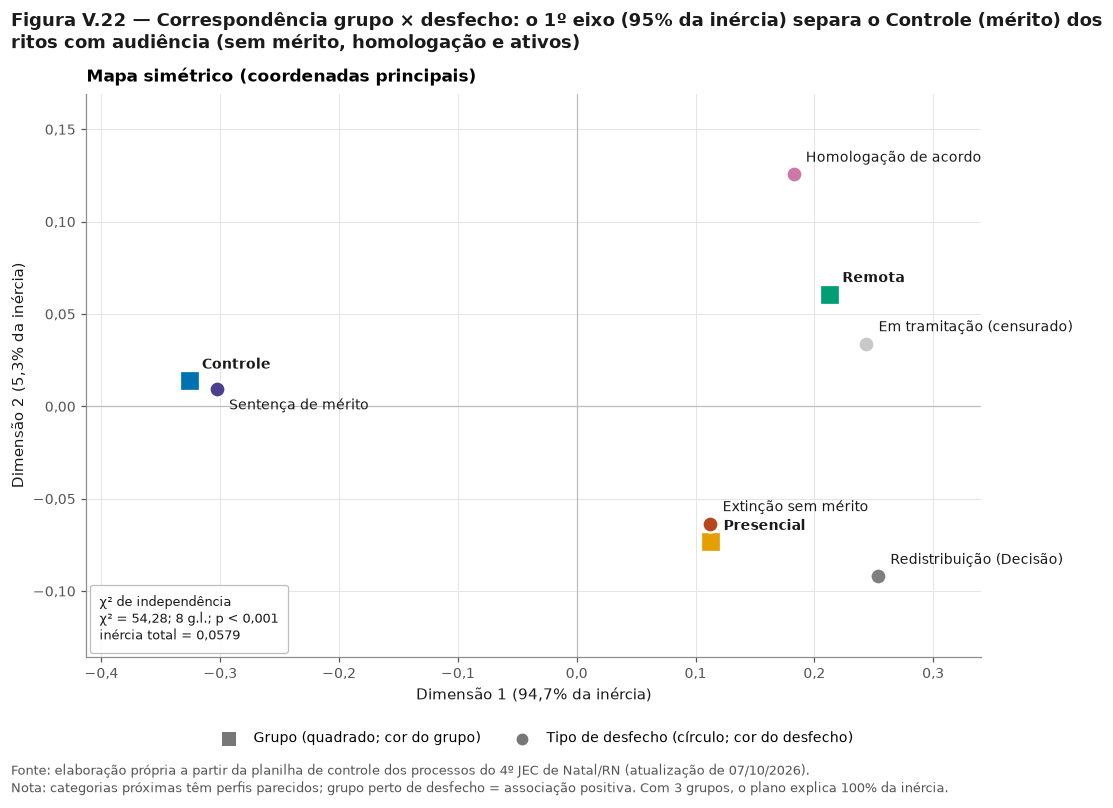

In [49]:
def analise_correspondencia(tabela):
    N = np.asarray(tabela, float)
    n = N.sum(); P = N / n
    r, c = P.sum(1), P.sum(0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, sv, Vt = np.linalg.svd(S, full_matrices=False)
    k = int(np.sum(sv > 1e-12))
    F = (U[:, :k] * sv[:k]) / np.sqrt(r)[:, None]
    G = (Vt.T[:, :k] * sv[:k]) / np.sqrt(c)[:, None]
    inercia = sv[:k] ** 2
    return {'F': F, 'G': G, 'inercia': inercia, 'total': inercia.sum(), 'n': n, 'massa_l': r, 'massa_c': c}

tab_ca = pd.crosstab(mul['grupo'], mul['tipo_desfecho']).reindex(columns=ORDEM_DESFECHO)
ca = analise_correspondencia(tab_ca)
chi2_ca, p_ca, gl_ca, _ = stats.chi2_contingency(tab_ca)
mul_res['ca'] = (ca['inercia'] / ca['total'], chi2_ca, p_ca)
tabela(tab_ca.rename(columns=ROTULO_DESFECHO).rename_axis('Grupo').rename_axis(columns=None), 'mul_ca_tabela',
       'Tabela grupo × tipo de desfecho analisada pela correspondência (processos)', secao='5.4.1',
       nota=f'n = {int(tab_ca.values.sum())} processos (inclui ativos e redistribuídos).')
print(f"Inércia total = {fmt_br(ca['total'], 4)} = χ²/n = {fmt_br(chi2_ca, 2)}/{int(ca['n'])}; χ² ({gl_ca} g.l.) p {p_br(p_ca)}")
for i, v in enumerate(ca['inercia']):
    print(f'  dimensão {i + 1}: inércia {fmt_br(v, 4)} ({pct_br(v / ca["total"])})')

pin = ca['inercia'] / ca['total']
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, g in enumerate(tab_ca.index):
    ax.scatter(ca['F'][i, 0], ca['F'][i, 1], s=170, color=CORES_GRUPO[g], marker='s', zorder=3, edgecolor='white', lw=1.5)
for j, d in enumerate(tab_ca.columns):
    ax.scatter(ca['G'][j, 0], ca['G'][j, 1], s=110, color=CORES_DESFECHO[d], marker='o', zorder=3, edgecolor='white', lw=1.5)
ax.axhline(0, color='#bdbdbd', lw=0.8, zorder=1); ax.axvline(0, color='#bdbdbd', lw=0.8, zorder=1)
ax.grid(axis='both', visible=True)
todos_x = np.r_[ca['F'][:, 0], ca['G'][:, 0]]; todos_y = np.r_[ca['F'][:, 1], ca['G'][:, 1]]
mx, my = np.ptp(todos_x) * 0.15, np.ptp(todos_y) * 0.2
ax.set_xlim(todos_x.min() - mx, todos_x.max() + mx); ax.set_ylim(todos_y.min() - my, todos_y.max() + my)
ax.set(xlabel=f'Dimensão 1 ({pct_br(pin[0])} da inércia)', ylabel=f'Dimensão 2 ({pct_br(pin[1])} da inércia)',
       title='Mapa simétrico (coordenadas principais)')
mul_rotular_pontos(ax, todos_x, todos_y, list(tab_ca.index) + [ROTULO_DESFECHO[d] for d in tab_ca.columns],
                   negrito=[True] * len(tab_ca.index) + [False] * len(tab_ca.columns))
ax.scatter([], [], marker='s', s=80, color='#777777', label='Grupo (quadrado; cor do grupo)')
ax.scatter([], [], marker='o', s=60, color='#777777', label='Tipo de desfecho (círculo; cor do desfecho)')
legenda_abaixo(ax, ncol=2, dy=-0.11)
anotar_teste(ax, texto_teste('χ² de independência', f'χ² = {fmt_br(chi2_ca, 2)}; {gl_ca} g.l.', p_ca,
                             f'inércia total = {fmt_br(ca["total"], 4)}'), loc='lower left')
figura(fig, 'mul_ca_mapa', f'Correspondência grupo × desfecho: o 1º eixo ({pct_br(pin[0], 0)} da inércia) separa o Controle (mérito) '
       'dos ritos com audiência (sem mérito, homologação e ativos)', secao='5.4.1',
       nota='categorias próximas têm perfis parecidos; grupo perto de desfecho = associação positiva. Com 3 grupos, o plano '
            'explica 100% da inércia.')

**Interpretação.** O χ² de independência rejeita H0 (χ² = 54,28; 8 g.l.; p < 0,001), mas a inércia total é pequena (0,058, o que equivale a um V de Cramér ≈ 0,17): a associação é real e moderada-fraca. A **dimensão 1 concentra 94,7%** da inércia e opõe, de um lado, **Controle e Mérito** (que praticamente coincidem no mapa) e, de outro, os dois ritos com audiência obrigatória, próximos de sem mérito, homologação, ativo e redistribuição. A **dimensão 2** (5,3%) distingue os dois tratamentos: a **Remota** fica perto de **homologação** e **ativo** (mais acordos e mais processos ainda em tramitação), e a **Presencial** fica perto de **sem mérito** e **redistribuição**. A análise de correspondência resume, num só gráfico, o que o logit multinomial quantificou: a diferença essencial é "rito atual = julgamento de mérito" contra "audiência obrigatória = desfechos alternativos", e a Remota se diferencia pelos acordos.

### 5.4.2 AC múltipla: grupo × tipo de desfecho × bimestre de distribuição

A AC múltipla (ACM) aplica a mesma decomposição à **matriz indicadora** (uma coluna por categoria de cada variável, 938 linhas). O mês entra agrupado em bimestres (jan-fev, mar-abr, mai-jun, jul-ago) para evitar categorias raras. Na ACM, as inércias brutas subestimam a qualidade da representação; usa-se a **correção de Benzécri**: para Q variáveis, só os autovalores λ > 1/Q contam, e λ* = [Q/(Q − 1)]² (λ − 1/Q)². O objetivo é ver se o eixo "desfecho" e o eixo "calendário" se misturam com o eixo "grupo", ou seja, se o mês confunde a comparação.

Dimensão,Autovalor bruto,Inércia bruta (%),Inércia corrigida de Benzécri (%)
1,"0,5242","17,5","87,2"
2,"0,3912","13,0","8,0"
3,"0,3736","12,5","3,9"
4,"0,3527","11,8","0,9"
5,"0,3298","11,0","0,0"
6,"0,3108","10,4","0,0"


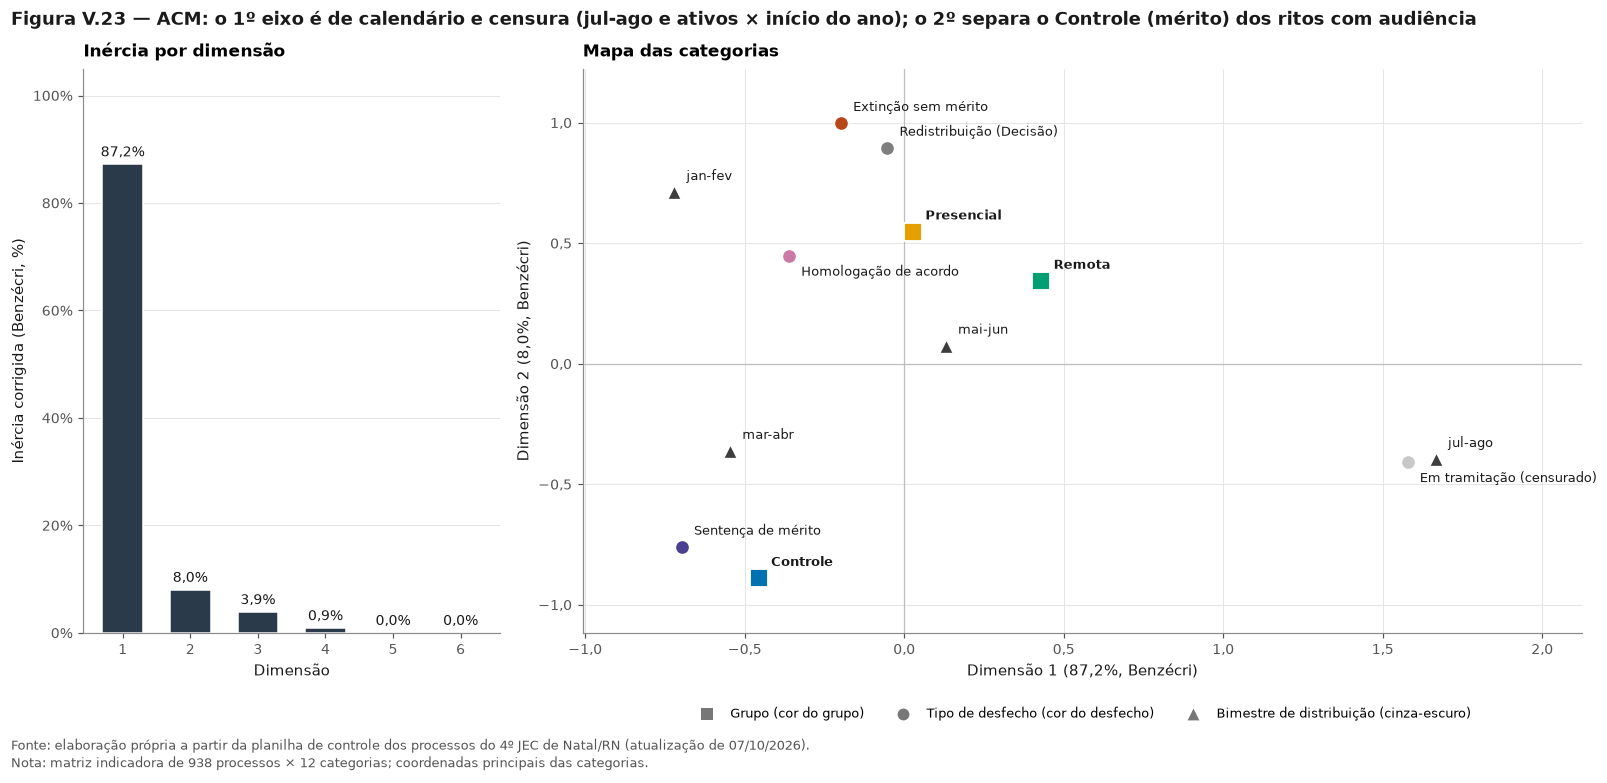

In [50]:
bimestre = pd.cut(mul['mes_num'], [0, 2, 4, 6, 8], labels=['jan-fev', 'mar-abr', 'mai-jun', 'jul-ago'])
vars_acm = pd.DataFrame({'grupo': mul['grupo'].astype(str), 'desfecho': mul['desfecho'], 'bimestre': bimestre.astype(str)})
Z = pd.get_dummies(vars_acm, prefix_sep=': ').astype(float)
acm = analise_correspondencia(Z.values)
Q = vars_acm.shape[1]
lam = acm['inercia']
lam_adj = np.where(lam > 1 / Q, (Q / (Q - 1)) ** 2 * (lam - 1 / Q) ** 2, 0)
pct_adj = lam_adj / lam_adj.sum()
mul_res['acm'] = pct_adj[:2]
tabela(pd.DataFrame({'Dimensão': np.arange(1, len(lam) + 1), 'Autovalor bruto': lam,
                     'Inércia bruta (%)': 100 * lam / lam.sum(), 'Inércia corrigida de Benzécri (%)': 100 * pct_adj}).head(6),
       'mul_acm_inercia', 'ACM grupo × desfecho × bimestre: inércia por dimensão, bruta e com a correção de Benzécri',
       secao='5.4.2', formatos={'Autovalor bruto': 4},
       nota=f'Q = {Q} variáveis; só os autovalores λ > 1/Q contam na correção λ* = [Q/(Q − 1)]²(λ − 1/Q)².')
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 2.4]})
ax = eixos[0]
barras_verticais(ax, [str(k) for k in range(1, 7)], pct_adj[:6], cores=COR_MODELO, rotular=True,
                 fmt=lambda v: pct_br(v, 1), xlabel='Dimensão', ylabel='Inércia corrigida (Benzécri, %)', ymax=1.05)
eixo_pct(ax)
ax.set_title('Inércia por dimensão')
ax = eixos[1]
marc = {'grupo': 's', 'desfecho': 'o', 'bimestre': '^'}
xs, ys, rots, negr = [], [], [], []
for j, col in enumerate(Z.columns):
    var, cat = col.split(': ', 1)
    cor = CORES_GRUPO.get(cat) if var == 'grupo' else (CORES_DESFECHO.get(cat) if var == 'desfecho' else '#3D3D3D')
    ax.scatter(acm['G'][j, 0], acm['G'][j, 1], marker=marc[var], s=150 if var == 'grupo' else 90, color=cor, zorder=3,
               edgecolor='white', lw=1.2)
    xs.append(acm['G'][j, 0]); ys.append(acm['G'][j, 1])
    rots.append(ROTULO_DESFECHO.get(cat, cat) if var == 'desfecho' else cat); negr.append(var == 'grupo')
ax.axhline(0, color='#bdbdbd', lw=0.8, zorder=1); ax.axvline(0, color='#bdbdbd', lw=0.8, zorder=1)
ax.grid(axis='both', visible=True)
mx, my = np.ptp(xs) * 0.12, np.ptp(ys) * 0.12
ax.set_xlim(min(xs) - mx, max(xs) + mx * 1.6); ax.set_ylim(min(ys) - my, max(ys) + my)
ax.set(xlabel=f'Dimensão 1 ({pct_br(pct_adj[0])}, Benzécri)', ylabel=f'Dimensão 2 ({pct_br(pct_adj[1])}, Benzécri)',
       title='Mapa das categorias')
mul_rotular_pontos(ax, xs, ys, rots, tamanho=8.5, negrito=negr)
for var, m, rot in [('grupo', 's', 'Grupo (cor do grupo)'), ('desfecho', 'o', 'Tipo de desfecho (cor do desfecho)'),
                    ('bimestre', '^', 'Bimestre de distribuição (cinza-escuro)')]:
    ax.scatter([], [], marker=m, color='#777777', s=60, label=rot)
legenda_abaixo(ax, ncol=3, dy=-0.11, fontsize=8.5)
figura(fig, 'mul_acm', 'ACM: o 1º eixo é de calendário e censura (jul-ago e ativos × início do ano); '
       'o 2º separa o Controle (mérito) dos ritos com audiência', secao='5.4.2',
       nota=f'matriz indicadora de {len(Z)} processos × {Z.shape[1]} categorias; coordenadas principais das categorias.')

**Interpretação.** Com a correção de Benzécri, a dimensão 1 explica 87,2% da inércia ajustada e a dimensão 2, 8,0%. O **eixo 1 é de calendário e censura**: opõe **jul-ago** e **Ativo** (à direita, praticamente sobrepostos) a jan-fev, mar-abr e aos desfechos encerrados. A principal estrutura da tabela tripla é trivial: quem foi distribuído por último ainda está em tramitação. O **eixo 2 é o do tratamento**: Controle e Mérito embaixo, Presencial, Remota, sem mérito, homologação e redistribuição em cima, a mesma oposição da AC simples. A Remota está deslocada para a direita no eixo 1, em direção a jul-ago e Ativo, porque **julho concentrou a Remota** (67 de 157 distribuições). Na comparação bruta, parte da diferença da Remota (mais ativos) é, portanto, efeito de calendário. É por isso que o mês entra como covariável em todos os modelos desta parte e da Parte IV.

## 5.5 Comparação preditiva dos modelos de tempo com censura

A Parte IV interpretou os coeficientes dos modelos de Cox e AFT. Aqui a pergunta é outra: **quanto esses modelos preveem** o tempo de um processo novo? Comparam-se, com validação cruzada em 10 partes (mesma partição para todos):

| Modelo | Preditores |
|---|---|
| Nulo (Kaplan-Meier marginal) | nenhum; C = 0,5 por definição |
| Cox, só mês | mês |
| Cox, grupo | grupo |
| Cox, grupo + mês | grupo, mês |
| Weibull AFT, grupo + mês | grupo, mês |
| Log-normal AFT, grupo + mês | grupo, mês |

Métricas:

- **índice de concordância de Harrell (C)** fora da amostra (`lifelines.utils.k_fold_cross_validation`, `scoring_method='concordance_index'`): proporção de pares comparáveis em que o processo com menor tempo previsto foi de fato sentenciado antes; 0,5 = acaso, 1 = ordenação perfeita;
- **escore de Brier integrado (IBS)** com pesos pela probabilidade inversa de censura (IPCW, Graf et al., 1999), implementado diretamente: BS(t) = média de Ŝ(t|x)²·1(Tᵢ ≤ t, δᵢ = 1)/Ĝ(Tᵢ⁻) + [1 − Ŝ(t|x)]²·1(Tᵢ > t)/Ĝ(t), em que Ĝ é o Kaplan-Meier da censura estimado no treino **separadamente por mês de distribuição** (a censura administrativa depende do mês: um Ĝ marginal violaria a hipótese de censura independente das covariáveis e penalizaria indevidamente os modelos que usam o mês; agosto unido a julho); IBS = média de BS(t) num intervalo. **Janela identificável:** além do seguimento mínimo (65 dias), os processos dos últimos meses não podem ser observados, e o IPCW não recupera essa massa (Ĝ = 0 nesses estratos). Por isso, calcula-se o IBS em duas janelas em que todos os avaliados foram acompanhados durante todo o intervalo (só a redistribuição censura): **[1, 64] dias com os 938** e **[1, 120] dias com os 688 de seguimento ≥ 120**. Menor é melhor; o nulo é a régua;
- **calibração de Ŝ(90)**: previsões fora da amostra agrupadas em quintis, contra o Kaplan-Meier observado em cada quintil.

Usa-se `tempo_pos` (zeros → 0,5 dia) para que Cox e AFT vejam os mesmos dados; a redistribuição é tratada como censura, como na análise principal da Parte IV.

Modelo,C na amostra,C validação cruzada (média),DP entre as 10 partes
"Cox, só mês","0,555","0,559","0,044"
"Cox, grupo","0,529","0,529","0,033"
"Cox, grupo + mês","0,564","0,566","0,044"
"Weibull AFT, grupo + mês","0,562","0,566","0,043"
"Log-normal AFT, grupo + mês","0,558","0,559","0,043"


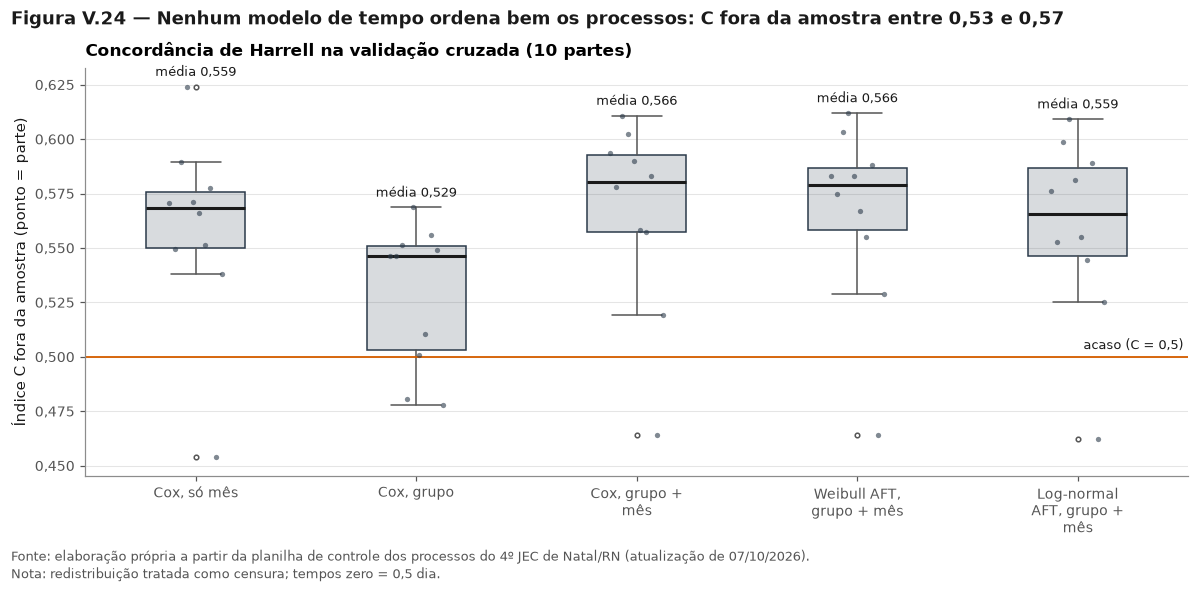

In [51]:
df_s = mul[['T_pos', 'E', 'presencial', 'remota', 'mes_num']].reset_index(drop=True)
MODELOS = {
    'Cox, só mês': (CoxPHFitter, ['mes_num']),
    'Cox, grupo': (CoxPHFitter, ['presencial', 'remota']),
    'Cox, grupo + mês': (CoxPHFitter, ['presencial', 'remota', 'mes_num']),
    'Weibull AFT, grupo + mês': (WeibullAFTFitter, ['presencial', 'remota', 'mes_num']),
    'Log-normal AFT, grupo + mês': (LogNormalAFTFitter, ['presencial', 'remota', 'mes_num']),
}
# (i) concordância por k_fold_cross_validation do lifelines
conc_cv = {}
for nome, (Fit, cols) in MODELOS.items():
    conc_cv[nome] = k_fold_cross_validation(Fit(), df_s[['T_pos', 'E'] + cols], 'T_pos', 'E', k=10,
                                            scoring_method='concordance_index', seed=SEMENTE)
# na amostra toda
conc_in = {}
for nome, (Fit, cols) in MODELOS.items():
    f = Fit().fit(df_s[['T_pos', 'E'] + cols], 'T_pos', 'E')
    conc_in[nome] = f.concordance_index_
tab_conc = pd.DataFrame({'C na amostra': conc_in, 'C validação cruzada (média)': {k: np.mean(v) for k, v in conc_cv.items()},
                         'DP entre as 10 partes': {k: np.std(v, ddof=1) for k, v in conc_cv.items()}}).rename_axis('Modelo')
tabela(tab_conc, 'mul_concordancia', 'Índice de concordância de Harrell (C) dos modelos de tempo, na amostra e fora dela',
       secao='5.5', casas=3, nota='C = 0,5: ordenação ao acaso; 1: ordenação perfeita. Validação cruzada em 10 partes, mesma partição para todos.')
mul_res['conc_cv'] = {k: np.mean(v) for k, v in conc_cv.items()}

fig, ax = plt.subplots(figsize=(11, 4.8))
bp = ax.boxplot(list(conc_cv.values()), positions=range(len(conc_cv)), widths=0.45, patch_artist=True,
                medianprops=dict(color=TINTA, lw=2), whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
for caixa in bp['boxes']:
    caixa.set_facecolor(mpl.colors.to_rgba(COR_MODELO, 0.18)); caixa.set_edgecolor(COR_MODELO)
for k, v in enumerate(conc_cv.values()):
    ax.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, s=12, color=COR_MODELO, alpha=0.6, zorder=3, lw=0)
    ax.annotate(f'média {fmt_br(np.mean(v), 3)}', (k, max(v)), xytext=(0, 5), textcoords='offset points', ha='center',
                va='bottom', fontsize=8.5, color=TINTA)
ax.set_xticks(range(len(conc_cv)), [quebra(k, 14) for k in conc_cv])
ax.axhline(0.5, color=COR_VIES, lw=1.2)
ax.annotate('acaso (C = 0,5)', (1, 0.5), xycoords=('axes fraction', 'data'), xytext=(-3, 3), textcoords='offset points',
            ha='right', va='bottom', fontsize=8.5, color=TINTA)
ax.grid(axis='x', visible=False)
ax.set(ylabel='Índice C fora da amostra (ponto = parte)', title='Concordância de Harrell na validação cruzada (10 partes)')
figura(fig, 'mul_concordancia', 'Nenhum modelo de tempo ordena bem os processos: C fora da amostra entre '
       f'{fmt_br(min(mul_res["conc_cv"].values()), 2)} e {fmt_br(max(mul_res["conc_cv"].values()), 2)}', secao='5.5',
       nota='redistribuição tratada como censura; tempos zero = 0,5 dia.')

**Interpretação.** O índice de concordância fora da amostra é **baixo em todos os modelos**: 0,566 para o Cox com grupo + mês e para o Weibull AFT, 0,559 para o log-normal AFT e para o Cox só com mês, e **0,529 para o Cox só com grupo**. A dispersão entre partes (DP ≈ 0,04) é maior que as diferenças entre modelos, que portanto **não se distinguem**. A concordância na amostra é igual à de validação (0,564 contra 0,566), sinal de que, com tão poucos parâmetros, não há sobreajuste. A comparação mais importante é a do Cox "só mês" (0,559) com o "só grupo" (0,529): o **calendário ordena melhor** os tempos que o rito, mas nenhum dos dois chega perto do que se considera útil para previsão individual (em geral, C ≥ 0,7). Um C de 0,53 para o grupo é compatível com o efeito pequeno (e não significativo) do rito sobre o tempo encontrado na Parte IV.

Modelo,"IBS [1, 64] (938)","DP [1, 64] (938)","Ganho sobre o nulo [1, 64] (938) (%)","IBS [1, 120] (688)","DP [1, 120] (688)","Ganho sobre o nulo [1, 120] (688) (%)"
Nulo (KM),"0,1605","0,0240","0,0","0,2002","0,0148","0,0"
"Cox, só mês","0,1597","0,0236","0,5","0,1982","0,0129","1,0"
"Cox, grupo","0,1609","0,0236","-0,2","0,2002","0,0138","0,0"
"Cox, grupo + mês","0,1601","0,0232","0,3","0,1983","0,0117","1,0"
"Weibull AFT, grupo + mês","0,1681","0,0181","-4,7","0,2060","0,0078","-2,9"
"Log-normal AFT, grupo + mês","0,1817","0,0134","-13,2","0,2161","0,0070","-7,9"


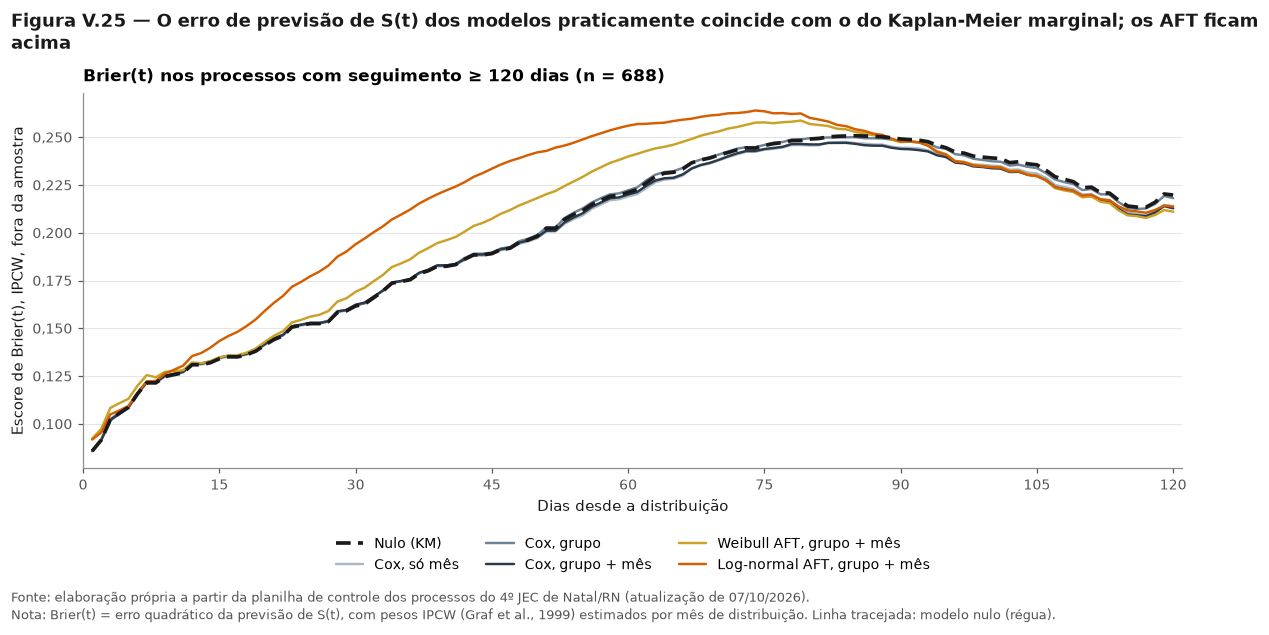

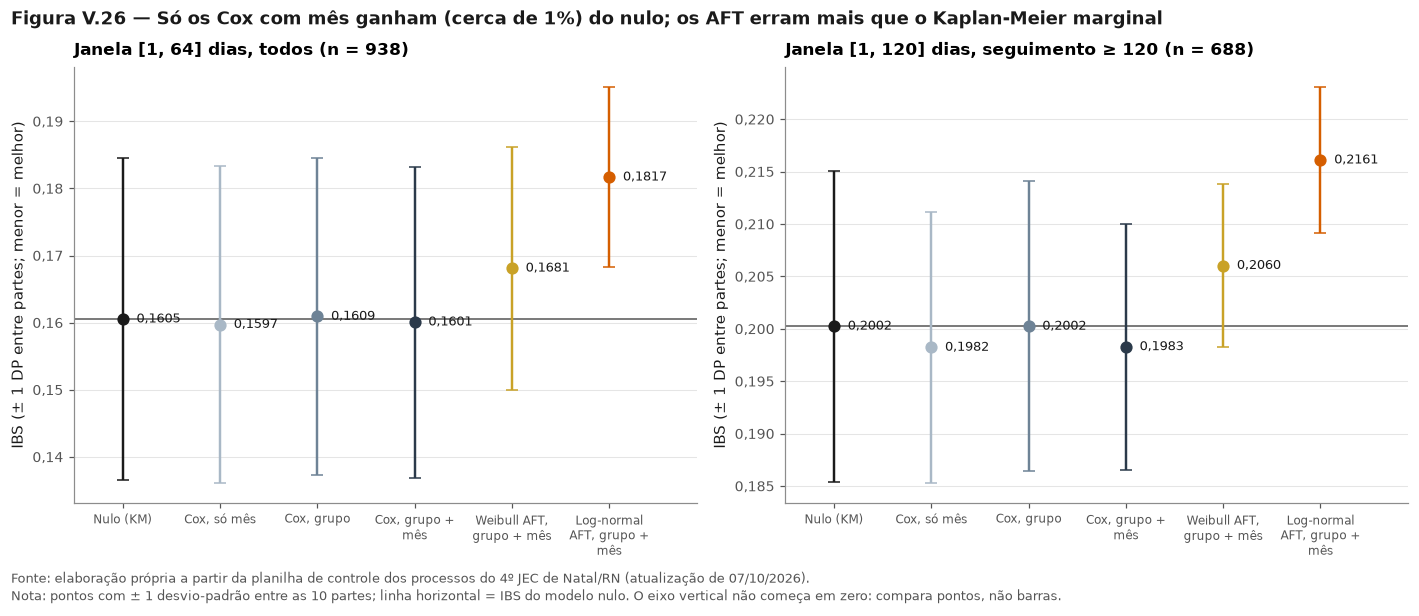

In [52]:
GRADE_T = np.arange(1, 121)
JANELAS = {'IBS [1, 64], todos': (64, None), 'IBS [1, 120], seguimento ≥ 120': (120, 120)}

def brier_ipcw(T, E, S_pred, T_tr, E_tr, est_te, est_tr, grade):
    """Brier(t) com IPCW (Graf et al., 1999), com G estimado por estrato de mês. S_pred: (n_teste × len(grade))."""
    G_t = np.zeros((len(T), len(grade)))
    G_Ti = np.zeros(len(T))
    for e in np.unique(est_te):
        kmG = KaplanMeierFitter().fit(T_tr[est_tr == e], 1 - E_tr[est_tr == e])
        i = est_te == e
        G_t[i] = kmG.survival_function_at_times(grade).values
        G_Ti[i] = kmG.survival_function_at_times(np.maximum(T[i] - 1e-6, 0)).values
    G_t, G_Ti = np.clip(G_t, 0.05, 1), np.clip(G_Ti, 0.05, 1)
    bs = np.zeros(len(grade))
    for j, t in enumerate(grade):
        evento_antes = (T <= t) & (E == 1)
        vivo = T > t
        bs[j] = np.mean(np.where(evento_antes, S_pred[:, j] ** 2 / G_Ti, 0) + np.where(vivo, (1 - S_pred[:, j]) ** 2 / G_t[:, j], 0))
    return bs

fu_s = mul['followup_f'].reset_index(drop=True).values
kf = KFold(10, shuffle=True, random_state=SEMENTE)
NOMES_PRED = ['Nulo (KM)'] + list(MODELOS)
bs_curvas = {jan: {nome: [] for nome in NOMES_PRED} for jan in JANELAS}
s90_oof = {nome: np.full(len(df_s), np.nan) for nome in ['Cox, grupo + mês', 'Log-normal AFT, grupo + mês']}
for tr, te in kf.split(df_s):
    d_tr, d_te = df_s.iloc[tr], df_s.iloc[te]
    T_te, E_te = d_te['T_pos'].values, d_te['E'].values
    est_tr, est_te = np.minimum(d_tr['mes_num'].values, 7), np.minimum(d_te['mes_num'].values, 7)   # ago unido a jul
    km = KaplanMeierFitter().fit(d_tr['T_pos'], d_tr['E'])
    previsoes = {'Nulo (KM)': np.tile(km.survival_function_at_times(GRADE_T).values, (len(te), 1))}
    for nome, (Fit, cols) in MODELOS.items():
        f = Fit().fit(d_tr[['T_pos', 'E'] + cols], 'T_pos', 'E')
        previsoes[nome] = f.predict_survival_function(d_te[cols], times=GRADE_T).values.T
        if nome in s90_oof:
            s90_oof[nome][te] = f.predict_survival_function(d_te[cols], times=[90]).values.ravel()
    for jan, (tau, fu_min) in JANELAS.items():
        m = np.ones(len(te), bool) if fu_min is None else fu_s[te] >= fu_min
        for nome, Sp in previsoes.items():
            bs_curvas[jan][nome].append(brier_ipcw(T_te[m], E_te[m], Sp[m, :tau], d_tr['T_pos'].values, d_tr['E'].values,
                                                   est_te[m], est_tr, GRADE_T[:tau]))
integra = lambda c, tau: np.trapezoid(c, GRADE_T[:tau]) / (tau - 1)
ibs, ibs_dp, bs_medio = {}, {}, {}
for jan, (tau, _) in JANELAS.items():
    bs_medio[jan] = {k: np.mean(v, axis=0) for k, v in bs_curvas[jan].items()}
    ibs[jan] = {k: integra(v, tau) for k, v in bs_medio[jan].items()}
    ibs_dp[jan] = {k: np.std([integra(c, tau) for c in v], ddof=1) for k, v in bs_curvas[jan].items()}
mul_res['ibs'] = ibs
tab_ibs = pd.DataFrame(index=NOMES_PRED).rename_axis('Modelo')
for jan, rot in zip(JANELAS, ['[1, 64] (938)', '[1, 120] (688)']):
    tab_ibs[f'IBS {rot}'] = pd.Series(ibs[jan])
    tab_ibs[f'DP {rot}'] = pd.Series(ibs_dp[jan])
    tab_ibs[f'Ganho sobre o nulo {rot} (%)'] = pd.Series({k: 100 * (1 - v / ibs[jan]['Nulo (KM)']) for k, v in ibs[jan].items()})
tabela(tab_ibs, 'mul_brier', 'Escore de Brier integrado (IBS, IPCW) fora da amostra, em duas janelas identificáveis',
       secao='5.5', casas=4, nota='menor = melhor; ganho > 0 = melhor que o Kaplan-Meier marginal (nulo). Entre colchetes, '
                                  'a janela em dias; entre parênteses, os processos avaliados. DP entre as 10 partes.')

PAL_MOD = {'Nulo (KM)': TINTA, 'Cox, só mês': '#A9B8C6', 'Cox, grupo': '#6E8396', 'Cox, grupo + mês': COR_MODELO,
           'Weibull AFT, grupo + mês': '#C9A227', 'Log-normal AFT, grupo + mês': COR_VIES}
jan2 = 'IBS [1, 120], seguimento ≥ 120'
fig, ax = plt.subplots(figsize=(11, 5))
for k, v in bs_medio[jan2].items():
    ax.plot(GRADE_T, v, label=k, color=PAL_MOD[k], lw=2.4 if k == 'Nulo (KM)' else 1.6,
            ls=(0, (4, 2)) if k == 'Nulo (KM)' else '-', zorder=4 if k == 'Nulo (KM)' else 3)
ax.set(xlabel=ROTULOS['dias'], ylabel='Escore de Brier(t), IPCW, fora da amostra',
       title='Brier(t) nos processos com seguimento ≥ 120 dias (n = 688)', xlim=(0, 121))
ax.set_xticks(np.arange(0, 121, 15))
legenda_abaixo(ax, ncol=3, dy=-0.15)
figura(fig, 'mul_brier_t', 'O erro de previsão de S(t) dos modelos praticamente coincide com o do Kaplan-Meier marginal; '
       'os AFT ficam acima', secao='5.5', nota='Brier(t) = erro quadrático da previsão de S(t), com pesos IPCW (Graf et al., 1999) '
                                            'estimados por mês de distribuição. Linha tracejada: modelo nulo (régua).')

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
titulos_jan = {'IBS [1, 64], todos': 'Janela [1, 64] dias, todos (n = 938)',
               'IBS [1, 120], seguimento ≥ 120': 'Janela [1, 120] dias, seguimento ≥ 120 (n = 688)'}
for ax, jan in zip(eixos, JANELAS):
    v = ibs[jan]
    nomes_m = list(v)
    mul_forest(ax, [v[k] for k in nomes_m], [v[k] - ibs_dp[jan][k] for k in nomes_m],
               [v[k] + ibs_dp[jan][k] for k in nomes_m], cor=[PAL_MOD[k] for k in nomes_m],
               textos=[fmt_br(v[k], 4) for k in nomes_m])
    ax.axhline(v['Nulo (KM)'], color=TINTA_2, lw=1, zorder=1)
    ax.set_xticks(range(len(v)), [quebra(k, 12) for k in nomes_m], fontsize=8)
    ax.set_xlim(-0.5, len(v) - 0.1)
    ax.set(ylabel='IBS (± 1 DP entre partes; menor = melhor)', title=titulos_jan.get(jan, jan))
figura(fig, 'mul_brier_ibs', 'Só os Cox com mês ganham (cerca de 1%) do nulo; os AFT erram mais que o Kaplan-Meier marginal',
       secao='5.5', nota='pontos com ± 1 desvio-padrão entre as 10 partes; linha horizontal = IBS do modelo nulo. '
                         'O eixo vertical não começa em zero: compara pontos, não barras.')

**Interpretação.** O escore de Brier integrado confirma e refina a leitura da concordância:

- na janela **[1, 120] dias** (688 processos com seguimento ≥ 120), o Cox com grupo + mês (0,1983) e o Cox só com mês (0,1982) melhoram o Kaplan-Meier nulo (0,2002) em apenas **1,0%**. O Cox só com grupo empata com o nulo (0,0%). Na janela **[1, 64]** (todos os 938), os ganhos são ainda menores (0,3% a 0,5%);
- os **AFT paramétricos são piores que o nulo**: Weibull −2,9% e log-normal −7,9% em [1, 120] (−4,7% e −13,2% em [1, 64]). Eles ordenam os processos tão bem quanto o Cox (mesmo C), mas suas **curvas de sobrevivência têm a forma errada**. A distribuição empírica tem muita massa de sentenças nos primeiros dias (desistências, incompetência, 39 tempos zero) e depois um bloco entre 60 e 120 dias, o que nenhuma família de dois parâmetros reproduz bem. O Cox, que deixa o risco basal livre, não sofre desse problema.

O IBS só é calculado em janelas em que todos os processos avaliados foram acompanhados durante todo o intervalo. Com um Ĝ marginal e integração até 180 dias, todos os modelos pareceriam piores que o nulo, um artefato da censura administrativa dependente do mês. Por isso se usam Ĝ por mês e janelas identificáveis.

### 5.5.1 Calibração de Ŝ(90)

Cada processo recebeu, fora da amostra, a probabilidade prevista de **continuar sem sentença aos 90 dias**. Agrupam-se as previsões em quintis (empates fazem alguns quintis coincidirem) e compara-se a média prevista com o Kaplan-Meier observado em cada quintil, com IC 95%. Calibração perfeita: pontos sobre a diagonal.

Cox, grupo + mês: amplitude das previsões Ŝ(90) = 0,319 a 0,644; erro absoluto médio de calibração = 0,024
Log-normal AFT, grupo + mês: amplitude das previsões Ŝ(90) = 0,271 a 0,641; erro absoluto médio de calibração = 0,059


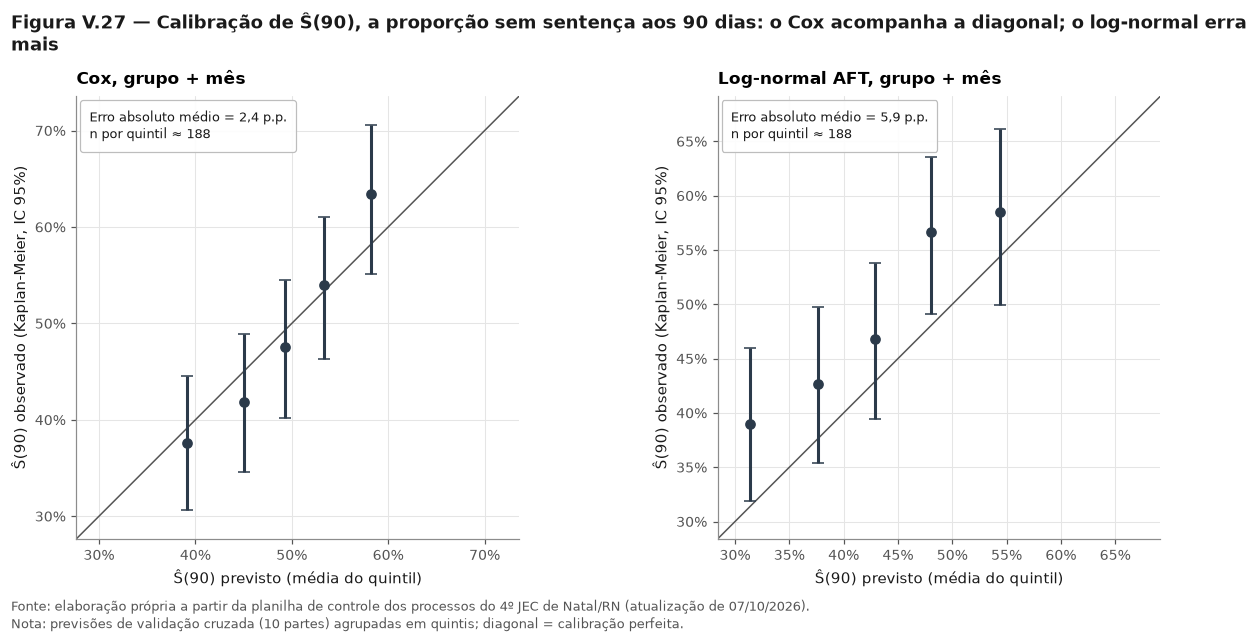

In [53]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
calib = {}
for ax, (nome, s90) in zip(eixos, s90_oof.items()):
    q = pd.qcut(pd.Series(s90).rank(method='first'), 5, labels=False)
    lin = []
    for b in range(5):
        idx = np.where(q == b)[0]
        km = KaplanMeierFitter().fit(df_s['T_pos'].iloc[idx], df_s['E'].iloc[idx])
        obs = km.survival_function_at_times(90).iloc[0]
        ic = km.confidence_interval_survival_function_
        ic_at = ic[ic.index <= 90].iloc[-1]
        lin.append({'quintil': b + 1, 'previsto': s90[idx].mean(), 'observado': obs,
                    'li': ic_at.iloc[0], 'ls': ic_at.iloc[1], 'n': len(idx)})
    t = pd.DataFrame(lin)
    calib[nome] = t
    ax.errorbar(t['previsto'], t['observado'], yerr=[t['observado'] - t['li'], t['ls'] - t['observado']], fmt='o', ms=6,
                capsize=4, color=COR_MODELO, zorder=3)
    lo = min(t['li'].min(), t['previsto'].min()) - 0.03
    hi = max(t['ls'].max(), t['previsto'].max()) + 0.03
    ax.plot([lo, hi], [lo, hi], color=TINTA_2, lw=1, zorder=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel='Ŝ(90) previsto (média do quintil)',
           ylabel='Ŝ(90) observado (Kaplan-Meier, IC 95%)', title=nome)
    ax.set_aspect('equal'); ax.grid(axis='both', visible=True)
    eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
    anotar_teste(ax, f"Erro absoluto médio = {fmt_br(100 * np.mean(np.abs(t['previsto'] - t['observado'])), 1)} p.p.\n"
                     f"n por quintil ≈ {fmt_br(t['n'].mean(), 0)}", loc='upper left')
    print(f"{nome}: amplitude das previsões Ŝ(90) = {fmt_br(s90.min(), 3)} a {fmt_br(s90.max(), 3)}; "
          f"erro absoluto médio de calibração = {fmt_br(np.mean(np.abs(t['previsto'] - t['observado'])), 3)}")
mul_res['calib'] = calib
figura(fig, 'mul_calib_s90', 'Calibração de Ŝ(90), a proporção sem sentença aos 90 dias: o Cox acompanha a diagonal; '
       'o log-normal erra mais', secao='5.5.1',
       nota='previsões de validação cruzada (10 partes) agrupadas em quintis; diagonal = calibração perfeita.')

**Interpretação.** O Cox com grupo + mês é **bem calibrado** para Ŝ(90): os cinco quintis ficam sobre a diagonal, com erro absoluto médio de 0,024, e todos os IC cruzam a diagonal. O log-normal AFT **subestima sistematicamente** a probabilidade de continuar sem sentença aos 90 dias (pontos acima da diagonal; erro médio de 0,059), isto é, prevê mais sentenças até 90 dias do que ocorrem, coerente com a forma inadequada vista no Brier. As previsões do Cox variam de 0,32 a 0,64, e essa amplitude vem quase toda do mês. O modelo informa bem a **média** de cada combinação grupo × mês, mas não ordena os processos dentro dela.

**Conclusão de 5.5.** Entre os modelos que tratam a censura, o **Cox com grupo + mês** é o que melhor **descreve** os dados (concordância máxima, melhor Brier, melhor calibração) e é o modelo de referência para a estimativa dos efeitos do rito (Parte IV). O Weibull AFT é uma alternativa aceitável para comunicar razões de tempos, com pior calibração, e o log-normal deve ser evitado para previsão. O poder preditivo de **todos** é baixo (C ≈ 0,57; ganho de Brier ≈ 1%), e isso não é falha de especificação: o banco não tem covariáveis do caso, e o experimento foi desenhado para uma **comparação causal entre grupos**, que o sorteio torna válida sem precisar explicar a variabilidade individual.

## 5.6 Síntese da Parte V

A tabela reúne os modelos ajustados, a métrica de desempenho de cada um e o que dizem sobre a pergunta de pesquisa. Os números são lidos diretamente dos resultados acima.

In [54]:
cA = mul_res['contA'].set_index('Contraste')
rrr_t = mul_res['mnl'][0].set_index(['Equação', 'Termo'])
sint = pd.DataFrame([
    {'Seção': '5.1', 'Modelo': 'OLS tempo ~ grupo + mês (sentenciados)', 'Desempenho': f"R² = {fmt_br(mul_res['ols_r2'], 3)}",
     'Leitura': 'inadequado: ignora censura, resíduos não normais e heterocedásticos'},
    {'Seção': '5.2.1', 'Modelo': 'Logit acordo ~ grupo + mês (encerrados)',
     'Desempenho': f"AUC VC = {fmt_br(mul_res['aucA'][2], 3)}; McFadden = {fmt_br(mul_res['A']['mcfadden'], 3)}",
     'Leitura': f"Remota × Controle RC = {fmt_br(cA.loc['Remota vs Controle', 'RC'], 2)} (p Holm {p_br(cA.loc['Remota vs Controle', 'p Holm'])}); TRV grupo p {p_br(mul_res['A']['trv_p'])}"},
    {'Seção': '5.2.6', 'Modelo': 'Logit acordo na AC ~ modalidade + híbrida + mês',
     'Desempenho': f"AUC = {fmt_br(mul_res['AC'][1], 3)} (na amostra)",
     'Leitura': f"TRV p {p_br(mul_res['AC'][0]['res'].llr_pvalue)}; 17 eventos, exploratório"},
    {'Seção': '5.2.7', 'Modelo': 'MNLogit tipo de sentença ~ grupo + mês',
     'Desempenho': f"McFadden = {fmt_br(mul_res['mnl'][3], 3)}",
     'Leitura': f"TRV grupo p {p_br(mul_res['mnl'][2])}; sem mérito vs mérito: RRR Presencial {fmt_br(rrr_t.loc[('Sem mérito vs Mérito', 'Presencial vs Controle'), 'RRR'], 2)}, Remota {fmt_br(rrr_t.loc[('Sem mérito vs Mérito', 'Remota vs Controle'), 'RRR'], 2)}"},
    {'Seção': '5.3.1', 'Modelo': 'Árvore tipo de sentença (basais)',
     'Desempenho': f"acurácia balanceada VC = {pct_br(mul_res['arvA'][2])} (trivial 33,3%)", 'Leitura': f"{mul_res['arvA'][0]} folhas"},
    {'Seção': '5.3.2', 'Modelo': 'Árvore tipo de sentença (tratados, com AC realizada)',
     'Desempenho': f"acurácia balanceada VC = {pct_br(mul_res['arvB'][2])}", 'Leitura': f"{mul_res['arvB'][0]} folhas; AC realizada é a variável dominante (associação, não causa)"},
    {'Seção': '5.3.4', 'Modelo': 'Árvore de sobrevivência (martingal)',
     'Desempenho': f"R² VC ≈ {fmt_br(mul_res['arvS'][1], 3)}", 'Leitura': f"{mul_res['arvS'][0]} folhas"},
    {'Seção': '5.4', 'Modelo': 'AC grupo × desfecho', 'Desempenho': f"dim. 1 = {pct_br(mul_res['ca'][0][0])} da inércia",
     'Leitura': f"χ² p {p_br(mul_res['ca'][2])}"},
    {'Seção': '5.5', 'Modelo': 'Cox grupo + mês', 'Desempenho': f"C VC = {fmt_br(mul_res['conc_cv']['Cox, grupo + mês'], 3)}; IBS[1,120] = {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Cox, grupo + mês'], 4)} (nulo {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Nulo (KM)'], 4)})",
     'Leitura': 'melhor descrição do efeito de grupo com censura; previsão individual fraca'},
    {'Seção': '5.5', 'Modelo': 'Log-normal AFT grupo + mês', 'Desempenho': f"C VC = {fmt_br(mul_res['conc_cv']['Log-normal AFT, grupo + mês'], 3)}; IBS[1,120] = {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Log-normal AFT, grupo + mês'], 4)}",
     'Leitura': 'mesma ordenação que o Cox, mas forma de S(t) errada: Brier pior que o nulo e Ŝ(90) mal calibrado'},
])
tabela(sint, 'mul_sintese', 'Síntese dos modelos da Parte V: desempenho e o que dizem sobre a pergunta de pesquisa',
       secao='5.6', nota='AUC = área sob a curva ROC; VC = validação cruzada; C = índice de concordância de Harrell; '
                         'IBS = escore de Brier integrado (menor = melhor).')

Seção,Modelo,Desempenho,Leitura
5.1,OLS tempo ~ grupo + mês (sentenciados),"R² = 0,024","inadequado: ignora censura, resíduos não normais e heterocedásticos"
5.2.1,Logit acordo ~ grupo + mês (encerrados),"AUC VC = 0,546; McFadden = 0,015","Remota × Controle RC = 2,15 (p Holm 0,027); TRV grupo p 0,027"
5.2.6,Logit acordo na AC ~ modalidade + híbrida + mês,"AUC = 0,618 (na amostra)","TRV p 0,475; 17 eventos, exploratório"
5.2.7,MNLogit tipo de sentença ~ grupo + mês,"McFadden = 0,028","TRV grupo p < 0,001; sem mérito vs mérito: RRR Presencial 2,37, Remota 2,46"
5.3.1,Árvore tipo de sentença (basais),"acurácia balanceada VC = 38,5% (trivial 33,3%)",7 folhas
5.3.2,"Árvore tipo de sentença (tratados, com AC realizada)","acurácia balanceada VC = 57,1%","2 folhas; AC realizada é a variável dominante (associação, não causa)"
5.3.4,Árvore de sobrevivência (martingal),"R² VC ≈ -0,010",1 folhas
5.4,AC grupo × desfecho,"dim. 1 = 94,7% da inércia","χ² p < 0,001"
5.5,Cox grupo + mês,"C VC = 0,566; IBS[1,120] = 0,1983 (nulo 0,2002)",melhor descrição do efeito de grupo com censura; previsão individual fraca
5.5,Log-normal AFT grupo + mês,"C VC = 0,559; IBS[1,120] = 0,2161","mesma ordenação que o Cox, mas forma de S(t) errada: Brier pior que o nulo e Ŝ(90) mal calibrado"


**O que a Parte V acrescenta.**

1. **A regressão linear sobre o tempo é inadequada** (5.1). Ela inverte o efeito do mês e muda a direção do efeito do rito. Com censura, a regressão deve ser feita com Cox ou AFT; o AFT log-normal mostrou um **aumento de ~20% no tempo típico por mês de distribuição** (acúmulo de acervo), invisível nas análises que ignoram a censura.
2. **Acordo**: a audiência **remota** obrigatória associa-se a cerca do **dobro da chance de acordo** em relação ao rito atual (RC = 2,15 entre os encerrados; RC = 2,70 até 120 dias, sem viés de seguimento; p Holm ≤ 0,03). A Presencial fica entre a Remota e o Controle, sem diferença significativa. A vantagem não está no acordo **na** audiência (cerca de 5% nas duas modalidades), e sim nos acordos posteriores.
3. **Tipo de sentença**: é o efeito mais forte e robusto. Os ritos com audiência obrigatória têm cerca de 2,4 vezes a chance de sentença **sem mérito** em vez de mérito, e a Remota tem cerca de 3 vezes a de **homologação**. Nos tratados, quase toda extinção sem mérito ocorre quando a audiência **não se realizou** (83%), o que é compatível com o art. 51, I, da Lei 9.099/1995, sob a cautela de causalidade reversa.
4. **Previsão**: todos os modelos, de classificação ou de tempo, têm poder preditivo individual **baixo** (AUC ≈ 0,55 fora da amostra; C ≈ 0,57; ganho de Brier ≈ 1%), e as árvores não acham partições estáveis. Entre os modelos de tempo, o **Cox com grupo + mês** descreve e prevê melhor; os AFT paramétricos têm a forma de S(t) errada.

**Recomendações de variáveis a coletar numa replicação (questão 2.9).** A modelagem multivariada útil exige covariáveis **basais do caso**, registradas na distribuição, antes do sorteio:

| Variável | Escala | Uso esperado |
|---|---|---|
| Valor da causa (R$) | razão (contínua) | covariável no Cox/AFT; correlação com o tempo via Cox com covariável contínua ou Spearman/Kendall restritos a horizonte fixo |
| Número de autores e de réus | discreta (contagem) | covariável; complexidade do litígio |
| Tipo de ação / assunto (TPU-CNJ) | nominal | estrato no Cox; heterogeneidade do efeito do rito |
| Réu pessoa jurídica / litigante habitual (banco, telefonia, varejo) | binária ou nominal | o principal preditor conhecido de acordo em JEC; efeito aleatório por litigante |
| Advogado constituído × *jus postulandi* (cada polo) | binária | ausência do autor, acordo e extinção |
| Pedido de tutela de urgência | binária | tramitação prioritária |
| Datas intermediárias: citação, designação e realização da AC, contestação, conclusão para sentença | datas | decomposição do tempo em etapas (modelos multiestado) e covariáveis dependentes do tempo, sem viés de tempo imortal |
| Motivo da não realização da AC e fundamento da sentença sem mérito (art. 51, I; art. 485 CPC) | nominal | testar diretamente o mecanismo da extinção por ausência |
| Número de atos da serventia e do juiz | contagem | medir carga de trabalho; cuidado, porque cresce com o tempo de tramitação (é mediador e consequência, não covariável basal) |

Com variáveis quantitativas desse tipo, a correlação com a duração **não** deve ser medida por Pearson ou Spearman sobre tempos censurados. O adequado é um **Cox com a covariável contínua** (teste de Wald ou TRV; HR por unidade) ou, para associação de postos, o índice de concordância de Harrell. As covariáveis basais também aumentariam a **precisão** das estimativas dos efeitos do rito (ajuste por covariáveis prognósticas num ensaio aleatorizado) e permitiriam verificar o balanceamento do sorteio, o que hoje só é possível para o mês.